# Rock-Paper-Scissors Image Processing and Machine Learning

**A Reproducible Computer Vision Pipeline from Image Processing to Deep Learning**

This single notebook contains the complete project (Lessons 1–20). Run it **from top to bottom** in a fresh kernel.

**Dataset:** Kaggle `drgfreeman/rockpaperscissors` (`paper` = 0, `rock` = 1, `scissors` = 2), downloaded with KaggleHub. The dataset is not stored in the repository.

## Contents

| Part | Lesson |
|---|---|
| 0 | Project setup (writes the reusable `src/` modules) |
| 1 | Data loading and EDA, permanent split |
| 2 | Image processing |
| 3 | Traditional ML with HOG |
| 4 | ANN |
| 5 | Baseline CNN |
| 6 | CNN with augmentation |
| 7 | Transfer learning (MobileNetV2) |
| 8 | CNN + HOG hybrid |
| 9 | Model explainability (Grad-CAM) |
| 10 | Reproducible pipeline |
| 11 | Ablation study |
| 12 | Manual hyperparameter tuning |
| 13 | KerasTuner |
| 14 | Augmentation experiment |
| 15 | Evaluation and statistics |
| 16 | Cross-validation |
| 17 | Error analysis |
| 18 | Model comparison |
| 19 | Final locked experiment |
| 20 | Final results and report |

## Methodological rules

* One permanent stratified 70/15/15 split (`RANDOM_STATE = 42`), saved to `results/metrics/dataset_split.csv`.
* Preprocessing objects are fitted on training data only; augmentation is applied to training data only.
* Models are compared and tuned on the **validation** set. The test set is used for the final evaluation in Lesson 19 (Lesson 14 also computes one test row for its selected augmentation model, which is not used for any decision).
* No results are pre-computed: every number is produced when the cells are executed.

**Practical notes:** save this notebook inside a `notebooks/` folder (paths such as `../results/` and `../src/` are relative to it). The full run trains many models; a GPU is recommended. Lesson 7 downloads ImageNet weights, and Kaggle access may require credentials.

# Part 0 — Project Setup

The reusable modules are written to `../src/` so that the notebook is fully self-contained and the project can be reused as a regular Python package. The cells below create the folders and write the four modules.

In [1]:
import os

for directory in ("../src", "../results/figures", "../results/metrics", "../results/features", "../results/models"):
    os.makedirs(directory, exist_ok=True)

In [2]:
%%writefile ../src/__init__.py
"""Reusable modules for the Rock-Paper-Scissors image processing and machine learning project."""

Writing ../src/__init__.py


In [3]:
%%writefile ../src/preprocessing.py
"""Dataset discovery, splitting, image loading and normalisation utilities."""

import hashlib
import os

import cv2
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

# Supported image file extensions
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

# Global random seed used for every reproducible operation
RANDOM_STATE = 42

# Class labels and their fixed integer encoding (do not change)
CLASS_NAMES = [
    "paper",
    "rock",
    "scissors",
]

CLASS_TO_INDEX = {
    "paper": 0,
    "rock": 1,
    "scissors": 2,
}

# Keyword arguments for each augmentation strategy (used with ImageDataGenerator)
AUGMENTATION_KWARGS = {
    "No Augmentation": None,
    "Rotation": {"rotation_range": 25},
    "Translation": {"width_shift_range": 0.15, "height_shift_range": 0.15},
    "Zoom": {"zoom_range": 0.20},
    "Horizontal Flip": {"horizontal_flip": True},
    "Combined": {
        "rotation_range": 15,
        "width_shift_range": 0.10,
        "height_shift_range": 0.10,
        "zoom_range": 0.10,
        "horizontal_flip": True,
    },
}


def find_dataset_root(dataset_path, class_names=CLASS_NAMES):
    """Return the first directory (in sorted walk order) that directly contains all class folders."""
    candidates = []
    for current_directory, sub_directories, _ in os.walk(dataset_path):
        sub_directories.sort()
        if all(class_name in sub_directories for class_name in class_names):
            candidates.append(current_directory)

    if not candidates:
        raise FileNotFoundError("Class folders were not found inside the dataset path.")

    if len(candidates) > 1:
        print("Multiple candidate dataset roots found; using the first one:")
        for candidate in candidates:
            print("  -", candidate)

    return candidates[0]


def create_image_dataframe(dataset_root, class_names=CLASS_NAMES):
    """Create a DataFrame with the columns relative_path, label and label_index."""
    records = []
    for class_name in class_names:
        class_directory = os.path.join(dataset_root, class_name)
        for file_name in sorted(os.listdir(class_directory)):
            if os.path.splitext(file_name)[1].lower() in IMAGE_EXTENSIONS:
                records.append(
                    {
                        "relative_path": f"{class_name}/{file_name}",
                        "label": class_name,
                        "label_index": CLASS_TO_INDEX[class_name],
                    }
                )
    return pd.DataFrame(records, columns=["relative_path", "label", "label_index"])


def compute_md5(file_path):
    """Return the MD5 hash of a file."""
    digest = hashlib.md5()
    with open(file_path, "rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def remove_invalid_and_duplicate_images(image_dataframe, dataset_root):
    """Drop unreadable images and exact byte-level duplicates (first occurrence is kept)."""
    keep_mask = []
    seen_hashes = set()
    n_corrupted, n_duplicates = 0, 0

    for relative_path in image_dataframe["relative_path"]:
        full_path = os.path.join(dataset_root, relative_path)
        try:
            with Image.open(full_path) as image:
                image.verify()
        except Exception:
            n_corrupted += 1
            keep_mask.append(False)
            continue

        file_hash = compute_md5(full_path)
        if file_hash in seen_hashes:
            n_duplicates += 1
            keep_mask.append(False)
        else:
            seen_hashes.add(file_hash)
            keep_mask.append(True)

    print(f"Removed corrupted images: {n_corrupted}")
    print(f"Removed exact duplicates: {n_duplicates}")
    return image_dataframe[np.array(keep_mask)].reset_index(drop=True)


def create_dataset_split(image_dataframe, random_state=RANDOM_STATE):
    """Create a stratified 70/15/15 train/validation/test split."""
    train_df, temporary_df = train_test_split(
        image_dataframe,
        test_size=0.30,
        stratify=image_dataframe["label"],
        random_state=random_state,
    )
    validation_df, test_df = train_test_split(
        temporary_df,
        test_size=0.50,
        stratify=temporary_df["label"],
        random_state=random_state,
    )

    split_dataframe = pd.concat(
        [
            train_df.assign(split="train"),
            validation_df.assign(split="validation"),
            test_df.assign(split="test"),
        ]
    )
    return split_dataframe.sort_values("relative_path").reset_index(drop=True)


def save_dataset_split(split_dataframe, output_path):
    """Save the dataset split to CSV, creating the directory if required."""
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    split_dataframe.to_csv(output_path, index=False)


def get_split_dataframe(dataset_path, split_path="../results/metrics/dataset_split.csv"):
    """Load the permanent split if it exists; otherwise create it once and save it.

    Returns the dataset root directory and the split DataFrame.
    """
    dataset_root = find_dataset_root(dataset_path)

    if os.path.exists(split_path):
        split_dataframe = pd.read_csv(split_path)
        print(f"Loaded permanent split from {split_path}")
    else:
        image_dataframe = create_image_dataframe(dataset_root)
        image_dataframe = remove_invalid_and_duplicate_images(image_dataframe, dataset_root)
        split_dataframe = create_dataset_split(image_dataframe)
        save_dataset_split(split_dataframe, split_path)
        print(f"Created and saved permanent split to {split_path}")

    return dataset_root, split_dataframe


def get_partition(split_dataframe, split_name):
    """Return the rows belonging to one partition: 'train', 'validation' or 'test'."""
    return split_dataframe[split_dataframe["split"] == split_name].reset_index(drop=True)


def load_images(dataset_root, relative_paths, image_size=(128, 128)):
    """Load images as an RGB uint8 array of shape (N, height, width, 3).

    image_size is given as (width, height).
    """
    images = []
    for relative_path in relative_paths:
        with Image.open(os.path.join(dataset_root, relative_path)) as image:
            rgb_array = np.array(image.convert("RGB"))
        images.append(cv2.resize(rgb_array, image_size, interpolation=cv2.INTER_AREA))
    return np.stack(images).astype(np.uint8)


def normalize_images(images):
    """Scale uint8 pixel values to float32 values in the range [0, 1]."""
    return images.astype("float32") / 255.0

Writing ../src/preprocessing.py


In [4]:
%%writefile ../src/feature_extraction.py
"""Handcrafted feature extraction (Histogram of Oriented Gradients)."""

import cv2
import numpy as np
from skimage.feature import hog

HOG_PARAMETERS = {
    "orientations": 9,
    "pixels_per_cell": (8, 8),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
}


def extract_hog_features(images, image_size=(128, 128)):
    """Extract HOG features from RGB (or grayscale) uint8 images.

    Each image is resized to image_size (width, height), converted to grayscale
    and described with the HOG parameters defined in HOG_PARAMETERS.
    Returns a float32 array of shape (N, n_features).
    """
    feature_list = []
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
        gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY) if resized.ndim == 3 else resized
        feature_list.append(hog(gray, **HOG_PARAMETERS))
    return np.asarray(feature_list, dtype="float32")

Writing ../src/feature_extraction.py


In [5]:
%%writefile ../src/models.py
"""Reusable Keras model builders."""

import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential, layers, optimizers


def set_seed(seed=42):
    """Set Python, NumPy and TensorFlow random seeds."""
    tf.keras.utils.set_random_seed(seed)


def _get_optimizer(name, learning_rate):
    """Return an optimizer instance from its name."""
    optimizer_map = {
        "adam": optimizers.Adam,
        "rmsprop": optimizers.RMSprop,
        "sgd": optimizers.SGD,
    }
    return optimizer_map[name.lower()](learning_rate=learning_rate)


def build_ann(input_dim, hidden_units=(256, 128), dropout_rates=(0.30, 0.30),
              num_classes=3, learning_rate=1e-3, optimizer="adam"):
    """Fully connected network for flattened images."""
    model = Sequential(name="ann")
    model.add(Input(shape=(input_dim,)))
    for units, rate in zip(hidden_units, dropout_rates):
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(rate))
    model.add(layers.Dense(num_classes, activation="softmax"))
    model.compile(
        optimizer=_get_optimizer(optimizer, learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_cnn(input_shape=(128, 128, 3), filters=(32, 64, 128), dense_units=128,
              dropout_rate=0.40, use_batch_norm=False, num_classes=3,
              learning_rate=1e-3, optimizer="adam"):
    """Convolutional network with three convolution/pooling blocks."""
    model = Sequential(name="cnn")
    model.add(Input(shape=input_shape))
    for index, n_filters in enumerate(filters, start=1):
        model.add(layers.Conv2D(n_filters, (3, 3), activation="relu", name=f"conv_{index}"))
        if use_batch_norm:
            model.add(layers.BatchNormalization(name=f"bn_{index}"))
        model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(dense_units, activation="relu", name="feature_dense"))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(num_classes, activation="softmax"))
    model.compile(
        optimizer=_get_optimizer(optimizer, learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_cnn_feature_extractor(trained_cnn, layer_name="feature_dense"):
    """Return a model that outputs the activations of an intermediate layer of a trained CNN."""
    return Model(
        inputs=trained_cnn.inputs,
        outputs=trained_cnn.get_layer(layer_name).output,
        name="cnn_feature_extractor",
    )


def build_hybrid_classifier(input_dim, num_classes=3, learning_rate=1e-3):
    """Dense classifier for concatenated CNN and HOG features."""
    model = Sequential(name="hybrid_classifier")
    model.add(Input(shape=(input_dim,)))
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.40))
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.30))
    model.add(layers.Dense(num_classes, activation="softmax"))
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_mobilenetv2(input_shape=(224, 224, 3), dense_units=128, dropout_rate=0.40,
                      num_classes=3, learning_rate=1e-3, weights="imagenet"):
    """MobileNetV2 transfer-learning model. Returns (model, base_model).

    The input is expected to be preprocessed with mobilenet_v2.preprocess_input.
    """
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape, include_top=False, weights=weights
    )
    base_model.trainable = False

    inputs = Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = Model(inputs, outputs, name="mobilenetv2_classifier")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model, base_model

Writing ../src/models.py


In [6]:
%%writefile ../src/evaluation.py
"""Evaluation metrics, statistics, result saving and Grad-CAM utilities."""

import os
import time

import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    classification_report as sk_classification_report,
    precision_recall_fscore_support,
)

CLASS_NAMES = ["paper", "rock", "scissors"]


def calculate_metrics(y_true, y_pred):
    """Return accuracy plus weighted and macro precision, recall and F1."""
    metrics = {"accuracy": accuracy_score(y_true, y_pred)}
    for average in ("weighted", "macro"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        metrics[f"precision_{average}"] = precision
        metrics[f"recall_{average}"] = recall
        metrics[f"f1_{average}"] = f1
    return metrics


def classification_report(y_true, y_pred, class_names=CLASS_NAMES, output_dict=False):
    """Wrapper around the scikit-learn classification report."""
    return sk_classification_report(
        y_true, y_pred, labels=list(range(len(class_names))),
        target_names=class_names, output_dict=output_dict, zero_division=0,
    )


def confusion_matrix(y_true, y_pred, num_classes=3):
    """Confusion matrix with rows = true class and columns = predicted class."""
    return sk_confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))


def per_class_metrics(y_true, y_pred, class_names=CLASS_NAMES):
    """Per-class precision, recall, F1 and support as a DataFrame."""
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(len(class_names))), zero_division=0
    )
    return pd.DataFrame(
        {"class": class_names, "precision": precision, "recall": recall,
         "f1": f1, "support": support}
    )


def build_results_row(model_name, split_name, y_true, y_pred, parameter_count=None,
                      training_time_sec=None, inference_time_ms_per_image=None):
    """Create a one-row results DataFrame in the format shared by all notebooks."""
    row = {"model": model_name, "evaluation_split": split_name}
    row.update(calculate_metrics(y_true, y_pred))
    row["parameter_count"] = parameter_count
    row["training_time_sec"] = training_time_sec
    row["inference_time_ms_per_image"] = inference_time_ms_per_image
    return pd.DataFrame([row])


def save_metrics(dataframe, output_path):
    """Save a metrics DataFrame to CSV, creating the directory if required."""
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    dataframe.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")


def plot_confusion_matrix(cm, class_names=CLASS_NAMES, ax=None, title="Confusion Matrix"):
    """Plot a confusion matrix with annotated counts."""
    import matplotlib.pyplot as plt

    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
    threshold = cm.max() / 2.0 if cm.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black")
    return ax


def confidence_summary(probabilities, y_true, high_confidence_threshold=0.90):
    """Summarise prediction confidence for correct and incorrect predictions."""
    y_pred = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)
    correct = y_pred == np.asarray(y_true)
    return {
        "mean_confidence": float(confidence.mean()),
        "mean_confidence_correct": float(confidence[correct].mean()) if correct.any() else np.nan,
        "mean_confidence_incorrect": float(confidence[~correct].mean()) if (~correct).any() else np.nan,
        "n_incorrect": int((~correct).sum()),
        "n_high_confidence_errors": int(((~correct) & (confidence >= high_confidence_threshold)).sum()),
        "high_confidence_threshold": high_confidence_threshold,
    }


def bootstrap_accuracy_ci(y_true, y_pred, n_bootstrap=1000, confidence_level=0.95, random_state=42):
    """Percentile bootstrap confidence interval for accuracy (resampling evaluation examples)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(random_state)
    n_samples = len(y_true)
    accuracies = np.empty(n_bootstrap)
    for index in range(n_bootstrap):
        sample_indices = rng.integers(0, n_samples, n_samples)
        accuracies[index] = (y_true[sample_indices] == y_pred[sample_indices]).mean()
    lower_q = (1 - confidence_level) / 2 * 100
    upper_q = (1 + confidence_level) / 2 * 100
    return accuracies.mean(), np.percentile(accuracies, lower_q), np.percentile(accuracies, upper_q), accuracies


def find_last_conv_layer(model):
    """Return the name of the last Conv2D layer in a model."""
    import tensorflow as tf

    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("The model has no Conv2D layer.")


def make_gradcam_heatmap(image_batch, model, last_conv_layer_name, class_index=None):
    """Compute a Grad-CAM heatmap (values in [0, 1]) for a batch containing one image.

    The layers of the (sequential) model are applied one by one so that the
    activations of the chosen convolutional layer can be captured.
    """
    import tensorflow as tf

    activations = tf.convert_to_tensor(image_batch)
    with tf.GradientTape() as tape:
        conv_output = None
        for layer in model.layers:
            activations = layer(activations, training=False)
            if layer.name == last_conv_layer_name:
                conv_output = activations
        predictions = activations
        if class_index is None:
            class_index = int(tf.argmax(predictions[0]))
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_output)
    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.squeeze(conv_output[0] @ channel_weights[..., tf.newaxis])
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(image_uint8, heatmap, alpha=0.40):
    """Overlay a Grad-CAM heatmap on an RGB uint8 image."""
    heatmap_resized = cv2.resize(heatmap, (image_uint8.shape[1], image_uint8.shape[0]))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(image_uint8, 1 - alpha, heatmap_color, alpha, 0)


def measure_inference_time(predict_function, data):
    """Return the average inference time in milliseconds per example."""
    start_time = time.perf_counter()
    predict_function(data)
    return (time.perf_counter() - start_time) * 1000.0 / len(data)


def save_history(history, output_path):
    """Save a Keras History object as a CSV file (one row per epoch)."""
    history_dataframe = pd.DataFrame(history.history)
    history_dataframe.index = history_dataframe.index + 1
    history_dataframe.index.name = "epoch"
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    history_dataframe.to_csv(output_path)
    return history_dataframe


def plot_training_history(history_dataframe, title="Training History"):
    """Plot loss and accuracy curves from a history DataFrame."""
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    for axis, metric in zip(axes, ("loss", "accuracy")):
        axis.plot(history_dataframe.index, history_dataframe[metric], label=f"train {metric}")
        if f"val_{metric}" in history_dataframe:
            axis.plot(history_dataframe.index, history_dataframe[f"val_{metric}"], label=f"validation {metric}")
        axis.set_xlabel("Epoch")
        axis.set_ylabel(metric.capitalize())
        axis.legend()
        axis.grid(alpha=0.3)
    figure.suptitle(title)
    plt.tight_layout()
    plt.show()

Writing ../src/evaluation.py


# Part 1 — Data Loading and Exploratory Data Analysis

## Learning Objectives

* Download the dataset with KaggleHub and inspect its structure
* Build an image DataFrame and examine class balance
* Inspect image dimensions, channels, pixel values and data types
* Compute brightness, contrast and RGB statistics
* Detect corrupted images, duplicate paths and exact duplicate images (MD5)
* Save image metadata and create the permanent stratified 70/15/15 split

In [7]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

20

## 1. Imports

In [8]:
import os
import sys

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    RANDOM_STATE,
    compute_md5,
    create_image_dataframe,
    find_dataset_root,
    get_partition,
    get_split_dataframe,
)

RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

## 2. Download the Dataset and Inspect its Structure

In [9]:
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Locate the directory that directly contains the class folders
dataset_root = find_dataset_root(dataset_path)
print("Dataset root:", dataset_root)

# Summarise the folder structure (files per directory)
for current_directory, sub_directories, file_names in os.walk(dataset_path):
    if file_names:
        relative = os.path.relpath(current_directory, dataset_path)
        print(f"{relative}: {len(file_names)} files")

Mounting files to /kaggle/input/datasets/drgfreeman/rockpaperscissors...
Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Dataset root: /kaggle/input/datasets/drgfreeman/rockpaperscissors
.: 1 files
paper: 712 files
rock: 726 files
rps-cv-images: 1 files
rps-cv-images/paper: 712 files
rps-cv-images/rock: 726 files
rps-cv-images/scissors: 750 files
scissors: 750 files


## 3. Image DataFrame and Class Distribution

Total number of images: 2188


,count,percentage
label,,
paper,712,32.54
rock,726,33.18
scissors,750,34.28


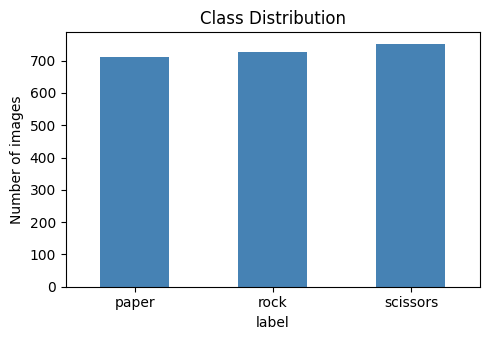

In [10]:
image_df = create_image_dataframe(dataset_root)
image_df["full_path"] = image_df["relative_path"].apply(lambda p: os.path.join(dataset_root, p))

print("Total number of images:", len(image_df))

class_counts = image_df["label"].value_counts().reindex(CLASS_NAMES)
class_percentages = (class_counts / len(image_df) * 100).round(2)
display(pd.DataFrame({"count": class_counts, "percentage": class_percentages}))

class_counts.plot(kind="bar", color="steelblue", figsize=(5, 3.5), title="Class Distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Sample Visualisation

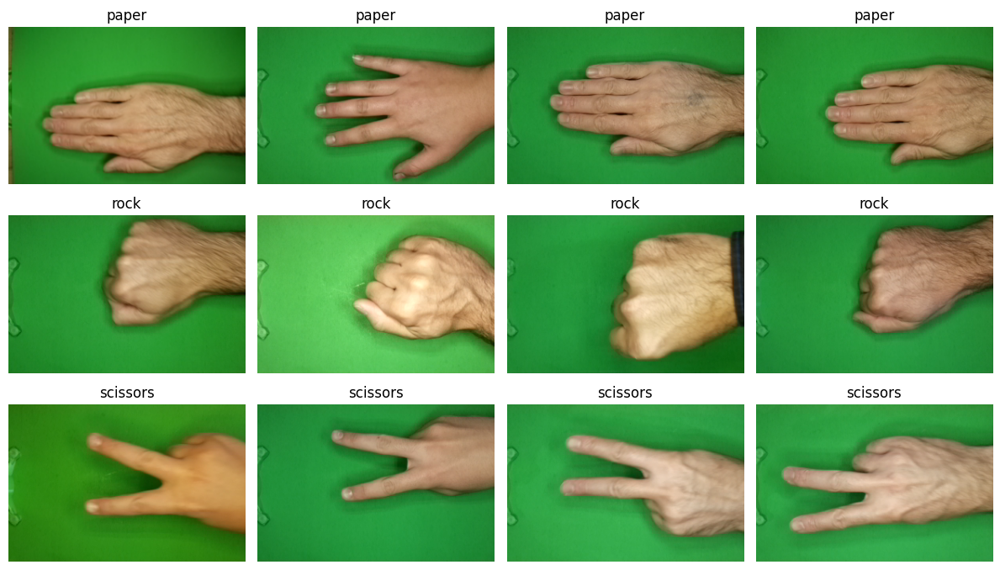

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
for row_index, class_name in enumerate(CLASS_NAMES):
    samples = image_df[image_df["label"] == class_name].sample(4, random_state=RANDOM_STATE)
    for axis, path in zip(axes[row_index], samples["full_path"]):
        axis.imshow(Image.open(path).convert("RGB"))
        axis.set_title(class_name)
        axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Pixel Values, Channels, Data Type and Grayscale

A colour image is an array of shape `(height, width, channels)`. Each RGB channel stores intensities as `uint8` integers from 0 to 255. Grayscale conversion collapses the three channels into a single intensity channel.

Shape (RGB): (200, 300, 3)
Shape (grayscale): (200, 300)
Data type: uint8
Pixel value range: 0 to 216
Top-left 2x2 pixel block (R, G, B):
[[[ 37 122  45]
  [ 37 122  45]]

 [[ 33 120  43]
  [ 34 121  44]]]


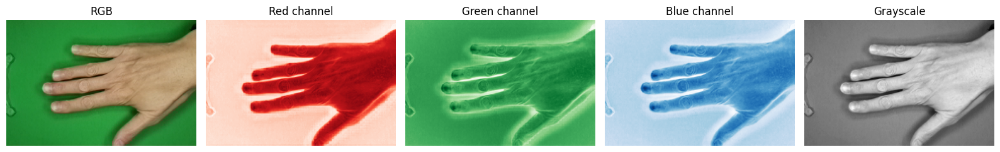

In [12]:
sample_path = image_df.sample(1, random_state=RANDOM_STATE).iloc[0]["full_path"]
sample_rgb = np.array(Image.open(sample_path).convert("RGB"))
sample_gray = cv2.cvtColor(sample_rgb, cv2.COLOR_RGB2GRAY)

print("Shape (RGB):", sample_rgb.shape)
print("Shape (grayscale):", sample_gray.shape)
print("Data type:", sample_rgb.dtype)
print("Pixel value range:", sample_rgb.min(), "to", sample_rgb.max())
print("Top-left 2x2 pixel block (R, G, B):")
print(sample_rgb[:2, :2])

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(sample_rgb); axes[0].set_title("RGB")
for index, (channel_name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")], start=1):
    axes[index].imshow(sample_rgb[:, :, index - 1], cmap=cmap)
    axes[index].set_title(f"{channel_name} channel")
axes[4].imshow(sample_gray, cmap="gray"); axes[4].set_title("Grayscale")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 6. Metadata Extraction

For every image the following are recorded: dimensions, mode, number of channels, file size, aspect ratio, brightness (mean grayscale intensity), contrast (standard deviation of grayscale intensity), per-channel RGB mean and standard deviation, MD5 hash and a corruption flag. A grayscale histogram is also stored for each image.

In [13]:
metadata_records = []
gray_histograms = []

for _, row in image_df.iterrows():
    record = {"relative_path": row["relative_path"], "label": row["label"], "corrupted": False}
    histogram = np.zeros(256)
    try:
        with Image.open(row["full_path"]) as image:
            record.update(
                width=image.width,
                height=image.height,
                mode=image.mode,
                n_channels=len(image.getbands()),
                file_format=image.format,
            )
            rgb = np.array(image.convert("RGB"))
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        record.update(
            file_size_kb=os.path.getsize(row["full_path"]) / 1024,
            aspect_ratio=record["width"] / record["height"],
            dtype=str(rgb.dtype),
            brightness=float(gray.mean()),
            contrast=float(gray.std()),
            mean_r=float(rgb[:, :, 0].mean()), mean_g=float(rgb[:, :, 1].mean()), mean_b=float(rgb[:, :, 2].mean()),
            std_r=float(rgb[:, :, 0].std()), std_g=float(rgb[:, :, 1].std()), std_b=float(rgb[:, :, 2].std()),
            md5=compute_md5(row["full_path"]),
        )
        histogram = np.bincount(gray.ravel(), minlength=256)
    except Exception as error:
        record["corrupted"] = True
        record["error"] = str(error)
    metadata_records.append(record)
    gray_histograms.append(histogram)

metadata_df = pd.DataFrame(metadata_records)
gray_histograms = np.array(gray_histograms)
display(metadata_df.head())

,relative_path,label,corrupted,width,height,mode,n_channels,file_format,file_size_kb,aspect_ratio,dtype,brightness,contrast,mean_r,mean_g,mean_b,std_r,std_g,std_b,md5
0,paper/04l5I8TqdzF9WDMJ.png,paper,False,300,200,RGB,3,PNG,83.386719,1.5,uint8,139.486467,26.263072,118.590550,160.885617,84.019117,64.223582,24.938724,29.783139,52d7b81cffb337ffcd8e7c59baf675fa
1,paper/0Og76sl5CJhbxWWx.png,paper,False,300,200,RGB,3,PNG,67.415039,1.5,uint8,108.609083,37.109464,94.094767,126.346683,55.421833,72.701142,26.257486,40.054962,db076010f144fdb9a727a1792fb73099
2,paper/0RA9rcrv8iVvuDDU.png,paper,False,300,200,RGB,3,PNG,81.112305,1.5,uint8,144.156233,20.734384,122.407433,166.828567,84.855533,57.224863,27.544063,23.685726,123e05f495ddde7475f8e6dc8762f3b9
3,paper/0Uomd0HvOB33m47I.png,paper,False,300,200,RGB,3,PNG,77.754883,1.5,uint8,110.229617,21.068334,80.413783,134.180483,65.156800,59.929959,18.834797,23.082255,3d08d3fd484c9e9ced53c61984910d0d
4,paper/0a3UtNzl5Ll3sq8K.png,paper,False,300,200,RGB,3,PNG,82.163086,1.5,uint8,114.242967,31.947184,94.763717,133.281667,67.425017,71.566473,20.962322,33.770804,1262ccba71452ac4fead832058848a97


## 7. Image Dimensions and Aspect Ratio

In [14]:
valid_df = metadata_df[~metadata_df["corrupted"]]

print("Image sizes (width x height):")
display(valid_df.groupby(["width", "height"]).size().rename("count").reset_index())
print("Colour modes:", valid_df["mode"].value_counts().to_dict())
print("Number of channels:", valid_df["n_channels"].value_counts().to_dict())
print("Data types:", valid_df["dtype"].value_counts().to_dict())
display(valid_df["aspect_ratio"].describe().to_frame().T)

Image sizes (width x height):


,width,height,count
0,300,200,2188


Colour modes: {'RGB': 2188}
Number of channels: {3: 2188}
Data types: {'uint8': 2188}


,count,mean,std,min,25%,50%,75%,max
aspect_ratio,2188.0,1.5,0.0,1.5,1.5,1.5,1.5,1.5


## 8. Intensity Histograms

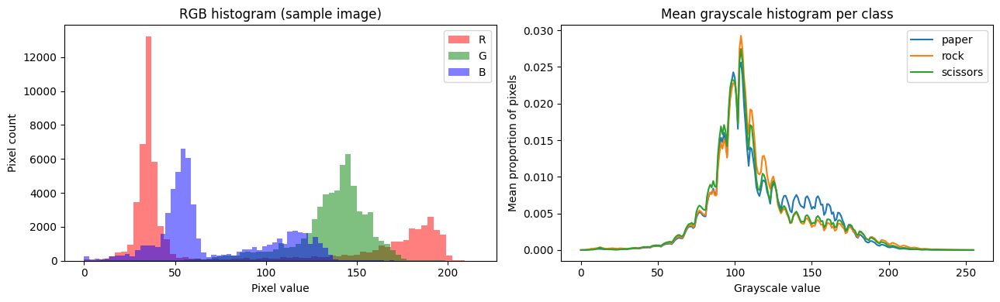

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Per-channel histogram of the sample image
for channel_index, (color, name) in enumerate([("red", "R"), ("green", "G"), ("blue", "B")]):
    axes[0].hist(sample_rgb[:, :, channel_index].ravel(), bins=64, color=color, alpha=0.5, label=name)
axes[0].set_title("RGB histogram (sample image)")
axes[0].set_xlabel("Pixel value"); axes[0].set_ylabel("Pixel count"); axes[0].legend()

# Mean grayscale histogram per class (normalised per image)
valid_mask = ~metadata_df["corrupted"].to_numpy()
for class_name in CLASS_NAMES:
    class_mask = (metadata_df["label"] == class_name).to_numpy() & valid_mask
    class_histograms = gray_histograms[class_mask]
    class_histograms = class_histograms / class_histograms.sum(axis=1, keepdims=True)
    axes[1].plot(class_histograms.mean(axis=0), label=class_name)
axes[1].set_title("Mean grayscale histogram per class")
axes[1].set_xlabel("Grayscale value"); axes[1].set_ylabel("Mean proportion of pixels"); axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Brightness, Contrast and RGB Statistics

* **Brightness** is the mean grayscale intensity.
* **Contrast** is the standard deviation of grayscale intensity.

brightness        contrast       mean_r         mean_g        mean_b  \
               mean    std     mean   std   mean    std    mean    std   mean   
label                                                                           
paper        116.12  10.39    27.94  6.51  90.39  12.70  138.56  11.15  68.22   
rock         113.86   9.72    28.64  8.00  78.74  11.48  141.02  10.85  66.25   
scissors     113.17  10.10    28.45  6.48  78.19  11.37  140.45  11.42  64.58   

                 std_r        std_g        std_b        
            std   mean   std   mean   std   mean   std  
label                                                   
paper     14.09  65.68  6.73  21.56  4.55  30.08  6.51  
rock      13.92  62.03  8.39  24.21  6.61  30.01  7.71  
scissors  13.98  62.31  7.48  22.18  4.66  29.88  6.68

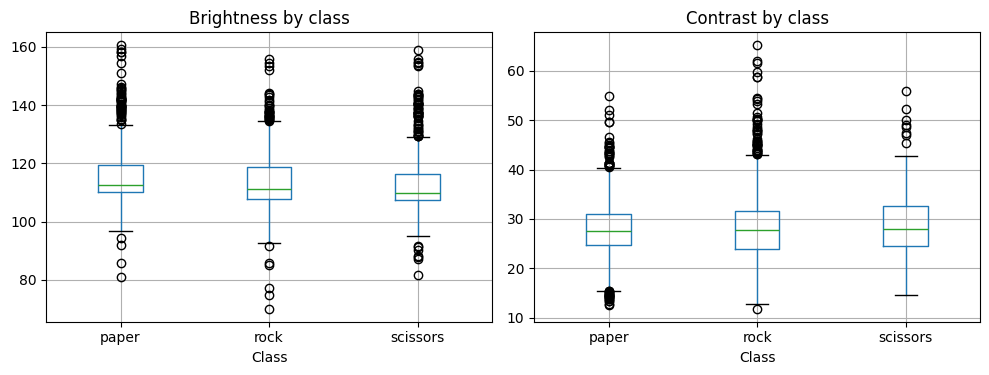

In [16]:
summary_columns = ["brightness", "contrast", "mean_r", "mean_g", "mean_b", "std_r", "std_g", "std_b"]
display(valid_df.groupby("label")[summary_columns].agg(["mean", "std"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
valid_df.boxplot(column="brightness", by="label", ax=axes[0]); axes[0].set_title("Brightness by class")
valid_df.boxplot(column="contrast", by="label", ax=axes[1]); axes[1].set_title("Contrast by class")
for axis in axes:
    axis.set_xlabel("Class")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 10. Data Quality: Corrupted Files, Duplicate Paths and Exact Duplicates

Exact duplicates (identical MD5 hashes) matter because the same image could otherwise appear in both the training and the test partitions, inflating evaluation results. Only byte-identical files are detected here; near-duplicates are not.

In [17]:
n_corrupted = int(metadata_df["corrupted"].sum())
n_duplicate_paths = int(image_df["relative_path"].duplicated().sum())

duplicate_mask = valid_df["md5"].duplicated(keep=False)
duplicate_groups = valid_df[duplicate_mask].sort_values("md5")

print("Corrupted images:", n_corrupted)
print("Duplicate file paths:", n_duplicate_paths)
print("Images belonging to exact-duplicate groups:", len(duplicate_groups))
print("Number of exact-duplicate groups:", duplicate_groups["md5"].nunique())

if len(duplicate_groups) > 0:
    display(duplicate_groups[["relative_path", "label", "md5"]])

Corrupted images: 0
Duplicate file paths: 0
Images belonging to exact-duplicate groups: 0
Number of exact-duplicate groups: 0


## 11. Save Image Metadata

In [18]:
metadata_df.to_csv(f"{RESULTS_DIR}/image_metadata.csv", index=False)
print("Saved:", f"{RESULTS_DIR}/image_metadata.csv")
print("Metadata shape:", metadata_df.shape)

Saved: ../results/image_metadata.csv
Metadata shape: (2188, 20)


## 12. Permanent Stratified Split (70% / 15% / 15%)

Corrupted files and exact duplicates are removed, and the remaining images are split **once** with stratification on the class label (`RANDOM_STATE = 42`). The split is saved to `results/metrics/dataset_split.csv`, and every later notebook loads this same file instead of creating a new split. If the file already exists it is loaded unchanged, so the split stays permanent.

* **Training set:** fits models and preprocessing objects.
* **Validation set:** used for model comparison, tuning and selection.
* **Test set:** reserved for final evaluation.

In [19]:
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

print("Total images in split:", len(split_df))
display(pd.crosstab(split_df["split"], split_df["label"], margins=True)[CLASS_NAMES + ["All"]])
display((pd.crosstab(split_df["split"], split_df["label"], normalize="index") * 100).round(2))

# Verify that the partitions are disjoint
partition_sets = [set(get_partition(split_df, name)["relative_path"]) for name in ("train", "validation", "test")]
assert not (partition_sets[0] & partition_sets[1]), "Train and validation overlap"
assert not (partition_sets[0] & partition_sets[2]), "Train and test overlap"
assert not (partition_sets[1] & partition_sets[2]), "Validation and test overlap"
print("Partitions are disjoint.")

Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Removed corrupted images: 0
Removed exact duplicates: 0
Created and saved permanent split to ../results/metrics/dataset_split.csv
Total images in split: 2188


label,paper,rock,scissors,All
split,,,,
test,107,109,113,329
train,498,508,525,1531
validation,107,109,112,328
All,712,726,750,2188


label,paper,rock,scissors
split,,,
test,32.52,33.13,34.35
train,32.53,33.18,34.29
validation,32.62,33.23,34.15


Partitions are disjoint.


## Conclusions

* The dataset structure, class balance, image dimensions, channel layout and data type were inspected using values computed above.
* Data-quality checks (corrupted files, duplicate paths, exact MD5 duplicates) were run; their counts are printed in Section 10.
* Metadata was saved to `results/image_metadata.csv` and the permanent stratified split to `results/metrics/dataset_split.csv`.
* **Next:** Lesson 2 teaches classical image processing operations.

# Part 2 — Image Processing

**Project:** Rock-Paper-Scissors Image Processing and Machine Learning

This notebook introduces the fundamental image processing operations used to prepare and analyse images before machine learning. Each operation is explained, applied to a sample image from the `rock` class, and visualised.

**Dataset:** [`drgfreeman/rockpaperscissors`](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors) (classes: `paper`, `rock`, `scissors`), downloaded with KaggleHub. The dataset is not stored in this repository.

**Contents**

1. Import libraries
2. Download and load the dataset
3. Create the image DataFrame
4. Select a sample image
5. Original image
6. Image resizing
7. Image cropping
8. Image rotation
9. Horizontal flip
10. Grayscale conversion
11. Gaussian blur
12. Median filtering
13. Binary thresholding
14. Otsu thresholding
15. Sobel edge detection
16. Canny edge detection
17. Morphological operations
18. Complete image processing pipeline

In [20]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

33910

## 1. Import Libraries

In [21]:
# Standard library
import os

# Third-party libraries
import cv2
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## 2. Download and Load the Dataset

The dataset is downloaded through KaggleHub and cached locally by the library. The notebook only stores the path returned by KaggleHub.

In [22]:
# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)

print("Dataset path:", dataset_path)

# Class labels and random seed used throughout the notebook
CLASS_NAMES = ["paper", "rock", "scissors"]
RANDOM_STATE = 42

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors


## 3. Create the Image DataFrame

The dataset directory is searched for the folder that contains the three class sub-folders. Every supported image file in those sub-folders is recorded with its path and class label.

In [23]:
# Supported image file extensions
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# Locate the directory that directly contains all class folders
dataset_root = None
for current_directory, sub_directories, _ in os.walk(dataset_path):
    sub_directories.sort()
    if all(class_name in sub_directories for class_name in CLASS_NAMES):
        dataset_root = current_directory
        break

if dataset_root is None:
    raise FileNotFoundError("Class folders were not found inside the dataset path.")

print("Dataset root:", dataset_root)

# Collect image paths and labels
records = []
for class_name in CLASS_NAMES:
    class_directory = os.path.join(dataset_root, class_name)
    for file_name in sorted(os.listdir(class_directory)):
        if file_name.lower().endswith(VALID_EXTENSIONS):
            records.append(
                {
                    "image_path": os.path.join(class_directory, file_name),
                    "label": class_name,
                }
            )

image_dataframe = pd.DataFrame(records, columns=["image_path", "label"])

# Summarise the dataset
print("Total number of images:", len(image_dataframe))
print("\nClass distribution:")
print(image_dataframe["label"].value_counts().reindex(CLASS_NAMES))

image_dataframe.head()

Dataset root: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Total number of images: 2188

Class distribution:
label
paper       712
rock        726
scissors    750
Name: count, dtype: int64


,image_path,label
0,/kaggle/input/datasets/drgfreeman/rockpapersci...,paper
1,/kaggle/input/datasets/drgfreeman/rockpapersci...,paper
2,/kaggle/input/datasets/drgfreeman/rockpapersci...,paper
3,/kaggle/input/datasets/drgfreeman/rockpapersci...,paper
4,/kaggle/input/datasets/drgfreeman/rockpapersci...,paper


## 4. Select a Sample Image

One image is selected at random from the `rock` class. The fixed random state makes the selection reproducible. The image is loaded with PIL, converted to RGB, and represented as a NumPy array.

In [24]:
# Select one reproducible random image from the 'rock' class
sample_row = (
    image_dataframe[image_dataframe["label"] == "rock"]
    .sample(n=1, random_state=RANDOM_STATE)
    .iloc[0]
)

print("Selected image:", sample_row["image_path"])
print("Class:", sample_row["label"])

# Load with PIL and convert to RGB
pil_image = Image.open(sample_row["image_path"]).convert("RGB")

# Convert to a NumPy array (height, width, channels)
original_image = np.array(pil_image)

print("Image shape:", original_image.shape)
print("Image data type:", original_image.dtype)

Selected image: /kaggle/input/datasets/drgfreeman/rockpaperscissors/rock/QPdZme1zmTH0NIlM.png
Class: rock
Image shape: (200, 300, 3)
Image data type: uint8


In [25]:
# Helper function for consistent single-image display
def show_image(image, title, cmap=None):
    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()

## 5. Original Image

A digital colour image is a 3-D array of shape `(height, width, channels)`. In RGB, the three channels store red, green, and blue intensities, typically as `uint8` values from 0 to 255.

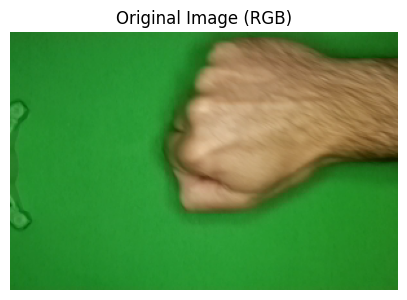

In [26]:
show_image(original_image, "Original Image (RGB)")

## 6. Image Resizing

Machine learning models generally require inputs of a uniform size. Resizing changes the spatial dimensions of an image; here the image is resized to 128 × 128 pixels with OpenCV. Note that `cv2.resize` expects the size as `(width, height)`.

Original shape: (200, 300, 3)
Resized shape: (128, 128, 3)


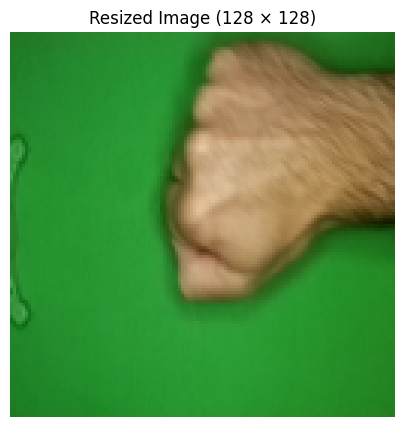

In [27]:
# Resize to 128 x 128 pixels
resized_image = cv2.resize(original_image, (128, 128), interpolation=cv2.INTER_AREA)

print("Original shape:", original_image.shape)
print("Resized shape:", resized_image.shape)

show_image(resized_image, "Resized Image (128 × 128)")

## 7. Image Cropping

Cropping selects a sub-region of the image using NumPy slicing. A center crop retains the central region, which often contains the main subject, and removes the borders.

Cropped shape: (100, 150, 3)


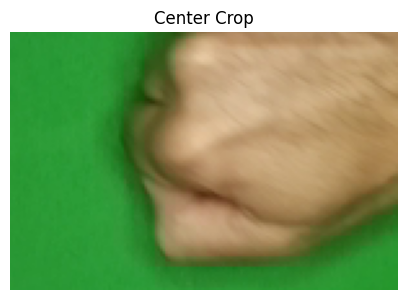

In [28]:
# Center crop: keep the central half of the height and width
height, width = original_image.shape[:2]
crop_height, crop_width = height // 2, width // 2

top = (height - crop_height) // 2
left = (width - crop_width) // 2

cropped_image = original_image[top:top + crop_height, left:left + crop_width]

print("Cropped shape:", cropped_image.shape)

show_image(cropped_image, "Center Crop")

## 8. Image Rotation

Rotation is an affine transformation. OpenCV builds a 2×3 rotation matrix with `cv2.getRotationMatrix2D` and applies it with `cv2.warpAffine`. Areas outside the original image are filled with black.

Rotation matrix:
[[  0.8660254    0.5        -29.90381057]
 [ -0.5          0.8660254   88.39745962]]


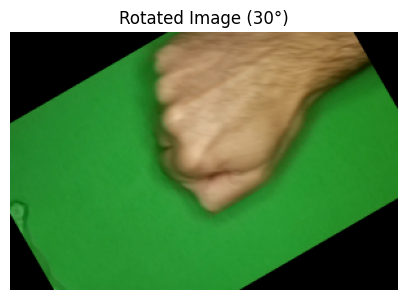

In [29]:
# Rotate by 30 degrees around the image center
rotation_center = (width // 2, height // 2)
rotation_matrix = cv2.getRotationMatrix2D(rotation_center, 30, 1.0)

rotated_image = cv2.warpAffine(original_image, rotation_matrix, (width, height))

print("Rotation matrix:")
print(rotation_matrix)

show_image(rotated_image, "Rotated Image (30°)")

## 9. Horizontal Flip

A horizontal flip mirrors the image along its vertical axis. `cv2.flip(image, 1)` flips horizontally.

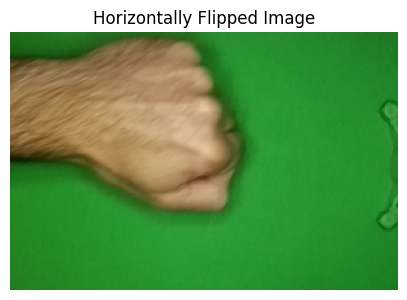

In [30]:
flipped_image = cv2.flip(original_image, 1)

show_image(flipped_image, "Horizontally Flipped Image")

## 10. Grayscale Conversion

An RGB image contains **three channels**, whereas a grayscale image contains a **single intensity channel**. Grayscale conversion reduces the data by a factor of three and is the usual starting point for thresholding and edge detection.

RGB shape: (200, 300, 3)
Grayscale shape: (200, 300)
Grayscale value range: 20 to 205


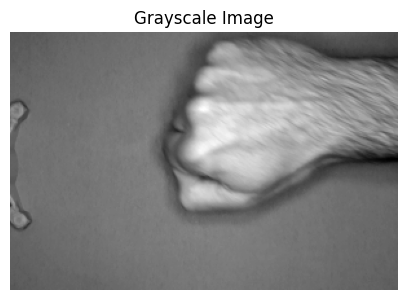

In [31]:
gray_image = cv2.cvtColor(original_image, cv2.COLOR_RGB2GRAY)

print("RGB shape:", original_image.shape)
print("Grayscale shape:", gray_image.shape)
print("Grayscale value range:", gray_image.min(), "to", gray_image.max())

show_image(gray_image, "Grayscale Image", cmap="gray")

## 11. Gaussian Blur

Gaussian blur smooths an image by averaging neighbouring pixels with Gaussian weights. Smoothing suppresses noise and fine detail, which makes subsequent operations such as thresholding and edge detection more stable.

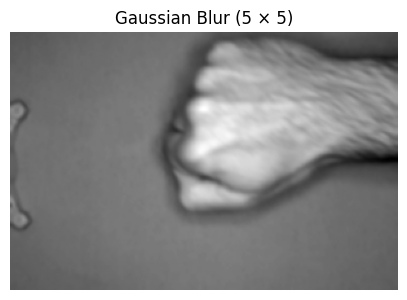

In [32]:
gaussian_blur_image = cv2.GaussianBlur(gray_image, (5, 5), 0)

show_image(gaussian_blur_image, "Gaussian Blur (5 × 5)", cmap="gray")

## 12. Median Filtering

A median filter replaces each pixel with the median of its neighbourhood. It is particularly effective at removing salt-and-pepper noise while preserving edges better than a mean filter.

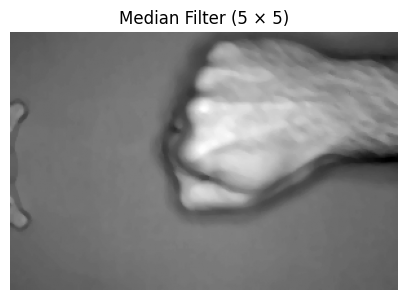

In [33]:
median_blur_image = cv2.medianBlur(gray_image, 5)

show_image(median_blur_image, "Median Filter (5 × 5)", cmap="gray")

## 13. Binary Thresholding

Thresholding converts a grayscale image into a binary image. With a fixed threshold of 127, pixels above the threshold are set to 255 (white) and all others to 0 (black).

Threshold value: 127.0
Unique pixel values: [  0 255]


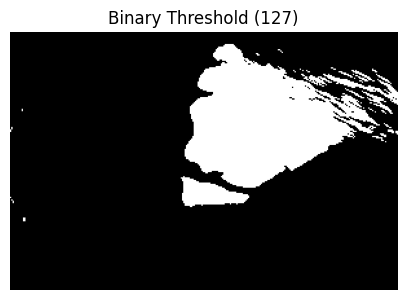

In [34]:
binary_threshold_value, binary_image = cv2.threshold(
    gray_image,
    127,
    255,
    cv2.THRESH_BINARY
)

print("Threshold value:", binary_threshold_value)
print("Unique pixel values:", np.unique(binary_image))

show_image(binary_image, "Binary Threshold (127)", cmap="gray")

## 14. Otsu Thresholding

Otsu's method selects the threshold automatically by maximising the separation between foreground and background intensity distributions. It avoids choosing a fixed value manually.

Otsu threshold value: 125.0


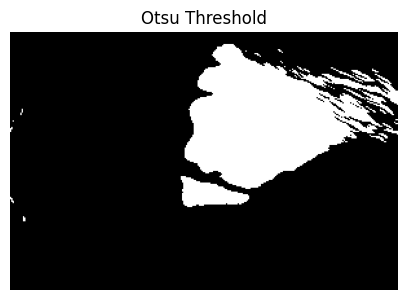

In [35]:
otsu_threshold_value, otsu_image = cv2.threshold(
    gray_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold value:", otsu_threshold_value)

show_image(otsu_image, "Otsu Threshold", cmap="gray")

## 15. Sobel Edge Detection

The Sobel operator approximates image gradients in the horizontal (X) and vertical (Y) directions. Because it measures **intensity changes**, large gradient magnitudes correspond to **edges**. The gradient magnitude combines both directions:

$$G = \sqrt{G_x^2 + G_y^2}$$

Sobel X range: -195.0 to 224.0
Sobel Y range: -199.0 to 214.0
Gradient magnitude shape: (200, 300)


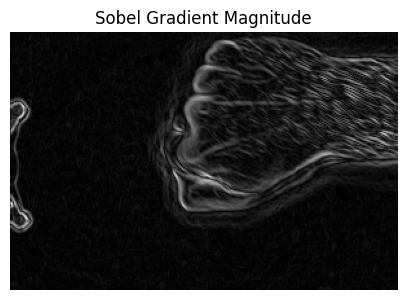

In [36]:
# Compute horizontal and vertical gradients (64-bit float to preserve negative values)
sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)

# Combine gradients into a magnitude map and scale to 0-255 for display
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_image = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

print("Sobel X range:", sobel_x.min(), "to", sobel_x.max())
print("Sobel Y range:", sobel_y.min(), "to", sobel_y.max())
print("Gradient magnitude shape:", sobel_image.shape)

show_image(sobel_image, "Sobel Gradient Magnitude", cmap="gray")

## 16. Canny Edge Detection

The Canny algorithm smooths the image, computes gradients, thins edges using non-maximum suppression, and applies hysteresis thresholding with a low and a high threshold (here 100 and 200). Only strong edges, and weak edges connected to them, are kept, yielding thin and well-defined boundaries.

Unique pixel values: [  0 255]


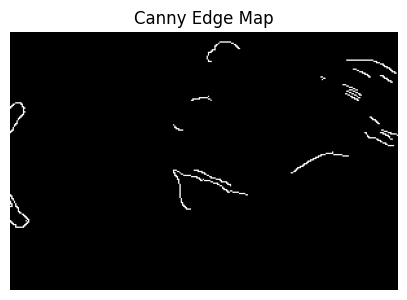

In [37]:
canny_image = cv2.Canny(
    gray_image,
    100,
    200
)

print("Unique pixel values:", np.unique(canny_image))

show_image(canny_image, "Canny Edge Map", cmap="gray")

## 17. Morphological Operations

Morphological operations process binary shapes using a structuring element (kernel). They are applied here to the Otsu-thresholded image with a 5 × 5 kernel.

* **Erosion** shrinks white regions and removes small white noise.
* **Dilation** expands white regions and fills small gaps.
* **Opening** (erosion followed by dilation) removes small white specks while preserving shape size.
* **Closing** (dilation followed by erosion) fills small black holes inside white regions.

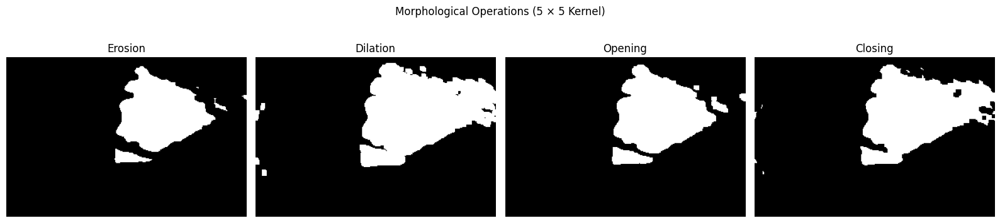

In [38]:
# Structuring element
kernel = np.ones((5, 5), np.uint8)

erosion_image = cv2.erode(otsu_image, kernel, iterations=1)
dilation_image = cv2.dilate(otsu_image, kernel, iterations=1)
opening_image = cv2.morphologyEx(otsu_image, cv2.MORPH_OPEN, kernel)
closing_image = cv2.morphologyEx(otsu_image, cv2.MORPH_CLOSE, kernel)

# Comparison figure
morphology_results = [
    ("Erosion", erosion_image),
    ("Dilation", dilation_image),
    ("Opening", opening_image),
    ("Closing", closing_image),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for axis, (title, result) in zip(axes, morphology_results):
    axis.imshow(result, cmap="gray")
    axis.set_title(title)
    axis.axis("off")

plt.suptitle("Morphological Operations (5 × 5 Kernel)")
plt.tight_layout()
plt.show()

## 18. Complete Image Processing Pipeline

The final figure compares the main stages side by side and saves the result to `../results/figures/image_processing_pipeline.png`. The morphological closing is applied to the Otsu-thresholded image.

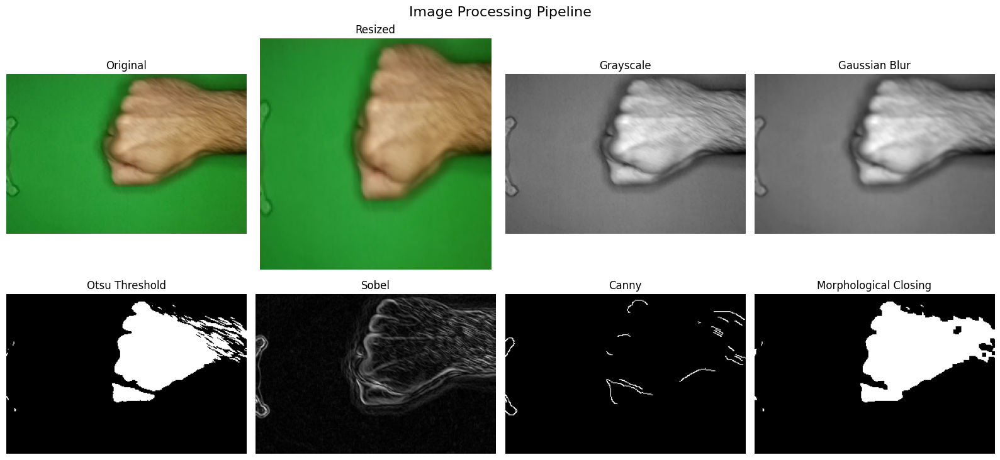

Figure saved to: ../results/figures/image_processing_pipeline.png


In [39]:
# Create the output directory if it does not exist
os.makedirs(
    "../results/figures",
    exist_ok=True
)

pipeline_stages = [
    ("Original", original_image, None),
    ("Resized", resized_image, None),
    ("Grayscale", gray_image, "gray"),
    ("Gaussian Blur", gaussian_blur_image, "gray"),
    ("Otsu Threshold", otsu_image, "gray"),
    ("Sobel", sobel_image, "gray"),
    ("Canny", canny_image, "gray"),
    ("Morphological Closing", closing_image, "gray"),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, (title, stage_image, colormap) in zip(axes.ravel(), pipeline_stages):
    axis.imshow(stage_image, cmap=colormap)
    axis.set_title(title)
    axis.axis("off")

plt.suptitle("Image Processing Pipeline", fontsize=16)
plt.tight_layout()

plt.savefig(
    "../results/figures/image_processing_pipeline.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figure saved to: ../results/figures/image_processing_pipeline.png")

# Part 3 — Traditional Machine Learning with HOG Features

## Learning Objectives

* Understand the Histogram of Oriented Gradients (HOG) descriptor
* Train Logistic Regression, SVM and Random Forest on HOG features
* Evaluate with accuracy, precision, recall, F1, confusion matrices and classification reports
* Use the permanent split and avoid data leakage

**Prerequisite:** none (the permanent split is created automatically if Lesson 1 has not been run).

In [40]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

30429

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [41]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.feature_extraction import HOG_PARAMETERS, extract_hog_features

## 2. Load the Permanent Split

In [42]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Load Images (128 × 128)

Images are loaded as RGB and resized to 128 × 128. HOG extraction converts them to grayscale internally.

In [43]:
IMAGE_SIZE = (128, 128)

X_train = load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE)
X_val = load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE)
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

print("X_train:", X_train.shape, X_train.dtype)
print("X_val:", X_val.shape)
print("Label mapping:", CLASS_TO_INDEX)

X_train: (1531, 128, 128, 3) uint8
X_val: (328, 128, 128, 3)
Label mapping: {'paper': 0, 'rock': 1, 'scissors': 2}


## 4. Histogram of Oriented Gradients (HOG)

HOG describes local shape by counting gradient orientations in small cells:

1. Compute image gradients (intensity changes).
2. Divide the image into cells (8 × 8 pixels) and build a histogram of gradient orientations (9 bins) in each cell.
3. Group cells into overlapping blocks (2 × 2 cells) and normalise each block (L2-Hys) to reduce sensitivity to lighting.
4. Concatenate all block histograms into one feature vector.

The visualisation below shows the dominant gradient orientations for one image.

HOG parameters: {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2), 'block_norm': 'L2-Hys'}
Feature vector length for one image: 8100


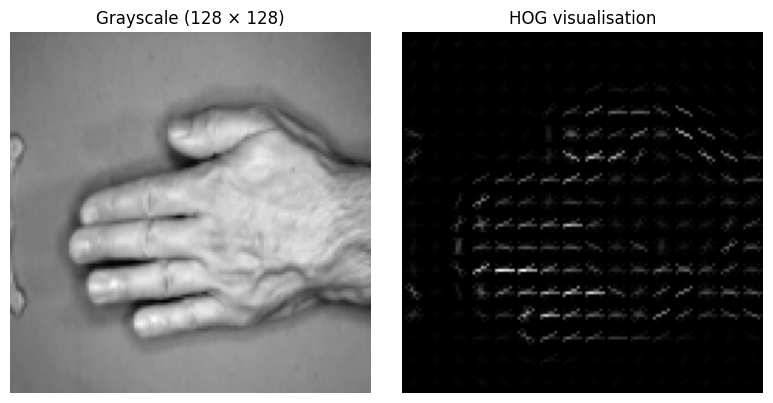

In [44]:
import cv2

sample_gray = cv2.cvtColor(X_train[0], cv2.COLOR_RGB2GRAY)
sample_features, hog_visualisation = hog(sample_gray, visualize=True, **HOG_PARAMETERS)

print("HOG parameters:", HOG_PARAMETERS)
print("Feature vector length for one image:", sample_features.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_gray, cmap="gray"); axes[0].set_title("Grayscale (128 × 128)")
axes[1].imshow(hog_visualisation, cmap="gray"); axes[1].set_title("HOG visualisation")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Extract HOG Features

In [45]:
hog_train = extract_hog_features(X_train, IMAGE_SIZE)

start_time = time.perf_counter()
hog_val = extract_hog_features(X_val, IMAGE_SIZE)
hog_ms_per_image = (time.perf_counter() - start_time) * 1000 / len(X_val)

print("HOG train features:", hog_train.shape)
print("HOG validation features:", hog_val.shape)
print(f"HOG extraction time: {hog_ms_per_image:.2f} ms per image")

# Save features for reuse
np.savez_compressed(
    f"{RESULTS_DIR}/features/hog_features.npz",
    X_train=hog_train, y_train=y_train, X_val=hog_val, y_val=y_val,
)

HOG train features: (1531, 8100)
HOG validation features: (328, 8100)
HOG extraction time: 6.05 ms per image


## 6. Train and Compare Classifiers

* **Logistic Regression** and **SVM** are scale-sensitive, so a `StandardScaler` is placed inside a `Pipeline`. The scaler is fitted **only on the training data** when `fit` is called, so no validation information leaks into preprocessing.
* **Random Forest** is insensitive to feature scaling and is trained without a scaler.

Models are compared on the **validation** set. The test set is not used.

In [46]:
classifiers = {
    "HOG + Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "HOG + SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)),
    ]),
    "HOG + Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

results = []
predictions = {}

for model_name, classifier in classifiers.items():
    start_time = time.perf_counter()
    classifier.fit(hog_train, y_train)
    training_time_sec = time.perf_counter() - start_time

    start_time = time.perf_counter()
    y_val_pred = classifier.predict(hog_val)
    predict_ms_per_image = (time.perf_counter() - start_time) * 1000 / len(hog_val)

    predictions[model_name] = y_val_pred
    # Inference time includes HOG extraction so that it is comparable with CNNs that take raw images
    results.append(build_results_row(
        model_name, "validation", y_val, y_val_pred,
        training_time_sec=training_time_sec,
        inference_time_ms_per_image=predict_ms_per_image + hog_ms_per_image,
    ))
    print(f"Trained: {model_name}")

traditional_results = pd.concat(results, ignore_index=True)
display(traditional_results.round(4))

Trained: HOG + Logistic Regression
Trained: HOG + SVM
Trained: HOG + Random Forest


,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,HOG + Logistic Regression,validation,0.9482,0.9499,0.9482,0.9481,0.9504,0.9476,0.9480,None,1.1996,6.1877
1,HOG + SVM,validation,0.9665,0.9675,0.9665,0.9663,0.9679,0.9659,0.9662,None,11.3497,15.5045
2,HOG + Random Forest,validation,0.9421,0.9425,0.9421,0.9420,0.9427,0.9417,0.9420,None,12.4211,6.3264


## 7. Classification Reports and Confusion Matrices

HOG + Logistic Regression
              precision    recall  f1-score   support

       paper       0.96      0.89      0.92       107
        rock       0.99      0.98      0.99       109
    scissors       0.90      0.97      0.94       112

    accuracy                           0.95       328
   macro avg       0.95      0.95      0.95       328
weighted avg       0.95      0.95      0.95       328

HOG + SVM
              precision    recall  f1-score   support

       paper       0.98      0.92      0.95       107
        rock       0.99      0.99      0.99       109
    scissors       0.93      0.99      0.96       112

    accuracy                           0.97       328
   macro avg       0.97      0.97      0.97       328
weighted avg       0.97      0.97      0.97       328

HOG + Random Forest
              precision    recall  f1-score   support

       paper       0.95      0.92      0.93       107
        rock       0.95      0.94      0.95       109
    scissors       

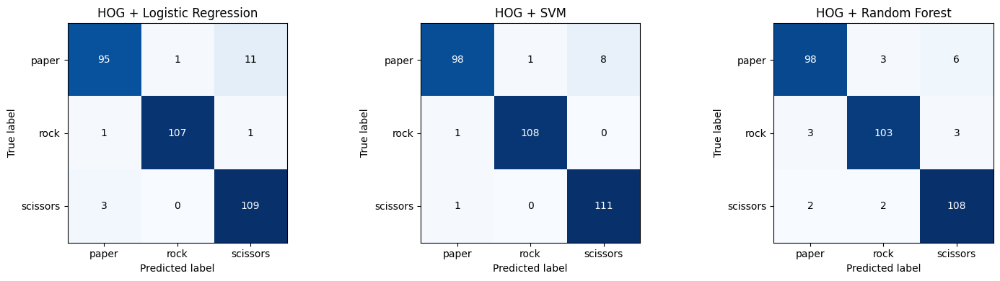

In [47]:
for model_name, y_val_pred in predictions.items():
    print("=" * 60)
    print(model_name)
    print(classification_report(y_val, y_val_pred))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (model_name, y_val_pred) in zip(axes, predictions.items()):
    plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, ax=axis, title=model_name)
plt.tight_layout()
plt.show()

## 8. Save Results

In [48]:
save_metrics(traditional_results, f"{RESULTS_DIR}/metrics/traditional_ml_results.csv")

Saved: ../results/metrics/traditional_ml_results.csv


## Conclusions

* HOG converts each image into a fixed-length shape descriptor, allowing classical classifiers to be applied.
* Preprocessing (`StandardScaler`) was fitted on training data only, via a `Pipeline`.
* Models were compared on the validation set; read the table above for the measured results. Metrics come from actual model execution.
* **Next:** Lesson 4 trains a fully connected neural network on raw pixels.

# Part 4 — Artificial Neural Network (ANN)

## Learning Objectives

* Prepare flattened, normalised pixel input
* Build and train a fully connected network with dropout
* Interpret training curves and evaluate on the validation set
* Understand why flattening discards spatial structure

In [49]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

11811

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [50]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from src.models import build_ann

## 2. Load the Permanent Split

In [51]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prepare the Data

Images are resized to 64 × 64 RGB, scaled to [0, 1] with `X = X / 255.0`, and **flattened** into vectors of length 64 × 64 × 3 = 12,288. Flattening treats every pixel as an independent input, so the network cannot exploit the 2-D neighbourhood structure of an image (this is what convolutional networks address in Lesson 5).

In [52]:
IMAGE_SIZE = (64, 64)

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Image tensor:", X_train.shape)
print("Flattened:", X_train_flat.shape)
print("Value range:", X_train_flat.min(), "to", X_train_flat.max())

Image tensor: (1531, 64, 64, 3)
Flattened: (1531, 12288)
Value range: 0.0 to 1.0


## 4. Build the Model

In [53]:
model = build_ann(input_dim=X_train_flat.shape[1])
model.summary()

I0000 00:00:1791797259.281554      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791797259.286027      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,267 (12.13 MB)

 Trainable params: 3,179,267 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train

The specified setup is used: Adam optimiser, sparse categorical cross-entropy, 30 epochs and batch size 32. The validation set is used only to monitor performance.

In [54]:
start_time = time.perf_counter()
history = model.fit(
    X_train_flat, y_train,
    validation_data=(X_val_flat, y_val),
    epochs=30,
    batch_size=32,
    verbose=2,
)
training_time_sec = time.perf_counter() - start_time
print(f"Training time: {training_time_sec:.1f} s")

Epoch 1/30


I0000 00:00:1791797266.121114     162 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


48/48 - 6s - 133ms/step - accuracy: 0.4082 - loss: 1.8340 - val_accuracy: 0.6006 - val_loss: 0.9050
Epoch 2/30
48/48 - 0s - 6ms/step - accuracy: 0.5336 - loss: 0.9493 - val_accuracy: 0.8049 - val_loss: 0.7247
Epoch 3/30
48/48 - 0s - 6ms/step - accuracy: 0.6127 - loss: 0.9013 - val_accuracy: 0.6860 - val_loss: 0.8172
Epoch 4/30
48/48 - 0s - 6ms/step - accuracy: 0.6316 - loss: 0.8945 - val_accuracy: 0.7927 - val_loss: 0.6711
Epoch 5/30
48/48 - 0s - 6ms/step - accuracy: 0.5944 - loss: 0.8819 - val_accuracy: 0.5915 - val_loss: 0.8658
Epoch 6/30
48/48 - 0s - 6ms/step - accuracy: 0.5258 - loss: 0.9322 - val_accuracy: 0.6402 - val_loss: 0.8112
Epoch 7/30
48/48 - 0s - 6ms/step - accuracy: 0.5565 - loss: 0.9270 - val_accuracy: 0.6890 - val_loss: 0.8101
Epoch 8/30
48/48 - 0s - 6ms/step - accuracy: 0.5219 - loss: 0.9517 - val_accuracy: 0.6402 - val_loss: 0.8443
Epoch 9/30
48/48 - 0s - 6ms/step - accuracy: 0.5702 - loss: 0.8967 - val_accuracy: 0.7378 - val_loss: 0.7611
Epoch 10/30
48/48 - 0s - 6ms

## 6. Training Curves

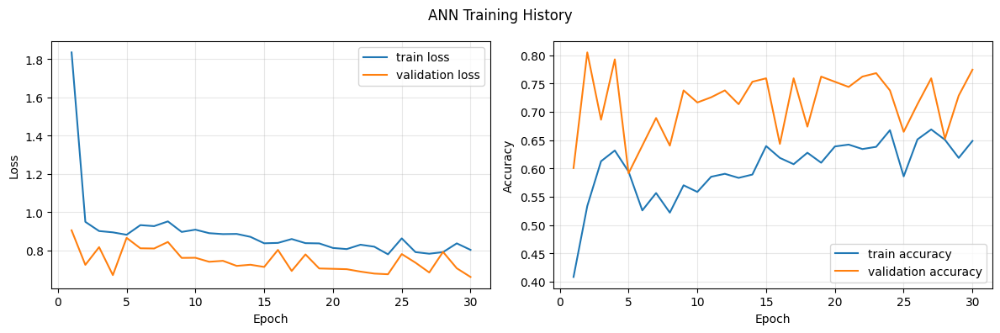

In [55]:
history_df = save_history(history, f"{RESULTS_DIR}/metrics/ann_history.csv")
plot_training_history(history_df, "ANN Training History")

## 7. Evaluate on the Validation Set

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,ANN,validation,0.7744,0.7986,0.7744,0.7776,0.8008,0.7743,0.7785,3179267,14.8333,1.3527


              precision    recall  f1-score   support

       paper       0.99      0.72      0.83       107
        rock       0.73      0.85      0.79       109
    scissors       0.68      0.75      0.71       112

    accuracy                           0.77       328
   macro avg       0.80      0.77      0.78       328
weighted avg       0.80      0.77      0.78       328



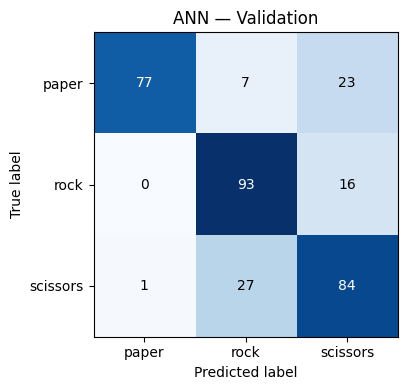

In [56]:
inference_ms = measure_inference_time(lambda data: model.predict(data, verbose=0), X_val_flat)
y_val_pred = model.predict(X_val_flat, verbose=0).argmax(axis=1)

results_row = build_results_row(
    "ANN", "validation", y_val, y_val_pred,
    parameter_count=model.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(results_row.round(4))
print(classification_report(y_val, y_val_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, title="ANN — Validation")
plt.tight_layout()
plt.show()

## 8. Save Model and Results

In [57]:
model.save(f"{RESULTS_DIR}/models/ann_model.keras")
save_metrics(results_row, f"{RESULTS_DIR}/metrics/ann_results.csv")

Saved: ../results/metrics/ann_results.csv


## Conclusions

* The ANN operates on flattened pixels and has no built-in notion of spatial locality.
* Results above are measured on the validation set; the test set remains untouched.
* **Next:** Lesson 5 introduces convolutional layers that preserve spatial structure.

# Part 5 — Baseline Convolutional Neural Network (CNN)

## Learning Objectives

* Understand convolution, pooling and feature maps
* Train a baseline CNN on 128 × 128 RGB images
* Evaluate on the validation set and save the model

In [58]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [59]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from src.models import build_cnn

## 2. Load the Permanent Split

In [60]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prepare the Data

In [61]:
IMAGE_SIZE = (128, 128)

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

print("X_train:", X_train.shape, "| X_val:", X_val.shape)

X_train: (1531, 128, 128, 3) | X_val: (328, 128, 128, 3)


## 4. Model Architecture

* **Conv2D** layers learn small (3 × 3) filters that respond to local patterns such as edges and textures; deeper layers combine them into more complex shapes.
* **MaxPooling2D** reduces spatial size and adds tolerance to small shifts.
* **Flatten + Dense** layers combine the learned features for classification.
* **Dropout (0.40)** randomly disables units during training to reduce overfitting.

In [62]:
model = build_cnn(input_shape=(128, 128, 3), use_batch_norm=False)
model.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_dense (Dense)           │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train (20 epochs, batch size 32)

Epoch 1/20


2026-10-12 09:28:12.403679: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:28:12.552215: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:28:16.420918: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:28:16.569262: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


48/48 - 12s - 249ms/step - accuracy: 0.6956 - loss: 0.7108 - val_accuracy: 0.9116 - val_loss: 0.2611
Epoch 2/20
48/48 - 1s - 21ms/step - accuracy: 0.9210 - loss: 0.2383 - val_accuracy: 0.9482 - val_loss: 0.1388
Epoch 3/20
48/48 - 1s - 22ms/step - accuracy: 0.9530 - loss: 0.1255 - val_accuracy: 0.9726 - val_loss: 0.0981
Epoch 4/20
48/48 - 1s - 22ms/step - accuracy: 0.9700 - loss: 0.0936 - val_accuracy: 0.9512 - val_loss: 0.1320
Epoch 5/20
48/48 - 1s - 22ms/step - accuracy: 0.9726 - loss: 0.0691 - val_accuracy: 0.9726 - val_loss: 0.0765
Epoch 6/20
48/48 - 1s - 21ms/step - accuracy: 0.9824 - loss: 0.0531 - val_accuracy: 0.9817 - val_loss: 0.0634
Epoch 7/20
48/48 - 1s - 22ms/step - accuracy: 0.9804 - loss: 0.0628 - val_accuracy: 0.9543 - val_loss: 0.1521
Epoch 8/20
48/48 - 1s - 22ms/step - accuracy: 0.9837 - loss: 0.0516 - val_accuracy: 0.9695 - val_loss: 0.1365
Epoch 9/20
48/48 - 1s - 21ms/step - accuracy: 0.9895 - loss: 0.0273 - val_accuracy: 0.9634 - val_loss: 0.2129
Epoch 10/20
48/48 -

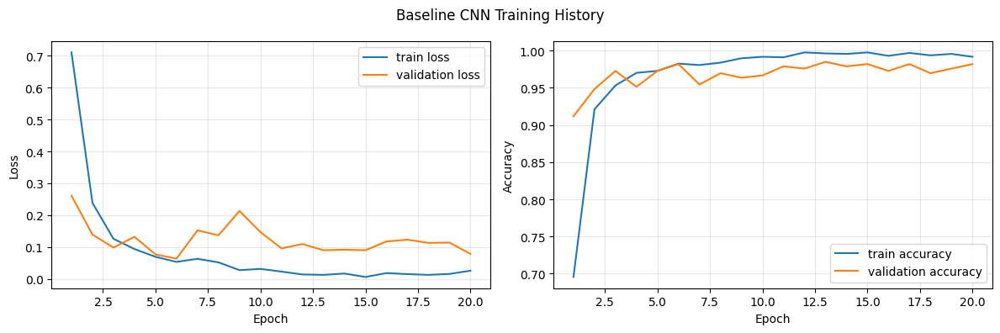

In [63]:
start_time = time.perf_counter()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=2,
)
training_time_sec = time.perf_counter() - start_time
print(f"Training time: {training_time_sec:.1f} s")

history_df = save_history(history, f"{RESULTS_DIR}/metrics/cnn_baseline_history.csv")
plot_training_history(history_df, "Baseline CNN Training History")

## 6. Evaluate on the Validation Set

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,Baseline CNN,validation,0.9817,0.9819,0.9817,0.9816,0.982,0.9814,0.9815,3305027,32.2817,2.8464


              precision    recall  f1-score   support

       paper       0.99      0.95      0.97       107
        rock       0.98      1.00      0.99       109
    scissors       0.97      0.99      0.98       112

    accuracy                           0.98       328
   macro avg       0.98      0.98      0.98       328
weighted avg       0.98      0.98      0.98       328



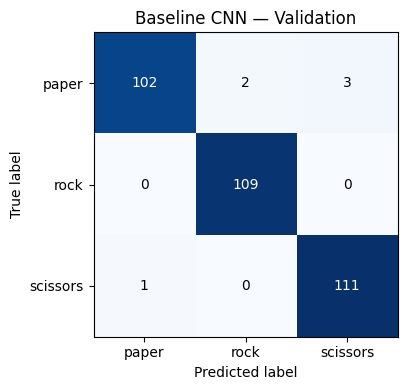

In [64]:
inference_ms = measure_inference_time(lambda data: model.predict(data, verbose=0), X_val)
y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)

results_row = build_results_row(
    "Baseline CNN", "validation", y_val, y_val_pred,
    parameter_count=model.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(results_row.round(4))
print(classification_report(y_val, y_val_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, title="Baseline CNN — Validation")
plt.tight_layout()
plt.show()

## 7. Save Model and Results

In [65]:
model.save(f"{RESULTS_DIR}/models/cnn_baseline.keras")
save_metrics(results_row, f"{RESULTS_DIR}/metrics/cnn_baseline_results.csv")

Saved: ../results/metrics/cnn_baseline_results.csv


## Conclusions

* The baseline CNN uses convolution and pooling to learn spatial features directly from pixels.
* Compare the gap between training and validation curves to judge overfitting.
* **Next:** Lesson 6 adds data augmentation, batch normalisation and learning-rate scheduling.

# Part 6 — CNN with Data Augmentation

## Learning Objectives

* Apply random transformations to enlarge the effective training set
* Understand why augmentation must only be applied to training data
* Use Batch Normalisation, EarlyStopping and ReduceLROnPlateau

In [66]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [67]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from src.models import build_cnn

## 2. Load the Permanent Split

In [68]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prepare the Data

In [69]:
IMAGE_SIZE = (128, 128)

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

## 4. Data Augmentation

Augmentation creates modified versions of training images (small rotations, shifts, zooms and horizontal flips) on the fly. It exposes the network to plausible variation and reduces overfitting.

**Why augment only the training data?** Validation and test sets must estimate performance on *real, unmodified* data. Augmenting them would change the evaluation distribution and make scores incomparable across experiments. Augmentation is a training-time regulariser, not a property of the data being evaluated.

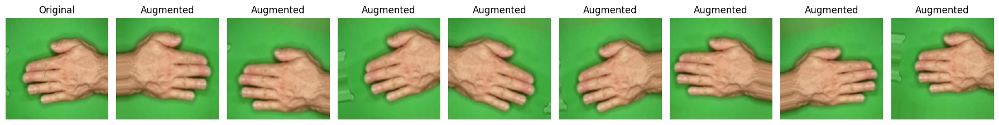

In [70]:
augmenter = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

# Visualise eight augmented versions of one training image
example_flow = augmenter.flow(X_train[:1], batch_size=1, seed=RANDOM_STATE, shuffle=False)
fig, axes = plt.subplots(1, 9, figsize=(18, 2.5))
axes[0].imshow(X_train[0]); axes[0].set_title("Original")
for axis in axes[1:]:
    axis.imshow(np.clip(next(example_flow)[0], 0, 1)); axis.set_title("Augmented")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Model with Batch Normalisation

Batch Normalisation standardises layer activations within each mini-batch, which typically stabilises and speeds up training.

## 6. Train with Callbacks

* **EarlyStopping** stops training when validation loss stops improving and restores the best weights.
* **ReduceLROnPlateau** halves the learning rate when validation loss plateaus.

The augmenter is applied to the training data only; validation data is passed unchanged.

Epoch 1/50
48/48 - 14s - 294ms/step - accuracy: 0.6055 - loss: 2.1686 - val_accuracy: 0.3323 - val_loss: 14.6375 - learning_rate: 0.0010
Epoch 2/50
48/48 - 5s - 112ms/step - accuracy: 0.8485 - loss: 0.5024 - val_accuracy: 0.3323 - val_loss: 29.6473 - learning_rate: 0.0010
Epoch 3/50
48/48 - 5s - 112ms/step - accuracy: 0.9099 - loss: 0.3020 - val_accuracy: 0.3323 - val_loss: 32.4066 - learning_rate: 0.0010
Epoch 4/50
48/48 - 5s - 112ms/step - accuracy: 0.9360 - loss: 0.2186 - val_accuracy: 0.3323 - val_loss: 34.2486 - learning_rate: 0.0010
Epoch 5/50
48/48 - 6s - 115ms/step - accuracy: 0.9477 - loss: 0.2058 - val_accuracy: 0.3323 - val_loss: 35.2669 - learning_rate: 5.0000e-04
Epoch 6/50
48/48 - 5s - 113ms/step - accuracy: 0.9497 - loss: 0.2045 - val_accuracy: 0.3323 - val_loss: 32.0594 - learning_rate: 5.0000e-04
Epoch 7/50
48/48 - 5s - 114ms/step - accuracy: 0.9647 - loss: 0.1379 - val_accuracy: 0.3323 - val_loss: 23.6179 - learning_rate: 5.0000e-04
Epoch 8/50
48/48 - 5s - 112ms/step 

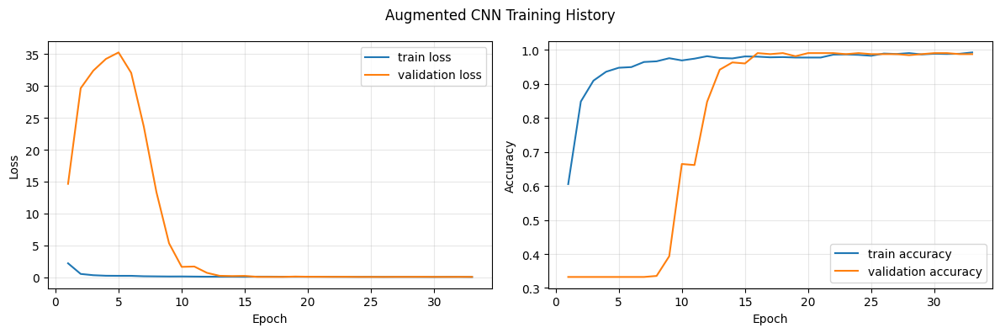

In [71]:
model = build_cnn(input_shape=(128, 128, 3), use_batch_norm=True)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]

train_generator = augmenter.flow(X_train, y_train, batch_size=32, seed=RANDOM_STATE)

start_time = time.perf_counter()
history = model.fit(
    train_generator,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks,
    verbose=2,
)
training_time_sec = time.perf_counter() - start_time
print(f"Training time: {training_time_sec:.1f} s | epochs run: {len(history.history['loss'])}")

history_df = save_history(history, f"{RESULTS_DIR}/metrics/cnn_augmented_history.csv")
plot_training_history(history_df, "Augmented CNN Training History")

## 7. Evaluate on the Validation Set

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,Augmented CNN,validation,0.9878,0.9878,0.9878,0.9878,0.9877,0.9877,0.9877,3305923,187.7973,3.5162


              precision    recall  f1-score   support

       paper       0.98      0.98      0.98       107
        rock       0.99      0.99      0.99       109
    scissors       0.99      0.99      0.99       112

    accuracy                           0.99       328
   macro avg       0.99      0.99      0.99       328
weighted avg       0.99      0.99      0.99       328



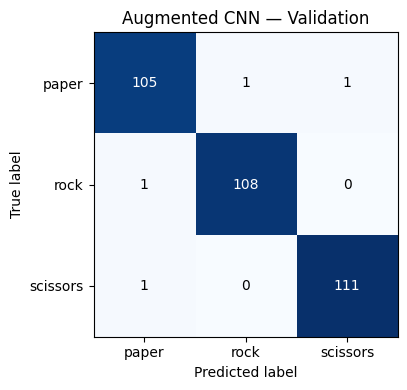

In [72]:
inference_ms = measure_inference_time(lambda data: model.predict(data, verbose=0), X_val)
y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)

results_row = build_results_row(
    "Augmented CNN", "validation", y_val, y_val_pred,
    parameter_count=model.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(results_row.round(4))
print(classification_report(y_val, y_val_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, title="Augmented CNN — Validation")
plt.tight_layout()
plt.show()

## 8. Save Model and Results

In [73]:
model.save(f"{RESULTS_DIR}/models/cnn_augmented.keras")
save_metrics(results_row, f"{RESULTS_DIR}/metrics/cnn_augmented_results.csv")

Saved: ../results/metrics/cnn_augmented_results.csv


## Conclusions

* Augmentation, Batch Normalisation and callbacks were combined in one model; Lesson 11 separates their individual effects with a controlled ablation.
* Augmentation was applied only to training data.
* **Next:** Lesson 7 reuses a network pre-trained on ImageNet (transfer learning).

# Part 7 — Transfer Learning with MobileNetV2

## Learning Objectives

* Reuse ImageNet features with a frozen MobileNetV2 base
* Apply the correct MobileNetV2 preprocessing
* Train the classification head, then fine-tune later layers with a low learning rate

**Note:** ImageNet weights are downloaded on first use, which requires internet access.

In [74]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [75]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from src.models import build_mobilenetv2

## 2. Load the Permanent Split

In [76]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prepare the Data

Images are resized to 224 × 224 and kept as `uint8`. MobileNetV2 expects inputs scaled to [-1, 1] by its own `preprocess_input`, so images are **not** divided by 255 beforehand. Preprocessing is applied batch-wise inside a `tf.data` pipeline to limit memory use.

In [77]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

X_train = load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE)
X_val = load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE)
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()


def make_dataset(images, labels, shuffle):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        dataset = dataset.shuffle(len(images), seed=RANDOM_STATE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y))
    return dataset.prefetch(tf.data.AUTOTUNE)


train_dataset = make_dataset(X_train, y_train, shuffle=True)
val_dataset = make_dataset(X_val, y_val, shuffle=False)

print("X_train:", X_train.shape, X_train.dtype)

X_train: (1531, 224, 224, 3) uint8


## 4. Build the Model

`MobileNetV2 (frozen) → GlobalAveragePooling2D → Dense(128, relu) → Dropout(0.40) → Dense(3, softmax)`

In [78]:
model, base_model = build_mobilenetv2(input_shape=(224, 224, 3))
print("Total parameters:", model.count_params())
print("Trainable parameters (base frozen):", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 2422339
Trainable parameters (base frozen): 164355


## 5. Stage 1 — Train the Classification Head

The base model is frozen so that only the new head learns, avoiding early destruction of pre-trained features.

In [79]:
start_time = time.perf_counter()
history_stage1 = model.fit(train_dataset, validation_data=val_dataset, epochs=10, verbose=2)

Epoch 1/10


2026-10-12 09:32:57.997409: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:32:58.135270: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:33:11.036652: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:33:11.174357: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:33:26.465951: E external/local_xla/xla/stream_

48/48 - 46s - 968ms/step - accuracy: 0.8668 - loss: 0.3604 - val_accuracy: 0.9756 - val_loss: 0.0709
Epoch 2/10
48/48 - 2s - 39ms/step - accuracy: 0.9876 - loss: 0.0508 - val_accuracy: 0.9909 - val_loss: 0.0281
Epoch 3/10
48/48 - 2s - 39ms/step - accuracy: 0.9915 - loss: 0.0302 - val_accuracy: 0.9970 - val_loss: 0.0204
Epoch 4/10
48/48 - 2s - 39ms/step - accuracy: 0.9948 - loss: 0.0234 - val_accuracy: 0.9939 - val_loss: 0.0159
Epoch 5/10
48/48 - 2s - 38ms/step - accuracy: 0.9954 - loss: 0.0197 - val_accuracy: 0.9939 - val_loss: 0.0132
Epoch 6/10
48/48 - 2s - 38ms/step - accuracy: 0.9987 - loss: 0.0103 - val_accuracy: 0.9970 - val_loss: 0.0095
Epoch 7/10
48/48 - 2s - 39ms/step - accuracy: 0.9987 - loss: 0.0074 - val_accuracy: 0.9970 - val_loss: 0.0089
Epoch 8/10
48/48 - 2s - 38ms/step - accuracy: 1.0000 - loss: 0.0056 - val_accuracy: 1.0000 - val_loss: 0.0068
Epoch 9/10
48/48 - 2s - 38ms/step - accuracy: 1.0000 - loss: 0.0041 - val_accuracy: 0.9970 - val_loss: 0.0072
Epoch 10/10
48/48 -

## 6. Stage 2 — Fine-Tune Later Layers

The last 30 layers of the base model are unfrozen and trained with a much lower learning rate (1e-5). Base-model layers are called in inference mode, so batch-normalisation statistics stay fixed.

In [80]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable parameters (fine-tuning):", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

history_stage2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=2,
)
training_time_sec = time.perf_counter() - start_time
print(f"Total training time: {training_time_sec:.1f} s")

Trainable parameters (fine-tuning): 1690755
Epoch 1/10
48/48 - 33s - 684ms/step - accuracy: 0.9197 - loss: 0.2175 - val_accuracy: 0.9970 - val_loss: 0.0234
Epoch 2/10
48/48 - 2s - 48ms/step - accuracy: 0.9876 - loss: 0.0441 - val_accuracy: 0.9939 - val_loss: 0.0300
Epoch 3/10
48/48 - 2s - 47ms/step - accuracy: 0.9915 - loss: 0.0294 - val_accuracy: 0.9909 - val_loss: 0.0330
Epoch 4/10
48/48 - 2s - 47ms/step - accuracy: 0.9980 - loss: 0.0162 - val_accuracy: 0.9909 - val_loss: 0.0333
Epoch 5/10
48/48 - 2s - 47ms/step - accuracy: 0.9967 - loss: 0.0112 - val_accuracy: 0.9909 - val_loss: 0.0335
Total training time: 105.1 s


## 7. Training Curves

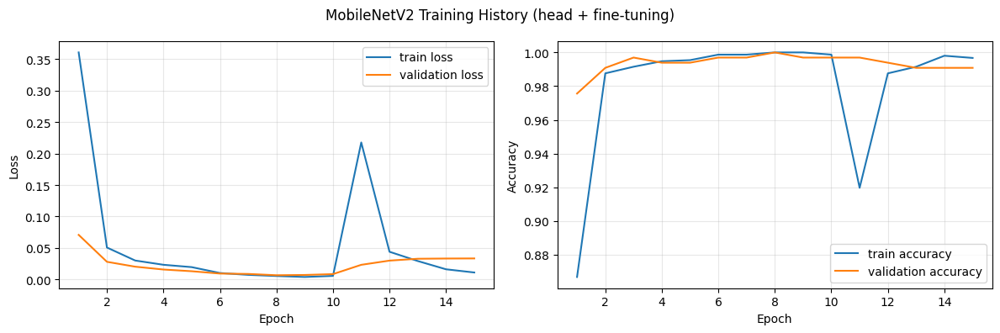

In [81]:
history_df = pd.concat(
    [pd.DataFrame(history_stage1.history).assign(stage="head"),
     pd.DataFrame(history_stage2.history).assign(stage="fine-tuning")],
    ignore_index=True,
)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"
history_df.to_csv(f"{RESULTS_DIR}/metrics/mobilenetv2_history.csv")

plot_training_history(history_df, "MobileNetV2 Training History (head + fine-tuning)")

## 8. Evaluate on the Validation Set

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,MobileNetV2,validation,0.997,0.997,0.997,0.997,0.9971,0.9969,0.997,2422339,105.1428,27.7889


              precision    recall  f1-score   support

       paper       1.00      0.99      1.00       107
        rock       1.00      1.00      1.00       109
    scissors       0.99      1.00      1.00       112

    accuracy                           1.00       328
   macro avg       1.00      1.00      1.00       328
weighted avg       1.00      1.00      1.00       328



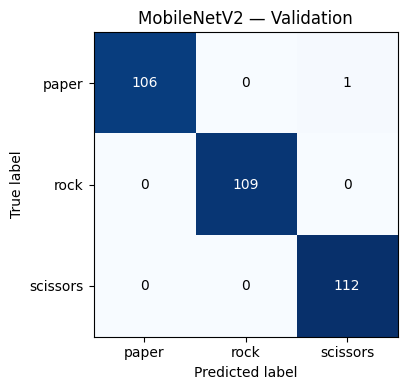

In [82]:
start_time = time.perf_counter()
val_probabilities = model.predict(val_dataset, verbose=0)
inference_ms = (time.perf_counter() - start_time) * 1000 / len(X_val)
y_val_pred = val_probabilities.argmax(axis=1)

results_row = build_results_row(
    "MobileNetV2", "validation", y_val, y_val_pred,
    parameter_count=model.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(results_row.round(4))
print(classification_report(y_val, y_val_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, title="MobileNetV2 — Validation")
plt.tight_layout()
plt.show()

## 9. Save Model and Results

In [83]:
model.save(f"{RESULTS_DIR}/models/mobilenetv2_finetuned.keras")
save_metrics(results_row, f"{RESULTS_DIR}/metrics/mobilenetv2_results.csv")

Saved: ../results/metrics/mobilenetv2_results.csv


## Conclusions

* Transfer learning reuses features learned on ImageNet; only a small head was trained first, followed by low-learning-rate fine-tuning.
* MobileNetV2 preprocessing was applied without prior division by 255.
* **Next:** Lesson 8 combines learned CNN features with handcrafted HOG features.

# Part 8 — CNN + HOG Hybrid Model

## Learning Objectives

* Extract deep features from a trained CNN
* Combine them with standardised handcrafted HOG features
* Train a dense classifier on the concatenated representation

**Prerequisite:** run Lesson 5 first (`results/models/cnn_baseline.keras` is used as the feature extractor).

In [84]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [85]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

import joblib
from sklearn.preprocessing import StandardScaler

from src.feature_extraction import extract_hog_features
from src.models import build_cnn_feature_extractor, build_hybrid_classifier

## 2. Load the Permanent Split

In [86]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prepare the Data

In [87]:
IMAGE_SIZE = (128, 128)

X_train_uint8 = load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE)
X_val_uint8 = load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE)
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

X_train = normalize_images(X_train_uint8)
X_val = normalize_images(X_val_uint8)

## 4. CNN Deep Features

The trained baseline CNN is truncated at its 128-unit dense layer (`feature_dense`); the activations of that layer are used as a 128-dimensional learned representation.

**Caveat:** this CNN was trained on the training images, so training-set features are fitted to the training labels and may look more separable than validation features. Validation performance is therefore the meaningful indicator.

In [88]:
cnn_path = f"{RESULTS_DIR}/models/cnn_baseline.keras"
if not os.path.exists(cnn_path):
    raise FileNotFoundError("Run Lesson 5 first to create results/models/cnn_baseline.keras")

trained_cnn = tf.keras.models.load_model(cnn_path)
feature_extractor = build_cnn_feature_extractor(trained_cnn, layer_name="feature_dense")

cnn_features_train = feature_extractor.predict(X_train, verbose=0)
cnn_features_val = feature_extractor.predict(X_val, verbose=0)
print("CNN features:", cnn_features_train.shape, cnn_features_val.shape)

CNN features: (1531, 128) (328, 128)


## 5. HOG Features and Standardisation

The `StandardScaler` is **fitted only on the training HOG features** and then applied to validation features, preventing data leakage.

In [89]:
hog_train = extract_hog_features(X_train_uint8, IMAGE_SIZE)
hog_val = extract_hog_features(X_val_uint8, IMAGE_SIZE)

scaler = StandardScaler().fit(hog_train)
hog_train_scaled = scaler.transform(hog_train)
hog_val_scaled = scaler.transform(hog_val)

print("HOG features:", hog_train_scaled.shape)

HOG features: (1531, 8100)


## 6. Concatenate Features

In [90]:
hybrid_train = np.concatenate([cnn_features_train, hog_train_scaled], axis=1).astype("float32")
hybrid_val = np.concatenate([cnn_features_val, hog_val_scaled], axis=1).astype("float32")
print("Hybrid features:", hybrid_train.shape, hybrid_val.shape)

Hybrid features: (1531, 8228) (328, 8228)


## 7. Train the Hybrid Classifier

Model: "hybrid_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,106,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,139,907 (8.16 MB)

 Trainable params: 2,139,907 (8.16 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
48/48 - 5s - 100ms/step - accuracy: 0.8935 - loss: 0.3896 - val_accuracy: 0.9543 - val_loss: 0.2608
Epoch 2/50
48/48 - 0s - 6ms/step - accuracy: 0.9673 - loss: 0.1978 - val_accuracy: 0.9665 - val_loss: 0.1988
Epoch 3/50
48/48 - 0s - 6ms/step - accuracy: 0.9863 - loss: 0.0801 - val_accuracy: 0.9695 - val_loss: 0.2744
Epoch 4/50
48/48 - 0s - 6ms/step - accuracy: 0.9850 - loss: 0.0719 - val_accuracy: 0.9665 - val_loss: 0.3041
Epoch 5/50
48/48 - 0s - 6ms/step - accuracy: 0.9909 - loss: 0.0450 - val_accuracy: 0.9787 - val_loss: 0.2224
Epoch 6/50
48/48 - 0s - 6ms/step - accuracy: 0.9954 - loss: 0.0347 - val_accuracy: 0.9878 - val_loss: 0.1773
Epoch 7/50
48/48 - 0s - 6ms/step - accuracy: 0.9882 - loss: 0.0721 - val_accuracy: 0.9756 - val_loss: 0.1902
Epoch 8/50
48/48 - 0s - 6ms/step - accuracy: 0.9948 - loss: 0.0263 - val_accuracy: 0.9695 - val_loss: 0.3722
Epoch 9/50
48/48 - 0s - 6ms/step - accuracy: 0.9922 - loss: 0.0485 - val_accuracy: 0.9665 - val_loss: 0.3718
Epoch 10/50
48/48

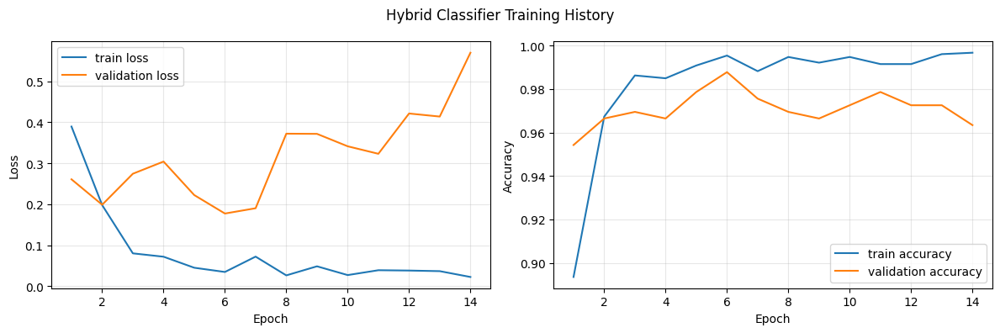

In [91]:
hybrid_model = build_hybrid_classifier(input_dim=hybrid_train.shape[1])
hybrid_model.summary()

start_time = time.perf_counter()
history = hybrid_model.fit(
    hybrid_train, y_train,
    validation_data=(hybrid_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
    verbose=2,
)
training_time_sec = time.perf_counter() - start_time
print(f"Classifier training time: {training_time_sec:.1f} s")

history_df = save_history(history, f"{RESULTS_DIR}/metrics/hybrid_history.csv")
plot_training_history(history_df, "Hybrid Classifier Training History")

## 8. Evaluate on the Validation Set

Inference time covers the full hybrid pipeline (HOG extraction, scaling, CNN feature extraction and classification). The reported parameter count and training time include the CNN feature extractor's parameters, but the training time refers only to the hybrid classifier (the CNN was trained in Lesson 5).

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,CNN + HOG Hybrid,validation,0.9878,0.9878,0.9878,0.9878,0.9879,0.9877,0.9877,5444547,8.5888,8.1784


              precision    recall  f1-score   support

       paper       0.99      0.97      0.98       107
        rock       0.99      1.00      1.00       109
    scissors       0.98      0.99      0.99       112

    accuracy                           0.99       328
   macro avg       0.99      0.99      0.99       328
weighted avg       0.99      0.99      0.99       328



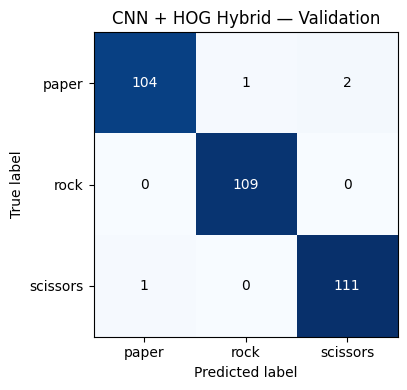

Baseline CNN alone (validation): {'accuracy': 0.9817073170731707, 'precision_weighted': 0.9818592459253875, 'recall_weighted': 0.9817073170731707, 'f1_weighted': 0.9816147779481473, 'precision_macro': 0.98198581821474, 'recall_macro': 0.9814474855362706, 'f1_macro': 0.9815461824311381}


In [92]:
def predict_hybrid(images_uint8):
    hog_scaled = scaler.transform(extract_hog_features(images_uint8, IMAGE_SIZE))
    cnn_features = feature_extractor.predict(normalize_images(images_uint8), verbose=0)
    combined = np.concatenate([cnn_features, hog_scaled], axis=1).astype("float32")
    return hybrid_model.predict(combined, verbose=0)


inference_ms = measure_inference_time(predict_hybrid, X_val_uint8)
y_val_pred = predict_hybrid(X_val_uint8).argmax(axis=1)

results_row = build_results_row(
    "CNN + HOG Hybrid", "validation", y_val, y_val_pred,
    parameter_count=hybrid_model.count_params() + feature_extractor.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(results_row.round(4))
print(classification_report(y_val, y_val_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_val_pred), CLASS_NAMES, title="CNN + HOG Hybrid — Validation")
plt.tight_layout()
plt.show()

# Reference: the CNN on its own (validation set)
cnn_val_pred = trained_cnn.predict(X_val, verbose=0).argmax(axis=1)
print("Baseline CNN alone (validation):", calculate_metrics(y_val, cnn_val_pred))

## 9. Save Model, Features, Scaler and Results

In [93]:
hybrid_model.save(f"{RESULTS_DIR}/models/cnn_hog_hybrid.keras")
joblib.dump(scaler, f"{RESULTS_DIR}/models/hog_scaler.joblib")
np.savez_compressed(
    f"{RESULTS_DIR}/features/hybrid_features.npz",
    X_train=hybrid_train, y_train=y_train, X_val=hybrid_val, y_val=y_val,
)
save_metrics(results_row, f"{RESULTS_DIR}/metrics/hybrid_results.csv")

Saved: ../results/metrics/hybrid_results.csv


## Conclusions

* The hybrid representation concatenates 128 learned CNN features with standardised HOG features.
* The scaler was fitted only on training data.
* Compare the hybrid with the CNN alone using the metrics printed above.
* **Next:** Lesson 9 explains what the CNN is doing using Grad-CAM and confidence analysis.

# Part 9 — Model Explainability

## Learning Objectives

* Inspect prediction probabilities and confidence
* Separate correct from incorrect predictions and find high-confidence errors
* Compute per-class accuracy and a confusion matrix
* Implement Grad-CAM to see which image regions influence a CNN prediction

**Prerequisite:** run Lesson 5 first (uses `results/models/cnn_baseline.keras`). All analysis uses the validation set.

In [94]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [95]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf

from src.evaluation import (
    confidence_summary,
    find_last_conv_layer,
    make_gradcam_heatmap,
    overlay_heatmap,
    per_class_metrics,
)
from src.models import set_seed

set_seed(RANDOM_STATE)

## 2. Load the Permanent Split and the Trained CNN

In [96]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


IMAGE_SIZE = (128, 128)
MODEL_PATH = f"{RESULTS_DIR}/models/cnn_baseline.keras"
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError("Run Lesson 5 first to create " + MODEL_PATH)

model = tf.keras.models.load_model(MODEL_PATH)

X_val_uint8 = load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE)
X_val = normalize_images(X_val_uint8)
y_val = validation_df["label_index"].to_numpy()

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Prediction Probabilities and Confidence

The softmax output gives one probability per class. The **confidence** is the largest probability. Confidence is not the same as correctness: a network can be confidently wrong, and softmax probabilities are often poorly calibrated.

In [97]:
probabilities = model.predict(X_val, verbose=0)
y_pred = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
is_correct = y_pred == y_val

prediction_df = validation_df[["relative_path", "label"]].copy()
prediction_df["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
prediction_df["confidence"] = confidence
prediction_df["correct"] = is_correct
for class_index, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_name}"] = probabilities[:, class_index]

display(prediction_df.head(10).round(3))
print("Validation accuracy:", round(float(is_correct.mean()), 4))

,relative_path,label,predicted_label,confidence,correct,prob_paper,prob_rock,prob_scissors
0,paper/0Og76sl5CJhbxWWx.png,paper,paper,1.0,True,1.0,0.0,0.0
1,paper/1Tt9U9SzrOm98Xtw.png,paper,paper,1.0,True,1.0,0.0,0.0
2,paper/27XFtQjjXQ8AP8Tl.png,paper,paper,1.0,True,1.0,0.0,0.0
3,paper/3MMu7EXUtM6aEtXU.png,paper,paper,1.0,True,1.0,0.0,0.0
4,paper/3XEQ73XMn7zaww2T.png,paper,paper,1.0,True,1.0,0.0,0.0
5,paper/3tNHP8R9YHru011u.png,paper,paper,1.0,True,1.0,0.0,0.0
6,paper/41HC0VBlHSRhi0AG.png,paper,paper,1.0,True,1.0,0.0,0.0
7,paper/4dpYSXpjYbiH9MSq.png,paper,paper,1.0,True,1.0,0.0,0.0
8,paper/5RvFm2PYoG18yIZO.png,paper,paper,1.0,True,1.0,0.0,0.0
9,paper/5eRezaxzYX8Canq0.png,paper,paper,1.0,True,1.0,0.0,0.0


Validation accuracy: 0.9817


## 4. Correct vs Incorrect Predictions and High-Confidence Errors

In [98]:
summary = confidence_summary(probabilities, y_val, high_confidence_threshold=0.90)
display(pd.Series(summary).to_frame("value"))

high_confidence_errors = prediction_df[(~prediction_df["correct"]) & (prediction_df["confidence"] >= 0.90)]
print("High-confidence errors (confidence >= 0.90):", len(high_confidence_errors))
display(high_confidence_errors.round(3))

,value
mean_confidence,0.994148
mean_confidence_correct,0.995926
mean_confidence_incorrect,0.898732
n_incorrect,6.000000
n_high_confidence_errors,3.000000
high_confidence_threshold,0.900000


High-confidence errors (confidence >= 0.90): 3


,relative_path,label,predicted_label,confidence,correct,prob_paper,prob_rock,prob_scissors
77,paper/mWtDBJ2pprz96x22.png,paper,scissors,0.999,False,0.001,0.0,0.999
78,paper/mkUctpckc3vjOwKa.png,paper,rock,1.000,False,0.000,1.0,0.000
240,scissors/G3WzvjZXkizn9iK9.png,scissors,paper,0.944,False,0.944,0.0,0.056


## 5. Confusion Matrix and Per-Class Accuracy

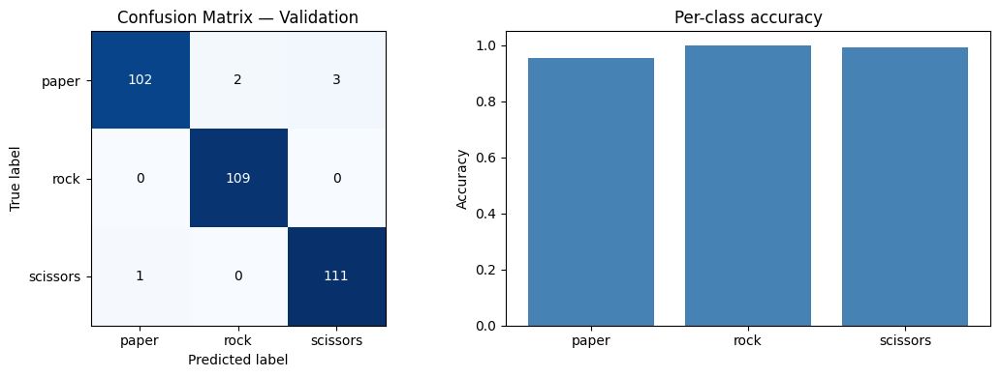

,class,precision,recall,f1,support
0,paper,0.9903,0.9533,0.9714,107
1,rock,0.9820,1.0000,0.9909,109
2,scissors,0.9737,0.9911,0.9823,112


In [99]:
cm = confusion_matrix(y_val, y_pred)
per_class_accuracy = cm.diagonal() / cm.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_confusion_matrix(cm, CLASS_NAMES, ax=axes[0], title="Confusion Matrix — Validation")
axes[1].bar(CLASS_NAMES, per_class_accuracy, color="steelblue")
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Per-class accuracy")
plt.tight_layout()
plt.show()

display(per_class_metrics(y_val, y_pred).round(4))

## 6. Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping) highlights image regions that most increase the score of a chosen class:

1. Take the feature maps of the **last convolutional layer**.
2. Compute the gradient of the class score with respect to those feature maps.
3. Average the gradients per channel to get channel importance weights.
4. Form a weighted sum of feature maps and keep only positive values (ReLU).

The heatmap is upsampled and overlaid on the image. **Important:** Grad-CAM shows where the model's *output is sensitive*; it does **not** prove causality or that the model "understands" the hand. It should be treated as a qualitative diagnostic.

Last convolutional layer: conv_3


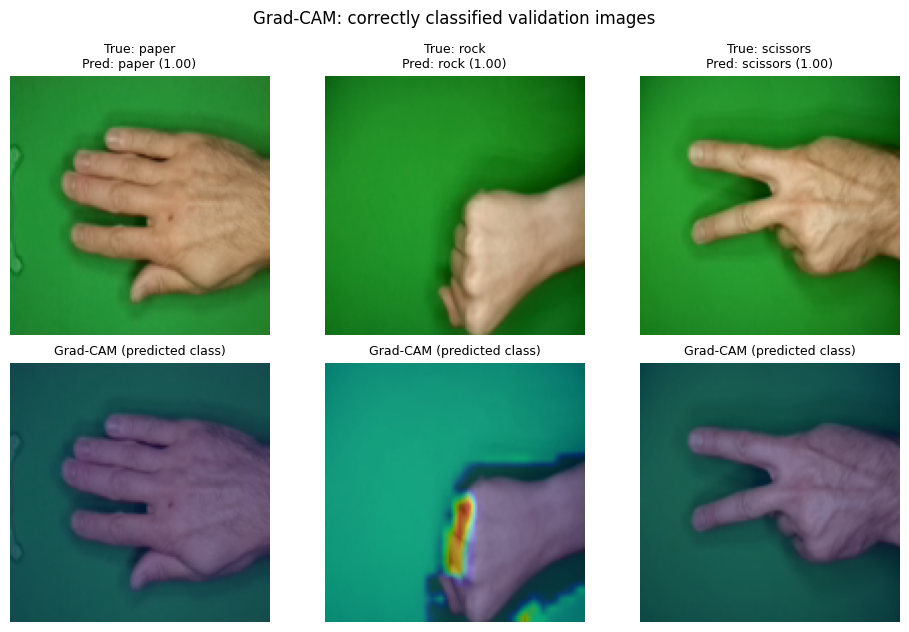

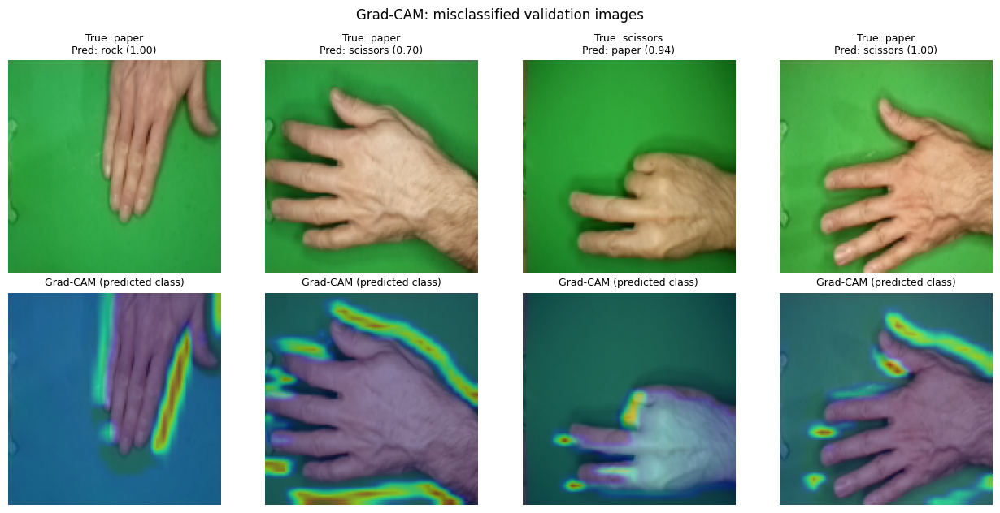

In [100]:
last_conv_layer_name = find_last_conv_layer(model)
print("Last convolutional layer:", last_conv_layer_name)

rng = np.random.default_rng(RANDOM_STATE)


def show_gradcam_examples(indices, title):
    if len(indices) == 0:
        print(f"No examples available for: {title}")
        return
    fig, axes = plt.subplots(2, len(indices), figsize=(3.2 * len(indices), 6.4), squeeze=False)
    for column, index in enumerate(indices):
        heatmap = make_gradcam_heatmap(X_val[index:index + 1], model, last_conv_layer_name, class_index=int(y_pred[index]))
        axes[0, column].imshow(X_val_uint8[index])
        axes[0, column].set_title(f"True: {CLASS_NAMES[y_val[index]]}\nPred: {CLASS_NAMES[y_pred[index]]} ({confidence[index]:.2f})", fontsize=9)
        axes[1, column].imshow(overlay_heatmap(X_val_uint8[index], heatmap))
        axes[1, column].set_title("Grad-CAM (predicted class)", fontsize=9)
        axes[0, column].axis("off"); axes[1, column].axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# One correct example per class (chosen reproducibly)
correct_indices = []
for class_index in range(len(CLASS_NAMES)):
    candidates = np.where((y_val == class_index) & is_correct)[0]
    if len(candidates) > 0:
        correct_indices.append(int(rng.choice(candidates)))
show_gradcam_examples(correct_indices, "Grad-CAM: correctly classified validation images")

# Up to four misclassified examples
wrong_candidates = np.where(~is_correct)[0]
wrong_indices = [int(i) for i in rng.permutation(wrong_candidates)[:4]]
show_gradcam_examples(wrong_indices, "Grad-CAM: misclassified validation images")

## Interpreting the Heatmaps

For each example, inspect whether the highlighted (red/yellow) area overlaps the hand or falls on background or borders. Consistent focus on the hand supports (but does not prove) that the model uses hand shape; consistent focus on background regions would suggest a possible shortcut. Only a small number of images is shown, so no general conclusion should be drawn from this figure alone.

## Conclusions

* Confidence, correctness and high-confidence errors were quantified on the validation set.
* Grad-CAM offers a qualitative view of the regions influencing predictions, with the limitations stated above.
* **Next:** Lesson 10 packages the reusable code into `src/` modules.

# Part 10 — Reproducible Pipeline and Reusable Modules

## Learning Objectives

* Move repeated code into reusable modules in `src/`
* Demonstrate every module function
* Verify that the permanent split can be reproduced exactly

In [101]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## 1. Imports

In [102]:
import os
import sys

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    IMAGE_EXTENSIONS,
    RANDOM_STATE,
    create_dataset_split,
    create_image_dataframe,
    find_dataset_root,
    get_partition,
    load_images,
    normalize_images,
    remove_invalid_and_duplicate_images,
    save_dataset_split,
)
from src.feature_extraction import HOG_PARAMETERS, extract_hog_features
from src.models import build_ann, build_cnn, build_cnn_feature_extractor
from src.evaluation import (
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

## 2. Project Modules

| Module | Contents |
|---|---|
| `src/preprocessing.py` | constants, dataset discovery, image DataFrame, split creation/saving, image loading, normalisation |
| `src/feature_extraction.py` | `extract_hog_features()` |
| `src/models.py` | `build_ann()`, `build_cnn()`, `build_cnn_feature_extractor()` and further builders |
| `src/evaluation.py` | `calculate_metrics()`, `classification_report()`, `confusion_matrix()`, saving and plotting helpers |

In [103]:
print("Class names:", CLASS_NAMES)
print("Class mapping:", CLASS_TO_INDEX)
print("Random state:", RANDOM_STATE)
print("Image extensions:", sorted(IMAGE_EXTENSIONS))
print("HOG parameters:", HOG_PARAMETERS)

Class names: ['paper', 'rock', 'scissors']
Class mapping: {'paper': 0, 'rock': 1, 'scissors': 2}
Random state: 42
Image extensions: ['.bmp', '.jpeg', '.jpg', '.png', '.webp']
HOG parameters: {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2), 'block_norm': 'L2-Hys'}


## 3. Preprocessing Functions

In [104]:
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
dataset_root = find_dataset_root(dataset_path)

image_dataframe = create_image_dataframe(dataset_root)
print("Images found:", len(image_dataframe))
display(image_dataframe.head())

Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Images found: 2188


,relative_path,label,label_index
0,paper/04l5I8TqdzF9WDMJ.png,paper,0
1,paper/0Og76sl5CJhbxWWx.png,paper,0
2,paper/0RA9rcrv8iVvuDDU.png,paper,0
3,paper/0Uomd0HvOB33m47I.png,paper,0
4,paper/0a3UtNzl5Ll3sq8K.png,paper,0


### Reproducing the Permanent Split

Re-creating the split from scratch with the same function and seed must give exactly the stored permanent split. This is a reproducibility check; the stored file is **not** overwritten.

In [105]:
cleaned_dataframe = remove_invalid_and_duplicate_images(image_dataframe, dataset_root)
recreated_split = create_dataset_split(cleaned_dataframe, random_state=RANDOM_STATE)

permanent_split_path = f"{RESULTS_DIR}/metrics/dataset_split.csv"
if os.path.exists(permanent_split_path):
    permanent_split = pd.read_csv(permanent_split_path)
    is_identical = permanent_split.equals(recreated_split)
    print("Recreated split identical to permanent split:", is_identical)
else:
    save_dataset_split(recreated_split, permanent_split_path)
    permanent_split = recreated_split
    print("Permanent split did not exist; created and saved it.")

display(pd.crosstab(permanent_split["split"], permanent_split["label"], margins=True))

Removed corrupted images: 0
Removed exact duplicates: 0
Recreated split identical to permanent split: True


label,paper,rock,scissors,All
split,,,,
test,107,109,113,329
train,498,508,525,1531
validation,107,109,112,328
All,712,726,750,2188


### Loading and Normalising Images

In [106]:
validation_df = get_partition(permanent_split, "validation")
X_val_uint8 = load_images(dataset_root, validation_df["relative_path"], image_size=(64, 64))
X_val_normalized = normalize_images(X_val_uint8)
y_val = validation_df["label_index"].to_numpy()

print("uint8 images:", X_val_uint8.shape, X_val_uint8.dtype, "| range:", X_val_uint8.min(), X_val_uint8.max())
print("normalised images:", X_val_normalized.shape, X_val_normalized.dtype, "| range:", X_val_normalized.min(), X_val_normalized.max())

uint8 images: (328, 64, 64, 3) uint8 | range: 0 255
normalised images: (328, 64, 64, 3) float32 | range: 0.0 1.0


## 4. Feature Extraction

In [107]:
hog_features = extract_hog_features(X_val_uint8[:10], image_size=(128, 128))
print("HOG features for 10 images:", hog_features.shape)

HOG features for 10 images: (10, 8100)


## 5. Model Builders

In [108]:
ann = build_ann(input_dim=64 * 64 * 3)
cnn = build_cnn(input_shape=(128, 128, 3), use_batch_norm=True)
feature_extractor = build_cnn_feature_extractor(cnn)

print("ANN parameters:", ann.count_params())
print("CNN parameters:", cnn.count_params())
print("CNN feature extractor output shape:", feature_extractor.output_shape)

ANN parameters: 3179267
CNN parameters: 3305923
CNN feature extractor output shape: (None, 128)


## 6. Evaluation Functions

The evaluation functions are demonstrated with a trivial majority-class predictor, which serves as a chance-level reference and shows the output format. This is a demonstration only, not a real model result.

,majority-class baseline
accuracy,0.341463
precision_weighted,0.116597
recall_weighted,0.341463
f1_weighted,0.173836
precision_macro,0.113821
recall_macro,0.333333
f1_macro,0.169697


              precision    recall  f1-score   support

       paper       0.00      0.00      0.00       107
        rock       0.00      0.00      0.00       109
    scissors       0.34      1.00      0.51       112

    accuracy                           0.34       328
   macro avg       0.11      0.33      0.17       328
weighted avg       0.12      0.34      0.17       328



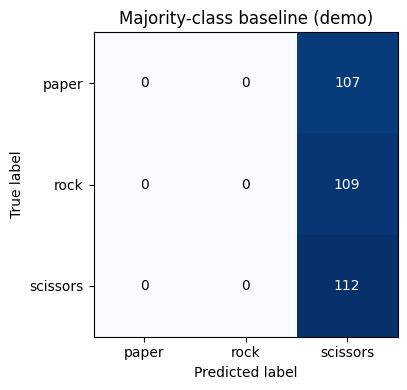

Saved: ../results/metrics/pipeline_demo_metrics.csv


In [109]:
majority_class = int(np.bincount(y_val).argmax())
y_demo_pred = np.full_like(y_val, fill_value=majority_class)

metrics = calculate_metrics(y_val, y_demo_pred)
display(pd.Series(metrics).to_frame("majority-class baseline"))
print(classification_report(y_val, y_demo_pred))

plot_confusion_matrix(confusion_matrix(y_val, y_demo_pred), CLASS_NAMES, title="Majority-class baseline (demo)")
plt.tight_layout()
plt.show()

save_metrics(pd.DataFrame([metrics]), f"{RESULTS_DIR}/metrics/pipeline_demo_metrics.csv")

## Conclusions

* All shared logic now lives in `src/`, so later notebooks import rather than copy code.
* The permanent split can be regenerated deterministically, which is confirmed by the check above.
* **Next:** Lesson 11 runs a controlled ablation study on the CNN.

# Part 11 — CNN Ablation Study

## Learning Objectives

* Isolate the effect of augmentation, Batch Normalisation and callbacks
* Keep all other variables controlled (data, seed, epochs, architecture)
* Select configurations using validation data only

In [110]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## Ablation Design

| # | Configuration | Augmentation | BatchNorm | Callbacks |
|---|---|---|---|---|
| 1 | Baseline CNN | – | – | – |
| 2 | CNN + augmentation | ✓ | – | – |
| 3 | CNN + BatchNorm | – | ✓ | – |
| 4 | CNN + augmentation + BatchNorm | ✓ | ✓ | – |
| 5 | Improved CNN | ✓ | ✓ | EarlyStopping + ReduceLROnPlateau |

Controlled factors: the same permanent split, the same seed (`RANDOM_STATE`) before every run, the same architecture and optimiser, the same batch size and the same maximum of 20 epochs. Configurations 1–4 use the weights from the final epoch; configuration 5 restores the best-validation-loss weights. A single run per configuration cannot separate real effects from seed noise (see Lesson 15).

## 1. Imports

In [111]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from src.models import build_cnn
from src.preprocessing import AUGMENTATION_KWARGS

## 2. Load the Permanent Split

In [112]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


In [113]:
IMAGE_SIZE = (128, 128)
EPOCHS = 20
BATCH_SIZE = 32

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

## 3. Run the Experiments

In [114]:
ablation_configs = [
    ("1. Baseline CNN",                       False, False, False),
    ("2. CNN + Augmentation",                 True,  False, False),
    ("3. CNN + BatchNorm",                    False, True,  False),
    ("4. CNN + Augmentation + BatchNorm",     True,  True,  False),
    ("5. Improved CNN (Aug + BN + Callbacks)", True,  True,  True),
]

ablation_rows = []
histories = {}

for name, use_augmentation, use_batch_norm, use_callbacks in ablation_configs:
    set_seed(RANDOM_STATE)
    model = build_cnn(input_shape=(128, 128, 3), use_batch_norm=use_batch_norm)

    callbacks = []
    if use_callbacks:
        callbacks = [
            EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
        ]

    start_time = time.perf_counter()
    if use_augmentation:
        train_generator = ImageDataGenerator(**AUGMENTATION_KWARGS["Combined"]).flow(
            X_train, y_train, batch_size=BATCH_SIZE, seed=RANDOM_STATE
        )
        history = model.fit(train_generator, validation_data=(X_val, y_val),
                            epochs=EPOCHS, callbacks=callbacks, verbose=0)
    else:
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            batch_size=BATCH_SIZE, epochs=EPOCHS, callbacks=callbacks, verbose=0)
    training_time_sec = time.perf_counter() - start_time

    y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    row = build_results_row(name, "validation", y_val, y_val_pred,
                            parameter_count=model.count_params(), training_time_sec=training_time_sec)
    row["augmentation"] = use_augmentation
    row["batch_norm"] = use_batch_norm
    row["callbacks"] = use_callbacks
    row["epochs_run"] = len(history.history["loss"])
    row["val_loss_final"] = history.history["val_loss"][-1]
    ablation_rows.append(row)
    histories[name] = history.history
    print(f"Finished: {name} | epochs run: {row['epochs_run'].iloc[0]} | val accuracy: {row['accuracy'].iloc[0]:.4f}")

ablation_df = pd.concat(ablation_rows, ignore_index=True)

Finished: 1. Baseline CNN | epochs run: 20 | val accuracy: 0.9756
Finished: 2. CNN + Augmentation | epochs run: 20 | val accuracy: 0.9878
Finished: 3. CNN + BatchNorm | epochs run: 20 | val accuracy: 0.9238
Finished: 4. CNN + Augmentation + BatchNorm | epochs run: 20 | val accuracy: 0.7774
Finished: 5. Improved CNN (Aug + BN + Callbacks) | epochs run: 6 | val accuracy: 0.3323


## 4. Results (Validation Set)

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,epochs_run
0,1. Baseline CNN,0.9756,0.9759,0.9756,0.9755,0.9755,20
1,2. CNN + Augmentation,0.9878,0.9880,0.9878,0.9877,0.9877,20
2,3. CNN + BatchNorm,0.9238,0.9336,0.9238,0.9233,0.9227,20
3,4. CNN + Augmentation + BatchNorm,0.7774,0.8545,0.7774,0.7658,0.7667,20
4,5. Improved CNN (Aug + BN + Callbacks),0.3323,0.1104,0.3323,0.1658,0.1663,6


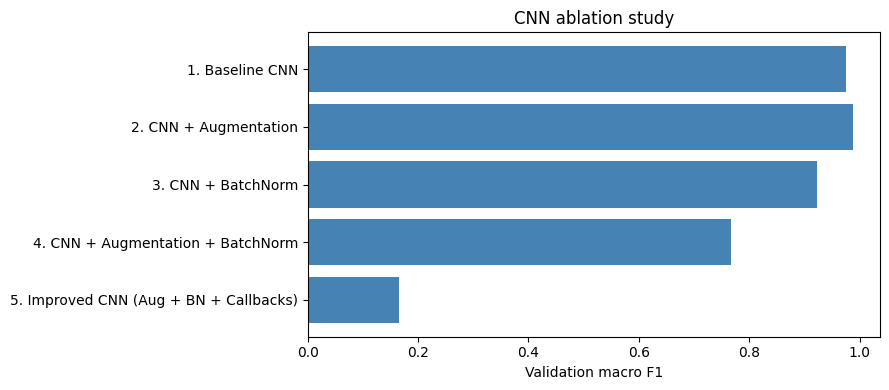

Best configuration by validation macro F1: 2. CNN + Augmentation


In [115]:
display_columns = ["model", "accuracy", "precision_weighted", "recall_weighted", "f1_weighted", "f1_macro", "epochs_run"]
display(ablation_df[display_columns].round(4))

fig, axis = plt.subplots(figsize=(9, 4))
axis.barh(ablation_df["model"], ablation_df["f1_macro"], color="steelblue")
axis.invert_yaxis(); axis.set_xlabel("Validation macro F1"); axis.set_title("CNN ablation study")
plt.tight_layout()
plt.show()

best_row = ablation_df.sort_values(["f1_macro", "val_loss_final"], ascending=[False, True]).iloc[0]
print("Best configuration by validation macro F1:", best_row["model"])

## 5. Save Results

In [116]:
save_metrics(ablation_df, f"{RESULTS_DIR}/metrics/cnn_ablation_results.csv")

Saved: ../results/metrics/cnn_ablation_results.csv


## Conclusions

* Each factor was added while other variables were held constant, and configurations were compared using validation metrics only.
* With a single run per configuration and a small validation set, small differences may reflect random variation rather than real effects.
* The test set was not used.
* **Next:** Lesson 12 tunes hyperparameters manually.

# Part 12 — Manual Hyperparameter Tuning

## Learning Objectives

* Vary hyperparameters systematically (one factor at a time around a base configuration)
* Select the configuration using validation performance only
* Save the selected configuration for later lessons

In [117]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [118]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

import json

from src.models import build_cnn

## 2. Load the Permanent Split

In [119]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


In [120]:
IMAGE_SIZE = (128, 128)
MAX_EPOCHS = 25

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

## 3. Search Space

Starting from a base configuration, one hyperparameter is changed at a time: learning rate, dropout, batch size, filter counts, dense units and optimiser. This is a small, interpretable search rather than an exhaustive grid.

All runs use Batch Normalisation, no augmentation (augmentation is studied in Lesson 14), a fixed seed and EarlyStopping (patience 5, best weights restored). Selection uses **validation macro F1**, with lower validation loss as a tie-breaker. The test set is not used.

In [121]:
base_config = {
    "learning_rate": 1e-3,
    "dropout_rate": 0.40,
    "batch_size": 32,
    "filters": (32, 64, 128),
    "dense_units": 128,
    "optimizer": "adam",
}

variations = [
    ("base", {}),
    ("lr=3e-4", {"learning_rate": 3e-4}),
    ("lr=3e-3", {"learning_rate": 3e-3}),
    ("dropout=0.2", {"dropout_rate": 0.20}),
    ("dropout=0.5", {"dropout_rate": 0.50}),
    ("batch=64", {"batch_size": 64}),
    ("filters=16-32-64", {"filters": (16, 32, 64)}),
    ("dense=256", {"dense_units": 256}),
    ("optimizer=rmsprop", {"optimizer": "rmsprop"}),
]

search_configs = [(name, {**base_config, **changes}) for name, changes in variations]
print("Number of configurations:", len(search_configs))

Number of configurations: 9


## 4. Run the Search

In [122]:
tuning_rows = []
best = {"key": None, "model": None, "config": None, "name": None, "best_epoch": None,
        "training_time": None}

for name, config in search_configs:
    set_seed(RANDOM_STATE)
    model = build_cnn(
        input_shape=(128, 128, 3),
        filters=config["filters"],
        dense_units=config["dense_units"],
        dropout_rate=config["dropout_rate"],
        use_batch_norm=True,
        learning_rate=config["learning_rate"],
        optimizer=config["optimizer"],
    )

    start_time = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=config["batch_size"],
        epochs=MAX_EPOCHS,
        callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
        verbose=0,
    )
    training_time_sec = time.perf_counter() - start_time

    val_losses = history.history["val_loss"]
    best_epoch = int(np.argmin(val_losses)) + 1
    y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    metrics = calculate_metrics(y_val, y_val_pred)

    tuning_rows.append({
        "name": name, **{k: str(v) if k == "filters" else v for k, v in config.items()},
        "best_epoch": best_epoch, "val_loss": min(val_losses),
        "val_accuracy": metrics["accuracy"], "val_f1_macro": metrics["f1_macro"],
        "training_time_sec": training_time_sec,
    })
    print(f"{name:20s} | val acc {metrics['accuracy']:.4f} | val macro F1 {metrics['f1_macro']:.4f} | best epoch {best_epoch}")

    # Keep only the best model so far (higher macro F1, then lower validation loss)
    selection_key = (metrics["f1_macro"], -min(val_losses))
    if best["key"] is None or selection_key > best["key"]:
        best.update(key=selection_key, model=model, config=config, name=name,
                    best_epoch=best_epoch, training_time=training_time_sec)

tuning_df = pd.DataFrame(tuning_rows)

base                 | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
lr=3e-4              | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
lr=3e-3              | val acc 0.7409 | val macro F1 0.7382 | best epoch 9
dropout=0.2          | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
dropout=0.5          | val acc 0.9634 | val macro F1 0.9629 | best epoch 18


2026-10-12 09:44:13.486480: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:44:13.642600: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


batch=64             | val acc 0.3323 | val macro F1 0.1663 | best epoch 1


2026-10-12 09:44:29.696616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:44:29.836787: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:44:34.155326: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:44:34.295244: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


filters=16-32-64     | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
dense=256            | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
optimizer=rmsprop    | val acc 0.9695 | val macro F1 0.9696 | best epoch 12


## 5. Validation Results

In [123]:
display(tuning_df.sort_values(["val_f1_macro", "val_loss"], ascending=[False, True]).round(4))
print("Selected configuration:", best["name"])

,name,learning_rate,dropout_rate,batch_size,filters,dense_units,optimizer,best_epoch,val_loss,val_accuracy,val_f1_macro,training_time_sec
8,optimizer=rmsprop,0.0010,0.4,32,"(32, 64, 128)",128,rmsprop,12,0.2203,0.9695,0.9696,28.9975
4,dropout=0.5,0.0010,0.5,32,"(32, 64, 128)",128,adam,18,0.0993,0.9634,0.9629,37.5215
2,lr=3e-3,0.0030,0.4,32,"(32, 64, 128)",128,adam,9,0.9392,0.7409,0.7382,26.8013
6,filters=16-32-64,0.0010,0.4,32,"(16, 32, 64)",128,adam,1,4.3271,0.3323,0.1663,16.8861
1,lr=3e-4,0.0003,0.4,32,"(32, 64, 128)",128,adam,1,4.5193,0.3323,0.1663,17.1903
5,batch=64,0.0010,0.4,64,"(32, 64, 128)",128,adam,1,7.5192,0.3323,0.1663,21.7551
0,base,0.0010,0.4,32,"(32, 64, 128)",128,adam,1,16.9907,0.3323,0.1663,17.1080
3,dropout=0.2,0.0010,0.2,32,"(32, 64, 128)",128,adam,1,19.5893,0.3323,0.1663,17.1754
7,dense=256,0.0010,0.4,32,"(32, 64, 128)",256,adam,1,23.5702,0.3323,0.1663,18.1523


Selected configuration: optimizer=rmsprop


## 6. Save the Selected Configuration and Results

In [124]:
tuned_model = best["model"]
y_val_pred = tuned_model.predict(X_val, verbose=0).argmax(axis=1)
inference_ms = measure_inference_time(lambda data: tuned_model.predict(data, verbose=0), X_val)

tuned_row = build_results_row(
    "Tuned CNN", "validation", y_val, y_val_pred,
    parameter_count=tuned_model.count_params(),
    training_time_sec=best["training_time"],
    inference_time_ms_per_image=inference_ms,
)
display(tuned_row.round(4))

selected_config = {
    "name": best["name"],
    "learning_rate": best["config"]["learning_rate"],
    "dropout_rate": best["config"]["dropout_rate"],
    "batch_size": best["config"]["batch_size"],
    "filters": list(best["config"]["filters"]),
    "dense_units": best["config"]["dense_units"],
    "optimizer": best["config"]["optimizer"],
    "use_batch_norm": True,
    "best_epoch": best["best_epoch"],
    "validation_metrics": calculate_metrics(y_val, y_val_pred),
}
with open(f"{RESULTS_DIR}/metrics/selected_config.json", "w") as file_handle:
    json.dump(selected_config, file_handle, indent=2)

tuned_model.save(f"{RESULTS_DIR}/models/tuned_cnn.keras")
save_metrics(tuning_df, f"{RESULTS_DIR}/metrics/hyperparameter_tuning_results.csv")
save_metrics(tuned_row, f"{RESULTS_DIR}/metrics/tuned_cnn_results.csv")
print(json.dumps(selected_config, indent=2))

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,Tuned CNN,validation,0.9695,0.9703,0.9695,0.9695,0.9706,0.9694,0.9696,3305923,28.9975,0.9619


Saved: ../results/metrics/hyperparameter_tuning_results.csv
Saved: ../results/metrics/tuned_cnn_results.csv
{
  "name": "optimizer=rmsprop",
  "learning_rate": 0.001,
  "dropout_rate": 0.4,
  "batch_size": 32,
  "filters": [
    32,
    64,
    128
  ],
  "dense_units": 128,
  "optimizer": "rmsprop",
  "use_batch_norm": true,
  "best_epoch": 12,
  "validation_metrics": {
    "accuracy": 0.9695121951219512,
    "precision_weighted": 0.9703156891256849,
    "recall_weighted": 0.9695121951219512,
    "f1_weighted": 0.9694802297259778,
    "precision_macro": 0.9706308544221912,
    "recall_macro": 0.9694036493101913,
    "f1_macro": 0.9695774404967231
  }
}


## Conclusions

* Hyperparameters were compared on the validation set with a fixed seed; the test set was not used.
* The reported validation scores of the selected configuration are optimistically biased because that configuration was chosen for its validation score. Lesson 19 provides the unbiased test estimate.
* The selected configuration is saved to `results/metrics/selected_config.json` for Lessons 14 and 19.
* **Next:** Lesson 13 uses KerasTuner for automated search.

# Part 13 — Automated Tuning with KerasTuner

## Learning Objectives

* Define a tunable model-building function
* Run a random search over a focused set of CNN hyperparameters
* Record validation accuracy, loss and macro F1 for every trial

In [125]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [126]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

import keras_tuner as kt
from sklearn.metrics import f1_score

from src.models import build_cnn

## 2. Load the Permanent Split

In [127]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


In [128]:
IMAGE_SIZE = (128, 128)

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

## 3. Search Space

Only four hyperparameters are tuned (base filter count, dense units, dropout and learning rate); everything else is fixed (Batch Normalisation, Adam, batch size 32, no augmentation). Restricting the space keeps the search cheap and interpretable. The objective is validation accuracy, and each trial uses EarlyStopping on validation loss.

In [129]:
def build_tunable_cnn(hp):
    base_filters = hp.Choice("base_filters", [16, 32, 48])
    return build_cnn(
        input_shape=(128, 128, 3),
        filters=(base_filters, base_filters * 2, base_filters * 4),
        dense_units=hp.Choice("dense_units", [64, 128, 256]),
        dropout_rate=hp.Float("dropout_rate", 0.2, 0.6, step=0.1),
        use_batch_norm=True,
        learning_rate=hp.Float("learning_rate", 1e-4, 1e-2, sampling="log"),
    )


MAX_TRIALS = 10

tuner = kt.RandomSearch(
    build_tunable_cnn,
    objective="val_accuracy",
    max_trials=MAX_TRIALS,
    executions_per_trial=1,
    seed=RANDOM_STATE,
    directory=f"{RESULTS_DIR}/keras_tuner",
    project_name="cnn_random_search",
    overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 4
base_filters (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 48], 'ordered': True}
dense_units (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
dropout_rate (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.6, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


## 4. Run the Search

In [130]:
start_time = time.perf_counter()
tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=0,
)
search_time_sec = time.perf_counter() - start_time
print(f"Search time: {search_time_sec:.1f} s")

2026-10-12 09:46:20.108371: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:46:20.272190: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:46:26.542844: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-12 09:46:26.702565: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Search time: 225.7 s


## 5. Trial Results

In [131]:
best_trials = tuner.oracle.get_best_trials(num_trials=MAX_TRIALS)
best_models = tuner.get_best_models(num_models=len(best_trials))

trial_rows = []
for trial, trial_model in zip(best_trials, best_models):
    val_pred = trial_model.predict(X_val, verbose=0).argmax(axis=1)
    trial_rows.append({
        "trial_id": trial.trial_id,
        **trial.hyperparameters.values,
        "best_val_accuracy": trial.score,
        "best_val_loss": trial.metrics.get_best_value("val_loss"),
        "val_f1_macro": f1_score(y_val, val_pred, average="macro"),
    })

trial_df = pd.DataFrame(trial_rows)
display(trial_df.round(4))

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,trial_id,base_filters,dense_units,dropout_rate,learning_rate,best_val_accuracy,best_val_loss,val_f1_macro
0,09,48,64,0.3,0.0010,0.9878,0.0690,0.9878
1,08,48,128,0.3,0.0040,0.6768,8.4884,0.6744
2,02,32,64,0.5,0.0017,0.5396,2.6527,0.4380
3,06,16,64,0.4,0.0023,0.3933,1.4408,0.2884
4,01,48,128,0.4,0.0001,0.3659,1.8157,0.2370
5,00,32,64,0.3,0.0003,0.3537,6.2967,0.2100
6,03,48,64,0.5,0.0001,0.3323,2.0631,0.1663
7,04,32,64,0.3,0.0010,0.3323,12.5489,0.1663
8,05,48,128,0.3,0.0007,0.3323,36.0175,0.1663
9,07,48,64,0.2,0.0004,0.3323,6.0214,0.1663


## 6. Best Model

The best model corresponds to the trial with the highest validation accuracy, using the weights of its best epoch. Because this trial and epoch were selected on the validation set, its validation scores are optimistically biased. Training time for the individual best model was not measured separately (the search time above covers all trials), so it is left empty.

In [132]:
best_model = best_models[0]
y_val_pred = best_model.predict(X_val, verbose=0).argmax(axis=1)
inference_ms = measure_inference_time(lambda data: best_model.predict(data, verbose=0), X_val)

print("Best hyperparameters:", best_trials[0].hyperparameters.values)

best_row = build_results_row(
    "KerasTuner CNN", "validation", y_val, y_val_pred,
    parameter_count=best_model.count_params(),
    training_time_sec=None,
    inference_time_ms_per_image=inference_ms,
)
display(best_row.round(4))
print(classification_report(y_val, y_val_pred))

Best hyperparameters: {'base_filters': 48, 'dense_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.0010277342442932575}


,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,KerasTuner CNN,validation,0.9878,0.9878,0.9878,0.9878,0.9877,0.9878,0.9878,2619043,None,1.1156


              precision    recall  f1-score   support

       paper       0.98      0.98      0.98       107
        rock       0.99      1.00      1.00       109
    scissors       0.99      0.98      0.99       112

    accuracy                           0.99       328
   macro avg       0.99      0.99      0.99       328
weighted avg       0.99      0.99      0.99       328



## 7. Save Results

In [133]:
best_model.save(f"{RESULTS_DIR}/models/keras_tuner_best.keras")
save_metrics(trial_df, f"{RESULTS_DIR}/metrics/keras_tuner_trials.csv")
save_metrics(best_row, f"{RESULTS_DIR}/metrics/keras_tuner_results.csv")

Saved: ../results/metrics/keras_tuner_trials.csv
Saved: ../results/metrics/keras_tuner_results.csv


## Conclusions

* KerasTuner automated a random search over a focused space; every trial's hyperparameters, validation accuracy, validation loss and validation macro F1 are recorded above.
* The test set was not used.
* **Next:** Lesson 14 compares augmentation strategies.

# Part 14 — Augmentation Experiment

## Learning Objectives

* Compare six augmentation strategies under identical conditions
* Select the best strategy using validation performance only
* Evaluate only the selected model on the test set, once

**Prerequisite (optional):** if Lesson 12 has been run, its selected configuration is used; otherwise a default architecture is used.

In [134]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [135]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

import json

from src.models import build_cnn
from src.preprocessing import AUGMENTATION_KWARGS

## 2. Load the Permanent Split

In [136]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


In [137]:
IMAGE_SIZE = (128, 128)
MAX_EPOCHS = 30

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

# Use the configuration selected in Lesson 12 when available
config_path = f"{RESULTS_DIR}/metrics/selected_config.json"
if os.path.exists(config_path):
    with open(config_path) as file_handle:
        model_config = json.load(file_handle)
    print("Using the configuration selected in Lesson 12:", model_config["name"])
else:
    model_config = {"learning_rate": 1e-3, "dropout_rate": 0.40, "batch_size": 32,
                    "filters": [32, 64, 128], "dense_units": 128, "optimizer": "adam"}
    print("Lesson 12 configuration not found; using the default configuration.")

BATCH_SIZE = model_config["batch_size"]

Using the configuration selected in Lesson 12: optimizer=rmsprop


## 3. Augmentation Strategies

The strategies are defined in `src/preprocessing.py` (`AUGMENTATION_KWARGS`) and wrapped in `ImageDataGenerator`. Augmentation is applied to **training data only**.

No Augmentation  -> None
Rotation         -> {'rotation_range': 25}
Translation      -> {'width_shift_range': 0.15, 'height_shift_range': 0.15}
Zoom             -> {'zoom_range': 0.2}
Horizontal Flip  -> {'horizontal_flip': True}
Combined         -> {'rotation_range': 15, 'width_shift_range': 0.1, 'height_shift_range': 0.1, 'zoom_range': 0.1, 'horizontal_flip': True}


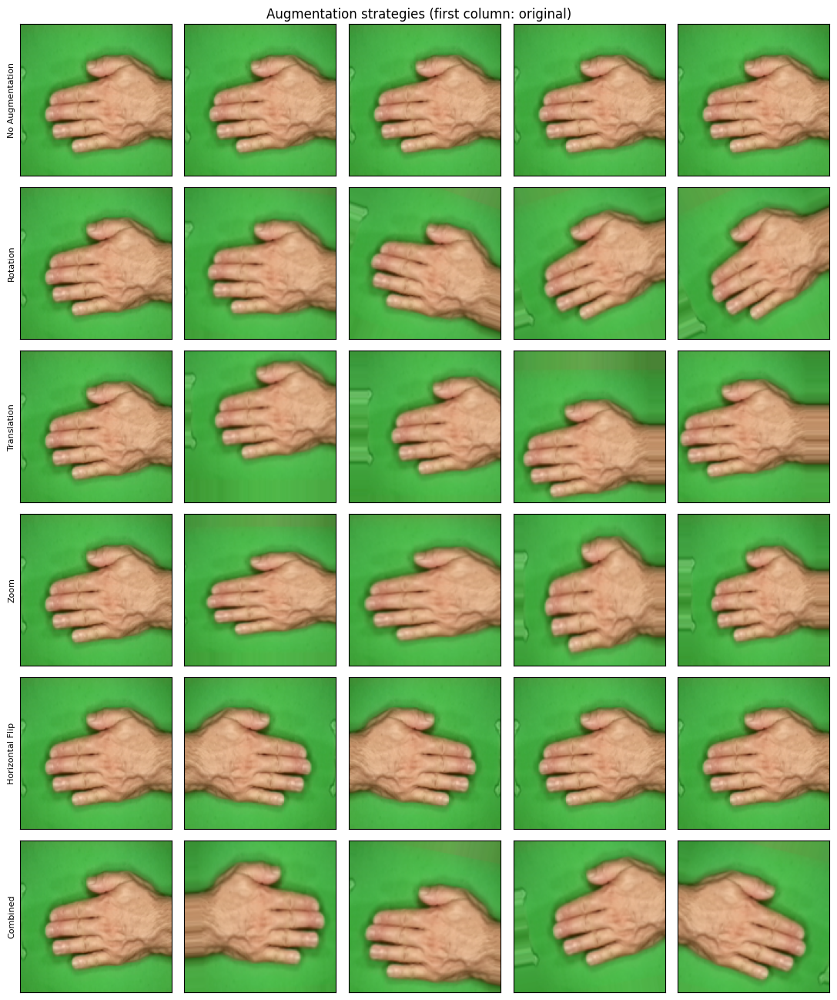

In [138]:
augmentation_configs = {
    name: (None if kwargs is None else ImageDataGenerator(**kwargs))
    for name, kwargs in AUGMENTATION_KWARGS.items()
}

for name, kwargs in AUGMENTATION_KWARGS.items():
    print(f"{name:16s} -> {kwargs}")

# Visual example of each strategy on one training image
fig, axes = plt.subplots(len(augmentation_configs), 5, figsize=(11, 2.2 * len(augmentation_configs)))
for row_index, (name, generator) in enumerate(augmentation_configs.items()):
    axes[row_index, 0].imshow(X_train[0]); axes[row_index, 0].set_ylabel(name, fontsize=8)
    if generator is None:
        for axis in axes[row_index, 1:]:
            axis.imshow(X_train[0])
    else:
        flow = generator.flow(X_train[:1], batch_size=1, seed=RANDOM_STATE, shuffle=False)
        for axis in axes[row_index, 1:]:
            axis.imshow(np.clip(next(flow)[0], 0, 1))
for axis in axes.ravel():
    axis.set_xticks([]); axis.set_yticks([])
plt.suptitle("Augmentation strategies (first column: original)")
plt.tight_layout()
plt.show()

## 4. Run the Experiment

Every strategy uses the same architecture, seed, optimiser, batch size and EarlyStopping rule (validation loss, patience 7, best weights restored). Selection is by **validation macro F1** (tie-breaker: lower validation loss).

In [139]:
experiment_rows = []
trained_models = {}
best_epochs = {}

for name, generator in augmentation_configs.items():
    set_seed(RANDOM_STATE)
    model = build_cnn(
        input_shape=(128, 128, 3),
        filters=tuple(model_config["filters"]),
        dense_units=model_config["dense_units"],
        dropout_rate=model_config["dropout_rate"],
        use_batch_norm=True,
        learning_rate=model_config["learning_rate"],
        optimizer=model_config["optimizer"],
    )
    callbacks = [EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)]

    start_time = time.perf_counter()
    if generator is None:
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            batch_size=BATCH_SIZE, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=0)
    else:
        train_generator = generator.flow(X_train, y_train, batch_size=BATCH_SIZE, seed=RANDOM_STATE)
        history = model.fit(train_generator, validation_data=(X_val, y_val),
                            epochs=MAX_EPOCHS, callbacks=callbacks, verbose=0)
    training_time_sec = time.perf_counter() - start_time

    val_losses = history.history["val_loss"]
    best_epochs[name] = int(np.argmin(val_losses)) + 1
    y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    metrics = calculate_metrics(y_val, y_val_pred)

    experiment_rows.append({
        "strategy": name, **metrics, "val_loss": min(val_losses),
        "best_epoch": best_epochs[name], "training_time_sec": training_time_sec,
    })
    trained_models[name] = model
    print(f"{name:16s} | val acc {metrics['accuracy']:.4f} | val macro F1 {metrics['f1_macro']:.4f} | best epoch {best_epochs[name]}")

experiment_df = pd.DataFrame(experiment_rows)
display(experiment_df.round(4))

No Augmentation  | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
Rotation         | val acc 0.9451 | val macro F1 0.9443 | best epoch 14
Translation      | val acc 0.4024 | val macro F1 0.2832 | best epoch 1
Zoom             | val acc 0.3415 | val macro F1 0.1697 | best epoch 1
Horizontal Flip  | val acc 0.3323 | val macro F1 0.1663 | best epoch 1
Combined         | val acc 0.9909 | val macro F1 0.9908 | best epoch 16


,strategy,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,val_loss,best_epoch,training_time_sec
0,No Augmentation,0.3323,0.1104,0.3323,0.1658,0.1108,0.3333,0.1663,9.7719,1,18.1808
1,Rotation,0.9451,0.9463,0.9451,0.9444,0.9467,0.9445,0.9443,0.3071,14,118.4392
2,Translation,0.4024,0.2951,0.4024,0.2874,0.2924,0.3947,0.2832,3.5299,1,50.9155
3,Zoom,0.3415,0.1166,0.3415,0.1738,0.1138,0.3333,0.1697,7.5213,1,49.7712
4,Horizontal Flip,0.3323,0.1104,0.3323,0.1658,0.1108,0.3333,0.1663,9.2529,1,17.3991
5,Combined,0.9909,0.9909,0.9909,0.9908,0.9908,0.9908,0.9908,0.0636,16,132.8269


## 5. Select the Best Strategy (Validation Only)

In [140]:
selected_row = experiment_df.sort_values(["f1_macro", "val_loss"], ascending=[False, True]).iloc[0]
selected_strategy = selected_row["strategy"]
selected_model = trained_models[selected_strategy]
print("Selected strategy:", selected_strategy)

selected_augmentation = {
    "strategy": selected_strategy,
    "kwargs": AUGMENTATION_KWARGS[selected_strategy],
    "best_epoch": best_epochs[selected_strategy],
}
with open(f"{RESULTS_DIR}/metrics/selected_augmentation.json", "w") as file_handle:
    json.dump(selected_augmentation, file_handle, indent=2)

save_metrics(experiment_df, f"{RESULTS_DIR}/metrics/augmentation_experiment_results.csv")

Selected strategy: Combined
Saved: ../results/metrics/augmentation_experiment_results.csv


## 6. One-Time Test Evaluation of the Selected Strategy

The strategy is now fixed. Only the selected model is evaluated on the test set, once, and the outcome is **not** used to change any decision. Do not re-run this notebook and revise choices based on the test result.

In [141]:
test_df = get_partition(split_df, "test")
X_test = normalize_images(load_images(dataset_root, test_df["relative_path"], IMAGE_SIZE))
y_test = test_df["label_index"].to_numpy()

y_test_pred = selected_model.predict(X_test, verbose=0).argmax(axis=1)
test_row = build_results_row(
    f"CNN + {selected_strategy}", "test", y_test, y_test_pred,
    parameter_count=selected_model.count_params(),
)
display(test_row.round(4))
save_metrics(test_row, f"{RESULTS_DIR}/metrics/augmentation_final_test_results.csv")

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,CNN + Combined,test,0.9909,0.9909,0.9909,0.9909,0.9909,0.9909,0.9909,3305923,None,None


Saved: ../results/metrics/augmentation_final_test_results.csv


## Conclusions

* Six augmentation strategies were compared under identical conditions; the strategy was selected using validation macro F1 only.
* The selected strategy and its best epoch are saved to `results/metrics/selected_augmentation.json`, and are used in Lesson 19.
* The test set was used once, after selection, for this experiment's final row.
* **Next:** Lesson 15 quantifies evaluation uncertainty and training variability.

# Part 15 — Model Evaluation and Statistics

## Learning Objectives

* Compute a complete set of classification metrics
* Quantify evaluation uncertainty with bootstrap confidence intervals
* Measure training variability across random seeds
* Distinguish bootstrap uncertainty from random-seed variability

**Prerequisite:** run Lesson 6 first (uses `results/models/cnn_augmented.keras`). All evaluation here uses the validation set; the test set remains untouched.

In [142]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [143]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

from src.evaluation import bootstrap_accuracy_ci, confidence_summary, per_class_metrics
from src.models import build_cnn
from src.preprocessing import AUGMENTATION_KWARGS

## 2. Load the Permanent Split and the Trained Model

In [144]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


IMAGE_SIZE = (128, 128)
MODEL_PATH = f"{RESULTS_DIR}/models/cnn_augmented.keras"
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError("Run Lesson 6 first to create " + MODEL_PATH)

model = tf.keras.models.load_model(MODEL_PATH)

X_train = normalize_images(load_images(dataset_root, train_df["relative_path"], IMAGE_SIZE))
X_val = normalize_images(load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE))
y_train = train_df["label_index"].to_numpy()
y_val = validation_df["label_index"].to_numpy()

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


## 3. Classification Metrics

,validation
accuracy,0.9878
precision_weighted,0.9878
recall_weighted,0.9878
f1_weighted,0.9878
precision_macro,0.9877
recall_macro,0.9877
f1_macro,0.9877


Per-class precision, recall, F1 and support:


,class,precision,recall,f1,support
0,paper,0.9813,0.9813,0.9813,107
1,rock,0.9908,0.9908,0.9908,109
2,scissors,0.9911,0.9911,0.9911,112


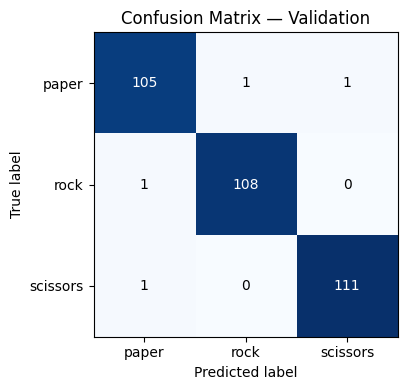

In [145]:
probabilities = model.predict(X_val, verbose=0)
y_pred = probabilities.argmax(axis=1)

metrics = calculate_metrics(y_val, y_pred)
display(pd.Series(metrics).to_frame("validation").round(4))

print("Per-class precision, recall, F1 and support:")
class_table = per_class_metrics(y_val, y_pred)
display(class_table.round(4))

cm = confusion_matrix(y_val, y_pred)
plot_confusion_matrix(cm, CLASS_NAMES, title="Confusion Matrix — Validation")
plt.tight_layout()
plt.show()

## 4. Confidence Statistics

A high-confidence error is an incorrect prediction whose predicted-class probability is at least 0.90.

In [146]:
confidence_stats = confidence_summary(probabilities, y_val, high_confidence_threshold=0.90)
display(pd.Series(confidence_stats).to_frame("value"))

,value
mean_confidence,0.996579
mean_confidence_correct,0.998553
mean_confidence_incorrect,0.836757
n_incorrect,4.000000
n_high_confidence_errors,2.000000
high_confidence_threshold,0.900000


## 5. Bootstrap Confidence Interval for Accuracy

**Bootstrap resampling:** the validation examples are resampled with replacement 1,000 times (same size as the original), accuracy is recomputed on each resample, and the 2.5th and 97.5th percentiles give a 95% interval.

This captures **sampling uncertainty of the evaluation set for a fixed, already-trained model**: how much the measured accuracy could change had a different sample of images been drawn from the same population.

Observed accuracy: 0.9878
Bootstrap mean accuracy: 0.9879
95% bootstrap confidence interval: [0.9756, 0.9970]


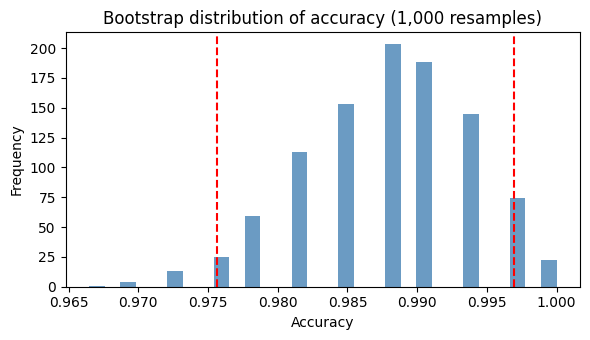

In [147]:
mean_accuracy, lower, upper, bootstrap_accuracies = bootstrap_accuracy_ci(
    y_val, y_pred, n_bootstrap=1000, confidence_level=0.95, random_state=RANDOM_STATE
)
print(f"Observed accuracy: {metrics['accuracy']:.4f}")
print(f"Bootstrap mean accuracy: {mean_accuracy:.4f}")
print(f"95% bootstrap confidence interval: [{lower:.4f}, {upper:.4f}]")

plt.figure(figsize=(6, 3.5))
plt.hist(bootstrap_accuracies, bins=30, color="steelblue", alpha=0.8)
plt.axvline(lower, color="red", linestyle="--"); plt.axvline(upper, color="red", linestyle="--")
plt.xlabel("Accuracy"); plt.ylabel("Frequency"); plt.title("Bootstrap distribution of accuracy (1,000 resamples)")
plt.tight_layout()
plt.show()

## 6. Random-Seed Training Variability

**Random-seed variability:** the same recipe (Lesson 6: Batch Normalisation, combined augmentation, EarlyStopping, ReduceLROnPlateau) is retrained from scratch with five seeds (42, 123, 456, 789, 1000). Seeds change weight initialisation, data shuffling and augmentation randomness, so each run produces a different model.

This captures **training stochasticity**: how much the result depends on the luck of the training run, even on a fixed evaluation set.

| | Bootstrap | Random seeds |
|---|---|---|
| What varies | The evaluation sample | The trained model |
| What is fixed | The trained model | The evaluation set and recipe |
| Question answered | How precise is this accuracy estimate? | How stable is the training procedure? |

The two are complementary and should not be confused: a narrow bootstrap interval does not imply a stable training procedure.

In [148]:
SEEDS = [42, 123, 456, 789, 1000]
seed_rows = []

for seed in SEEDS:
    set_seed(seed)
    seed_model = build_cnn(input_shape=(128, 128, 3), use_batch_norm=True)
    seed_generator = ImageDataGenerator(**AUGMENTATION_KWARGS["Combined"]).flow(
        X_train, y_train, batch_size=32, seed=seed
    )
    seed_history = seed_model.fit(
        seed_generator,
        validation_data=(X_val, y_val),
        epochs=50,
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        ],
        verbose=0,
    )
    seed_pred = seed_model.predict(X_val, verbose=0).argmax(axis=1)
    seed_metrics = calculate_metrics(y_val, seed_pred)
    seed_rows.append({"seed": seed, "accuracy": seed_metrics["accuracy"],
                      "f1_macro": seed_metrics["f1_macro"], "f1_weighted": seed_metrics["f1_weighted"],
                      "epochs_run": len(seed_history.history["loss"])})
    print(f"Seed {seed}: accuracy {seed_metrics['accuracy']:.4f} | macro F1 {seed_metrics['f1_macro']:.4f}")

seed_df = pd.DataFrame(seed_rows)
display(seed_df.round(4))

seed_summary = seed_df[["accuracy", "f1_macro", "f1_weighted"]].agg(["mean", "std", "min", "max"])
display(seed_summary.round(4))

Seed 42: accuracy 0.9909 | macro F1 0.9908
Seed 123: accuracy 0.9970 | macro F1 0.9969
Seed 456: accuracy 0.9878 | macro F1 0.9877
Seed 789: accuracy 0.9909 | macro F1 0.9907
Seed 1000: accuracy 0.9939 | macro F1 0.9938


,seed,accuracy,f1_macro,f1_weighted,epochs_run
0,42,0.9909,0.9908,0.9908,33
1,123,0.9970,0.9969,0.9970,41
2,456,0.9878,0.9877,0.9878,33
3,789,0.9909,0.9907,0.9908,22
4,1000,0.9939,0.9938,0.9939,34


,accuracy,f1_macro,f1_weighted
mean,0.9921,0.9920,0.9921
std,0.0035,0.0035,0.0035
min,0.9878,0.9877,0.9878
max,0.9970,0.9969,0.9970


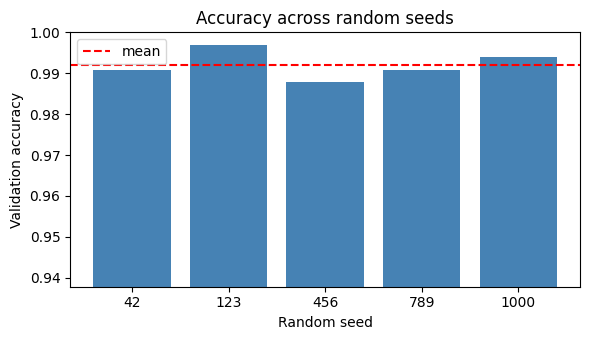

In [149]:
plt.figure(figsize=(6, 3.5))
plt.bar([str(seed) for seed in SEEDS], seed_df["accuracy"], color="steelblue")
plt.axhline(seed_df["accuracy"].mean(), color="red", linestyle="--", label="mean")
plt.ylim(max(0, seed_df["accuracy"].min() - 0.05), 1.0)
plt.xlabel("Random seed"); plt.ylabel("Validation accuracy"); plt.title("Accuracy across random seeds")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Save Results

In [150]:
statistics_df = pd.DataFrame([{
    "model": "Augmented CNN (Lesson 6)", "evaluation_split": "validation",
    **metrics, **confidence_stats,
    "bootstrap_mean_accuracy": mean_accuracy,
    "bootstrap_ci_lower": lower, "bootstrap_ci_upper": upper, "n_bootstrap": 1000,
}])
save_metrics(statistics_df, f"{RESULTS_DIR}/metrics/evaluation_statistics_validation.csv")
save_metrics(class_table, f"{RESULTS_DIR}/metrics/per_class_metrics_validation.csv")
save_metrics(seed_df, f"{RESULTS_DIR}/metrics/seed_variability_results.csv")

Saved: ../results/metrics/evaluation_statistics_validation.csv
Saved: ../results/metrics/per_class_metrics_validation.csv
Saved: ../results/metrics/seed_variability_results.csv


## Conclusions

* A full metric set, per-class results and confidence statistics were computed on the validation set.
* The bootstrap interval expresses evaluation-sample uncertainty; the seed experiment expresses training variability. Compare their sizes using the values printed above.
* Differences between models that are smaller than these uncertainty ranges should not be interpreted as real improvements.
* **Next:** Lesson 16 introduces cross-validation.

# Part 16 — Stratified K-Fold Cross-Validation

## Learning Objectives

* Understand k-fold cross-validation and why stratification matters
* Cross-validate a HOG + SVM pipeline without data leakage
* Understand why k-fold cross-validation is expensive for deep CNNs

The permanent test set is **not** used here; cross-validation runs on the development data (training + validation).

In [151]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## Cross-Validation Concept

In **stratified 5-fold cross-validation** the development data is divided into five folds with the same class proportions as the full data. Each fold serves once as the validation fold while the remaining four are used for training, giving five estimates whose mean and standard deviation summarise performance and its variability across data subsets.

## 1. Imports

In [152]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.feature_extraction import extract_hog_features

## 2. Load the Development Data (Train + Validation)

In [153]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


IMAGE_SIZE = (128, 128)

development_df = pd.concat([train_df, validation_df], ignore_index=True)
X_development = load_images(dataset_root, development_df["relative_path"], IMAGE_SIZE)
y_development = development_df["label_index"].to_numpy()

hog_development = extract_hog_features(X_development, IMAGE_SIZE)
print("Development images:", len(development_df))
print("HOG features:", hog_development.shape)

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.
Development images: 1859
HOG features: (1859, 8100)


## 3. Leakage-Free Pipeline

`StandardScaler` and `SVC` are combined in a scikit-learn `Pipeline`. Inside each fold, `cross_validate` calls `fit` on the training portion only, so the scaler's mean and standard deviation come exclusively from that fold's training data and are merely *applied* to the held-out fold. Scaling all data before splitting would leak information from held-out folds into training.

In [154]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Show that each fold preserves the class proportions
fold_rows = []
for fold_number, (fit_index, held_out_index) in enumerate(cv.split(hog_development, y_development), start=1):
    counts = np.bincount(y_development[held_out_index], minlength=len(CLASS_NAMES))
    fold_rows.append({"fold": fold_number, "n_train": len(fit_index), "n_held_out": len(held_out_index),
                      **{f"held_out_{name}": count for name, count in zip(CLASS_NAMES, counts)}})
display(pd.DataFrame(fold_rows))

,fold,n_train,n_held_out,held_out_paper,held_out_rock,held_out_scissors
0,1,1487,372,121,124,127
1,2,1487,372,121,124,127
2,3,1487,372,121,123,128
3,4,1487,372,121,123,128
4,5,1488,371,121,123,127


## 4. Run Cross-Validation

In [155]:
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

start_time = time.perf_counter()
cv_results = cross_validate(pipeline, hog_development, y_development, cv=cv, scoring=scoring, n_jobs=-1)
cv_time_sec = time.perf_counter() - start_time

fold_df = pd.DataFrame({
    "fold": range(1, 6),
    **{metric: cv_results[f"test_{metric}"] for metric in scoring},
    "fit_time_sec": cv_results["fit_time"],
})
display(fold_df.round(4))

summary_df = fold_df[list(scoring)].agg(["mean", "std"]).round(4)
display(summary_df)
print(f"Total cross-validation time: {cv_time_sec:.1f} s")

,fold,accuracy,precision_macro,recall_macro,f1_macro,fit_time_sec
0,1,0.9758,0.9759,0.9757,0.9758,20.5022
1,2,0.9624,0.9634,0.9620,0.9623,20.5667
2,3,0.9731,0.9737,0.9728,0.9729,20.3604
3,4,0.9812,0.9814,0.9810,0.9811,20.4705
4,5,0.9811,0.9813,0.9812,0.9812,10.6510


,accuracy,precision_macro,recall_macro,f1_macro
mean,0.9747,0.9751,0.9745,0.9747
std,0.0077,0.0074,0.0079,0.0078


Total cross-validation time: 41.6 s


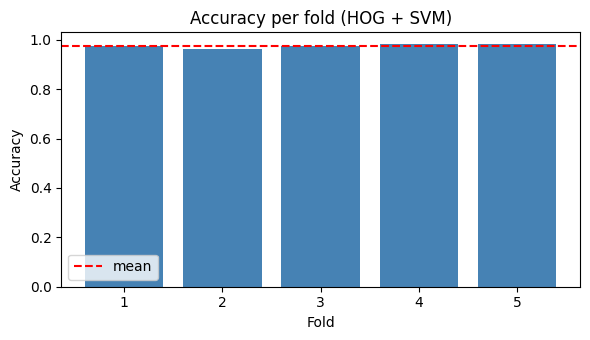

In [156]:
plt.figure(figsize=(6, 3.5))
plt.bar(fold_df["fold"].astype(str), fold_df["accuracy"], color="steelblue")
plt.axhline(fold_df["accuracy"].mean(), color="red", linestyle="--", label="mean")
plt.xlabel("Fold"); plt.ylabel("Accuracy"); plt.title("Accuracy per fold (HOG + SVM)")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Save Results

In [157]:
saved_df = pd.concat([
    fold_df.astype({"fold": str}),
    summary_df.reset_index().rename(columns={"index": "fold"}),
], ignore_index=True)
save_metrics(saved_df, f"{RESULTS_DIR}/metrics/cross_validation_results.csv")

Saved: ../results/metrics/cross_validation_results.csv


## Why Is K-Fold Cross-Validation Expensive for Deep CNNs?

With k folds, a model must be trained k times from scratch. A HOG + SVM model trains quickly, but a CNN may need tens of epochs of gradient descent per run, so cost multiplies by k (and again by the number of hyperparameter settings if tuning is combined with cross-validation). Deep networks also usually need GPUs, and repeated training adds seed-related variance. For this reason CNN experiments in this project use a single fixed train/validation split, with variability assessed through bootstrap intervals and multiple seeds (Lesson 15).

## Conclusions

* The pipeline was cross-validated without leakage and without touching the test set.
* The mean and standard deviation across folds (printed above) summarise expected performance and its spread on the development data.
* **Next:** Lesson 17 examines individual mistakes.

# Part 17 — Error Analysis

## Learning Objectives

* Identify which classes are confused and how confidently
* Inspect misclassified images in galleries
* Compare image properties (brightness, size, background) of correct and incorrect predictions

**Prerequisite:** run Lesson 6 first (`MODEL_PATH` can be changed to analyse another model). The analysis uses validation data only. Observations are descriptive; they do not establish causes.

In [158]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Dataset Partitions and Their Roles

| Partition | Proportion | Purpose |
|---|---|---|
| Training | 70% | Fit model parameters (weights) and preprocessing objects |
| Validation | 15% | Compare models, tune hyperparameters and select configurations |
| Test | 15% | Final, one-time evaluation only; it is **not** used in this notebook |

The split is the same permanent, stratified split (`RANDOM_STATE = 42`) stored in `results/metrics/dataset_split.csv`.

## 1. Imports

In [159]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import cv2
import tensorflow as tf
from PIL import Image

from src.evaluation import per_class_metrics

## 2. Load the Permanent Split, Model and Predictions

In [160]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


IMAGE_SIZE = (128, 128)
MODEL_PATH = f"{RESULTS_DIR}/models/cnn_augmented.keras"
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError("Run Lesson 6 first to create " + MODEL_PATH)

model = tf.keras.models.load_model(MODEL_PATH)

X_val_uint8 = load_images(dataset_root, validation_df["relative_path"], IMAGE_SIZE)
X_val = normalize_images(X_val_uint8)
y_val = validation_df["label_index"].to_numpy()

probabilities = model.predict(X_val, verbose=0)
y_pred = probabilities.argmax(axis=1)

analysis_df = validation_df[["relative_path", "label"]].copy()
analysis_df["true_index"] = y_val
analysis_df["pred_index"] = y_pred
analysis_df["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
analysis_df["confidence"] = probabilities.max(axis=1)
analysis_df["correct"] = y_pred == y_val

print("Validation accuracy:", round(float(analysis_df["correct"].mean()), 4))
print("Number of errors:", int((~analysis_df["correct"]).sum()))

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.
Validation accuracy: 0.9878
Number of errors: 4


## 3. Confusion Matrix, Per-Class Errors and Most Confused Pairs

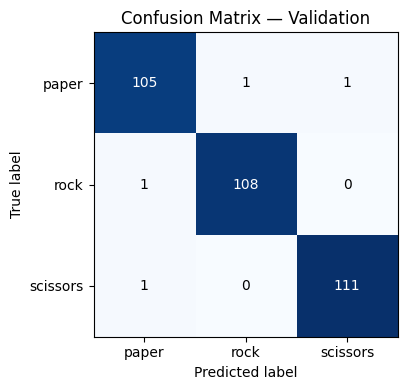

,class,support,errors,error_rate
0,paper,107,2,0.0187
1,rock,109,1,0.0092
2,scissors,112,1,0.0089


Class pairs ordered by number of confusions:


,true_class,predicted_class,count
0,paper,rock,1
1,paper,scissors,1
2,rock,paper,1
4,scissors,paper,1
3,rock,scissors,0
5,scissors,rock,0


In [161]:
cm = confusion_matrix(y_val, y_pred)
plot_confusion_matrix(cm, CLASS_NAMES, title="Confusion Matrix — Validation")
plt.tight_layout()
plt.show()

per_class_errors = pd.DataFrame({
    "class": CLASS_NAMES,
    "support": cm.sum(axis=1),
    "errors": cm.sum(axis=1) - cm.diagonal(),
})
per_class_errors["error_rate"] = per_class_errors["errors"] / per_class_errors["support"]
display(per_class_errors.round(4))

confused_pairs = pd.DataFrame(
    [{"true_class": CLASS_NAMES[i], "predicted_class": CLASS_NAMES[j], "count": int(cm[i, j])}
     for i in range(len(CLASS_NAMES)) for j in range(len(CLASS_NAMES)) if i != j]
).sort_values("count", ascending=False)
print("Class pairs ordered by number of confusions:")
display(confused_pairs)

## 4. Confidence of Errors and Correct Predictions

* **High-confidence wrong predictions:** errors with confidence ≥ 0.90.
* **Low-confidence correct predictions:** correct predictions with confidence < 0.60.

In [162]:
high_confidence_errors = analysis_df[(~analysis_df["correct"]) & (analysis_df["confidence"] >= 0.90)]
low_confidence_correct = analysis_df[(analysis_df["correct"]) & (analysis_df["confidence"] < 0.60)]

print("High-confidence errors:", len(high_confidence_errors))
print("Low-confidence correct predictions:", len(low_confidence_correct))
display(high_confidence_errors.sort_values("confidence", ascending=False).round(3))
display(low_confidence_correct.sort_values("confidence").head(10).round(3))

High-confidence errors: 2
Low-confidence correct predictions: 0


,relative_path,label,true_index,pred_index,predicted_label,confidence,correct
27,paper/KJ77yLPN943SrPZW.png,paper,0,2,scissors,0.987,False
78,paper/mkUctpckc3vjOwKa.png,paper,0,1,rock,0.961,False


,relative_path,label,true_index,pred_index,predicted_label,confidence,correct


## 5. Visual Galleries

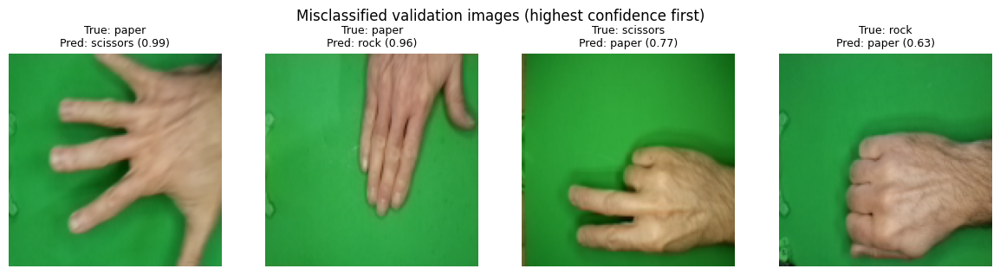

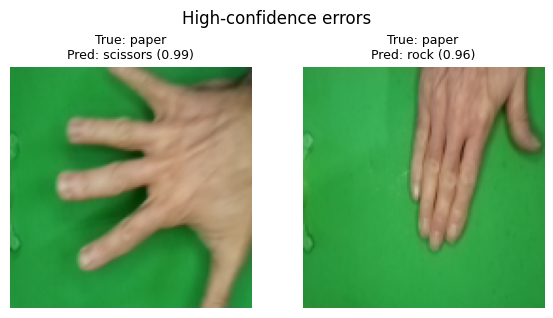

No images for: Low-confidence correct predictions


In [163]:
def show_gallery(subset, title, max_images=10, save_name=None):
    subset = subset.head(max_images)
    if len(subset) == 0:
        print(f"No images for: {title}")
        return
    n_columns = min(5, len(subset))
    n_rows = int(np.ceil(len(subset) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(3 * n_columns, 3.2 * n_rows), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, (position, row) in zip(axes.ravel(), subset.iterrows()):
        axis.imshow(X_val_uint8[position])
        axis.set_title(f"True: {row['label']}\nPred: {row['predicted_label']} ({row['confidence']:.2f})", fontsize=9)
    plt.suptitle(title)
    plt.tight_layout()
    if save_name:
        plt.savefig(f"{RESULTS_DIR}/figures/{save_name}", dpi=200, bbox_inches="tight")
    plt.show()


errors = analysis_df[~analysis_df["correct"]].sort_values("confidence", ascending=False)
show_gallery(errors, "Misclassified validation images (highest confidence first)", max_images=10,
             save_name="error_gallery_misclassified.png")
show_gallery(high_confidence_errors.sort_values("confidence", ascending=False),
             "High-confidence errors", max_images=5)
show_gallery(low_confidence_correct.sort_values("confidence"),
             "Low-confidence correct predictions", max_images=5)

## 6. Image Properties: Brightness, Size and Background

For each validation image the original file is inspected: width, height, brightness (mean grayscale), contrast (grayscale standard deviation) and **border brightness** (mean grayscale of the outer 10% frame, used here as a simple proxy for the background). These are descriptive comparisons between correct and incorrect predictions on a small number of errors, so they cannot identify causes.

Image sizes (width x height) among correct / incorrect predictions:


,correct,width,height,count
0,False,300,200,4
1,True,300,200,324


brightness               contrast              border_brightness  \
              mean  median count     mean median count              mean   
correct                                                                    
False       116.48  117.18     4    25.94  27.62     4            104.31   
True        114.33  111.43   324    28.55  28.23   324            101.66   

                       
         median count  
correct                
False    105.11     4  
True      99.03   324

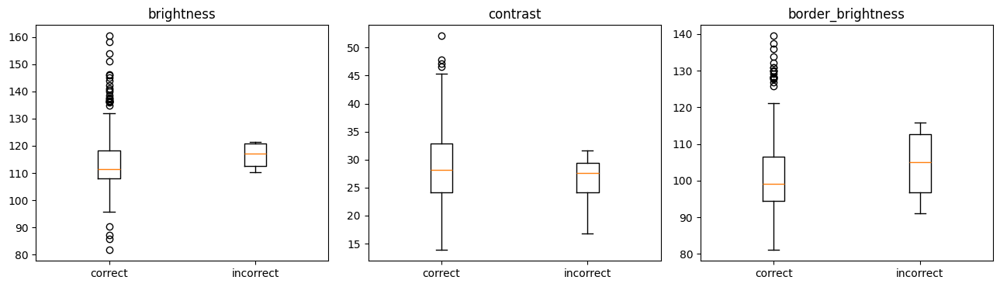

In [164]:
def image_properties(relative_path):
    with Image.open(os.path.join(dataset_root, relative_path)) as image:
        width, height = image.size
        gray = cv2.cvtColor(np.array(image.convert("RGB")), cv2.COLOR_RGB2GRAY)
    margin = max(1, int(0.10 * min(height, width)))
    border_mask = np.ones_like(gray, dtype=bool)
    border_mask[margin:-margin, margin:-margin] = False
    return {"width": width, "height": height, "brightness": float(gray.mean()),
            "contrast": float(gray.std()), "border_brightness": float(gray[border_mask].mean())}


properties_df = pd.DataFrame([image_properties(p) for p in analysis_df["relative_path"]])
analysis_df = pd.concat([analysis_df, properties_df], axis=1)

print("Image sizes (width x height) among correct / incorrect predictions:")
display(analysis_df.groupby(["correct", "width", "height"]).size().rename("count").reset_index())

display(analysis_df.groupby("correct")[["brightness", "contrast", "border_brightness"]].agg(["mean", "median", "count"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for axis, column in zip(axes, ["brightness", "contrast", "border_brightness"]):
    groups = [analysis_df.loc[analysis_df["correct"] == flag, column] for flag in (True, False)]
    axis.boxplot(groups, tick_labels=["correct", "incorrect"])
    axis.set_title(column)
plt.tight_layout()
plt.show()

## 7. Save the Error Table

In [165]:
save_metrics(analysis_df, f"{RESULTS_DIR}/metrics/error_analysis_validation.csv")

Saved: ../results/metrics/error_analysis_validation.csv


## Possible Dataset Ambiguity

Inspect the galleries: some hand poses can look similar between classes (for example, partially closed hands), and mislabelled or ambiguous images would appear as confident errors. Whether any specific image is ambiguous or mislabelled must be judged by looking at the image itself; the numbers above only point to candidates.

## Conclusions

* The confusion matrix and pair table show which classes the model mixes up on the validation set.
* Galleries and image-property comparisons describe the errors without claiming causes, especially given the small number of errors.
* **Next:** Lesson 18 compares all models side by side.

# Part 18 — Model Comparison

## Learning Objectives

* Combine the saved results of all major models into one fair table
* Compare accuracy, precision, recall, F1, parameter count, training time and inference time
* Rank models with an explicitly stated criterion

**Prerequisite:** run Lessons 3, 4, 5, 6, 7, 8, 12 and 13 so that their result files exist. Missing files are reported, and no values are invented.

In [166]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## 1. Imports

In [167]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RESULTS_DIR = "../results"

## 2. Load the Saved Results

Every model was evaluated on the **same validation set** with the same metric code, so the comparison is like-for-like. The test set is not used for comparison or ranking (final test evaluation is done once in Lesson 19).

Notes for interpreting the columns:

* **Parameter count** is reported for Keras models; it is left empty for scikit-learn models where it is not meaningfully comparable.
* **Training time** and **inference time** are wall-clock measurements from the machine that ran each notebook. Times depend on hardware, so they are only comparable when all notebooks were executed on the same machine.
* Inference time for HOG models includes HOG extraction; for the hybrid model it includes HOG extraction, scaling, CNN features and classification. Image loading is excluded for all models.
* The KerasTuner training time is empty because it was not measured for the single best model.

In [168]:
model_order = [
    "HOG + Logistic Regression", "HOG + SVM", "HOG + Random Forest", "ANN",
    "Baseline CNN", "Augmented CNN", "MobileNetV2", "CNN + HOG Hybrid",
    "Tuned CNN", "KerasTuner CNN",
]

result_files = [
    "traditional_ml_results.csv", "ann_results.csv", "cnn_baseline_results.csv",
    "cnn_augmented_results.csv", "mobilenetv2_results.csv", "hybrid_results.csv",
    "tuned_cnn_results.csv", "keras_tuner_results.csv",
]

frames, missing_files = [], []
for file_name in result_files:
    path = f"{RESULTS_DIR}/metrics/{file_name}"
    if os.path.exists(path):
        frames.append(pd.read_csv(path))
    else:
        missing_files.append(file_name)

if missing_files:
    print("Missing result files (run the corresponding lessons):", missing_files)
if not frames:
    raise FileNotFoundError("No result files were found.")

comparison_df = pd.concat(frames, ignore_index=True)
comparison_df["model"] = pd.Categorical(comparison_df["model"], categories=model_order, ordered=True)
comparison_df = comparison_df.sort_values("model").reset_index(drop=True)
print("Evaluation splits present:", comparison_df["evaluation_split"].unique().tolist())

Evaluation splits present: ['validation']


## 3. Comparison Table

In [169]:
table_columns = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
                 "parameter_count", "training_time_sec", "inference_time_ms_per_image"]
display(comparison_df[table_columns].round(4))

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,parameter_count,training_time_sec,inference_time_ms_per_image
0,HOG + Logistic Regression,0.9482,0.9504,0.9476,0.9480,0.9481,NaN,1.1996,6.1877
1,HOG + SVM,0.9665,0.9679,0.9659,0.9662,0.9663,NaN,11.3497,15.5045
2,HOG + Random Forest,0.9421,0.9427,0.9417,0.9420,0.9420,NaN,12.4211,6.3264
3,ANN,0.7744,0.8008,0.7743,0.7785,0.7776,3179267.0,14.8333,1.3527
4,Baseline CNN,0.9817,0.9820,0.9814,0.9815,0.9816,3305027.0,32.2817,2.8464
5,Augmented CNN,0.9878,0.9877,0.9877,0.9877,0.9878,3305923.0,187.7973,3.5162
6,MobileNetV2,0.9970,0.9971,0.9969,0.9970,0.9970,2422339.0,105.1428,27.7889
7,CNN + HOG Hybrid,0.9878,0.9879,0.9877,0.9877,0.9878,5444547.0,8.5888,8.1784
8,Tuned CNN,0.9695,0.9706,0.9694,0.9696,0.9695,3305923.0,28.9975,0.9619
9,KerasTuner CNN,0.9878,0.9877,0.9878,0.9878,0.9878,2619043.0,NaN,1.1156


## 4. Ranking Criterion

Models are ranked by **validation macro F1**, the unweighted mean of per-class F1 scores. Macro F1 treats each class equally and combines precision and recall, which is appropriate for a three-class problem. Accuracy is shown alongside it. Ranking is by this single quality metric only; size and speed are reported separately because their importance depends on the deployment context. Models with nearly identical scores should be treated as tied, since validation-set differences may lie within the uncertainty quantified in Lesson 15.

In [170]:
ranking_df = comparison_df[["model", "f1_macro", "accuracy"]].sort_values("f1_macro", ascending=False).reset_index(drop=True)
ranking_df.index = ranking_df.index + 1
ranking_df.index.name = "rank"
display(ranking_df.round(4))

,model,f1_macro,accuracy
rank,,,
1,MobileNetV2,0.9970,0.9970
2,KerasTuner CNN,0.9878,0.9878
3,CNN + HOG Hybrid,0.9877,0.9878
4,Augmented CNN,0.9877,0.9878
5,Baseline CNN,0.9815,0.9817
6,Tuned CNN,0.9696,0.9695
7,HOG + SVM,0.9662,0.9665
8,HOG + Logistic Regression,0.9480,0.9482
9,HOG + Random Forest,0.9420,0.9421


## 5. Visual Comparison

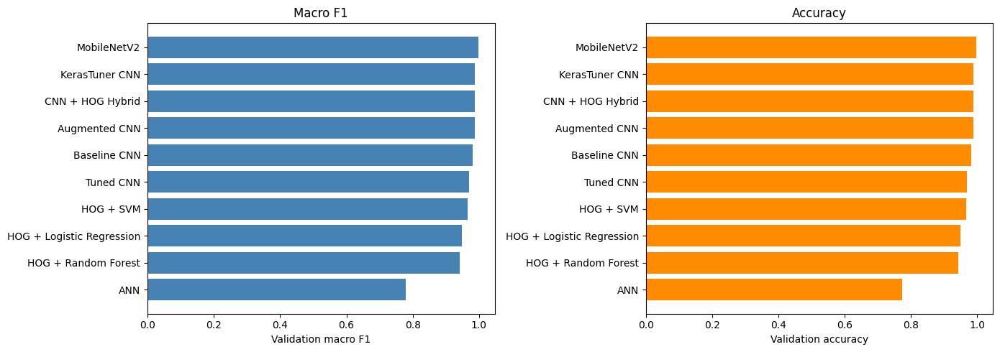

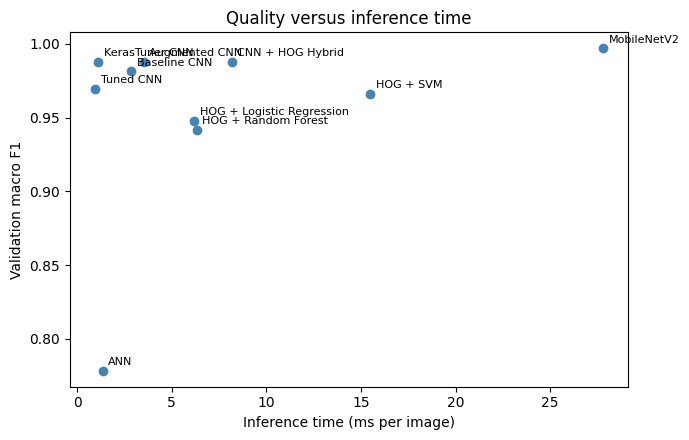

In [171]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = comparison_df.sort_values("f1_macro")
axes[0].barh(plot_df["model"].astype(str), plot_df["f1_macro"], color="steelblue")
axes[0].set_xlabel("Validation macro F1"); axes[0].set_title("Macro F1")
axes[1].barh(plot_df["model"].astype(str), plot_df["accuracy"], color="darkorange")
axes[1].set_xlabel("Validation accuracy"); axes[1].set_title("Accuracy")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Quality versus inference cost (only for models with a measured inference time)
timed_df = comparison_df.dropna(subset=["inference_time_ms_per_image"])
if len(timed_df) > 0:
    plt.figure(figsize=(7, 4.5))
    plt.scatter(timed_df["inference_time_ms_per_image"], timed_df["f1_macro"], color="steelblue")
    for _, row in timed_df.iterrows():
        plt.annotate(str(row["model"]), (row["inference_time_ms_per_image"], row["f1_macro"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
    plt.xlabel("Inference time (ms per image)"); plt.ylabel("Validation macro F1")
    plt.title("Quality versus inference time")
    plt.tight_layout()
    plt.show()

## 6. Save the Comparison

In [172]:
comparison_df["model"] = comparison_df["model"].astype(str)
comparison_df.to_csv(f"{RESULTS_DIR}/metrics/model_comparison.csv", index=False)
print("Saved:", f"{RESULTS_DIR}/metrics/model_comparison.csv")

Saved: ../results/metrics/model_comparison.csv


## Conclusions

* All available models were compared on the same validation set with the same metrics; missing models (if any) were reported rather than filled in.
* The ranking uses validation macro F1 only; the caveats above apply.
* Because the selected models were chosen using the validation set, these scores are optimistic. The unbiased estimate for the chosen final model comes from Lesson 19.
* **Next:** Lesson 19 runs the final locked experiment.

# Part 19 — Final Locked Experiment

## Learning Objectives

* Train the final model with a locked configuration on the development data (train + validation)
* Evaluate once on the untouched test set
* Produce the final metrics, confusion matrix and saved model

**Prerequisites:** Lessons 12 and 14 must have been run, because they provide the locked architecture (`selected_config.json`) and augmentation strategy (`selected_augmentation.json`).

In [173]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## Locked Decisions

Everything below was decided **before** this notebook using only training and validation data:

| Decision | Source |
|---|---|
| Architecture and hyperparameters | `results/metrics/selected_config.json` (Lesson 12) |
| Augmentation strategy | `results/metrics/selected_augmentation.json` (Lesson 14) |
| Number of training epochs | Best epoch found in Lesson 14 |
| Preprocessing | 128 × 128 RGB, pixel values divided by 255 |
| Random seed | `RANDOM_STATE = 42` |

The final model is trained on **train + validation** (85% of the data) because no further validation is needed once decisions are locked, and more data typically helps. It is then evaluated **once** on the test set. Nothing in this notebook may be used to change the earlier decisions.

(Note that Lesson 14 also computed one test row for its selected augmentation model. That result was not used for any decision.)

## 1. Imports

In [174]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from src.models import set_seed
from src.evaluation import plot_training_history, save_history, measure_inference_time

# Fix all random seeds for reproducibility
set_seed(RANDOM_STATE)

import json

from src.evaluation import per_class_metrics
from src.models import build_cnn

## 2. Load the Locked Configuration

In [175]:
RESULTS_DIR = "../results"

for required_file in ("selected_config.json", "selected_augmentation.json"):
    if not os.path.exists(f"{RESULTS_DIR}/metrics/{required_file}"):
        raise FileNotFoundError(f"Missing {required_file}; run Lessons 12 and 14 first.")

with open(f"{RESULTS_DIR}/metrics/selected_config.json") as file_handle:
    model_config = json.load(file_handle)
with open(f"{RESULTS_DIR}/metrics/selected_augmentation.json") as file_handle:
    augmentation = json.load(file_handle)

final_epochs = max(1, int(augmentation["best_epoch"]))
print("Model configuration:", {k: v for k, v in model_config.items() if k != "validation_metrics"})
print("Augmentation strategy:", augmentation["strategy"], augmentation["kwargs"])
print("Training epochs:", final_epochs)

if os.path.exists(f"{RESULTS_DIR}/metrics/final_test_results.csv"):
    print("\nWARNING: a final test result already exists. Re-running overwrites it; do not use test results to change any decision.")

Model configuration: {'name': 'optimizer=rmsprop', 'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 32, 'filters': [32, 64, 128], 'dense_units': 128, 'optimizer': 'rmsprop', 'use_batch_norm': True, 'best_epoch': 12}
Augmentation strategy: Combined {'rotation_range': 15, 'width_shift_range': 0.1, 'height_shift_range': 0.1, 'zoom_range': 0.1, 'horizontal_flip': True}
Training epochs: 16


## 3. Load the Data

In [176]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


IMAGE_SIZE = (128, 128)
BATCH_SIZE = model_config["batch_size"]

development_df = pd.concat([train_df, validation_df], ignore_index=True)
X_development = normalize_images(load_images(dataset_root, development_df["relative_path"], IMAGE_SIZE))
y_development = development_df["label_index"].to_numpy()
print("Development images (train + validation):", len(development_df))

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.
Development images (train + validation): 1859


## 4. Train the Final Model

In [177]:
set_seed(RANDOM_STATE)
final_model = build_cnn(
    input_shape=(128, 128, 3),
    filters=tuple(model_config["filters"]),
    dense_units=model_config["dense_units"],
    dropout_rate=model_config["dropout_rate"],
    use_batch_norm=model_config["use_batch_norm"],
    learning_rate=model_config["learning_rate"],
    optimizer=model_config["optimizer"],
)

start_time = time.perf_counter()
if augmentation["kwargs"] is None:
    history = final_model.fit(X_development, y_development, batch_size=BATCH_SIZE,
                              epochs=final_epochs, verbose=2)
else:
    train_generator = ImageDataGenerator(**augmentation["kwargs"]).flow(
        X_development, y_development, batch_size=BATCH_SIZE, seed=RANDOM_STATE
    )
    history = final_model.fit(train_generator, epochs=final_epochs, verbose=2)
training_time_sec = time.perf_counter() - start_time
print(f"Training time: {training_time_sec:.1f} s")

history_df = save_history(history, f"{RESULTS_DIR}/metrics/cnn_final_history.csv")
final_model.save(f"{RESULTS_DIR}/models/cnn_final.keras")

Epoch 1/16
59/59 - 14s - 238ms/step - accuracy: 0.5960 - loss: 3.2603
Epoch 2/16
59/59 - 7s - 112ms/step - accuracy: 0.8445 - loss: 0.7029
Epoch 3/16
59/59 - 7s - 110ms/step - accuracy: 0.8930 - loss: 0.5730
Epoch 4/16
59/59 - 7s - 110ms/step - accuracy: 0.9274 - loss: 0.4743
Epoch 5/16
59/59 - 7s - 111ms/step - accuracy: 0.9317 - loss: 0.4579
Epoch 6/16
59/59 - 6s - 109ms/step - accuracy: 0.9430 - loss: 0.4792
Epoch 7/16
59/59 - 6s - 110ms/step - accuracy: 0.9360 - loss: 0.4739
Epoch 8/16
59/59 - 6s - 109ms/step - accuracy: 0.9451 - loss: 0.3578
Epoch 9/16
59/59 - 6s - 110ms/step - accuracy: 0.9537 - loss: 0.3928
Epoch 10/16
59/59 - 7s - 111ms/step - accuracy: 0.9656 - loss: 0.2208
Epoch 11/16
59/59 - 10s - 171ms/step - accuracy: 0.9704 - loss: 0.2259
Epoch 12/16
59/59 - 6s - 110ms/step - accuracy: 0.9532 - loss: 0.4300
Epoch 13/16
59/59 - 6s - 109ms/step - accuracy: 0.9607 - loss: 0.3192
Epoch 14/16
59/59 - 7s - 111ms/step - accuracy: 0.9559 - loss: 0.3085
Epoch 15/16
59/59 - 6s - 11

## 5. Single Evaluation on the Test Set

This is the one and only test-set evaluation for the final model.

In [178]:
test_df = get_partition(split_df, "test")
X_test = normalize_images(load_images(dataset_root, test_df["relative_path"], IMAGE_SIZE))
y_test = test_df["label_index"].to_numpy()
print("Test images:", len(test_df))

inference_ms = measure_inference_time(lambda data: final_model.predict(data, verbose=0), X_test)
test_probabilities = final_model.predict(X_test, verbose=0)
y_test_pred = test_probabilities.argmax(axis=1)

final_row = build_results_row(
    "Final CNN", "test", y_test, y_test_pred,
    parameter_count=final_model.count_params(),
    training_time_sec=training_time_sec,
    inference_time_ms_per_image=inference_ms,
)
display(final_row.round(4))

Test images: 329


,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,Final CNN,test,0.9726,0.9747,0.9726,0.9727,0.9754,0.9724,0.973,3305923,115.3791,3.5992


## 6. Final Report: Classification Report and Confusion Matrix

              precision    recall  f1-score   support

       paper       1.00      0.99      1.00       107
        rock       1.00      0.93      0.96       109
    scissors       0.93      1.00      0.96       113

    accuracy                           0.97       329
   macro avg       0.98      0.97      0.97       329
weighted avg       0.97      0.97      0.97       329



,class,precision,recall,f1,support
0,paper,1.0000,0.9907,0.9953,107
1,rock,1.0000,0.9266,0.9619,109
2,scissors,0.9262,1.0000,0.9617,113


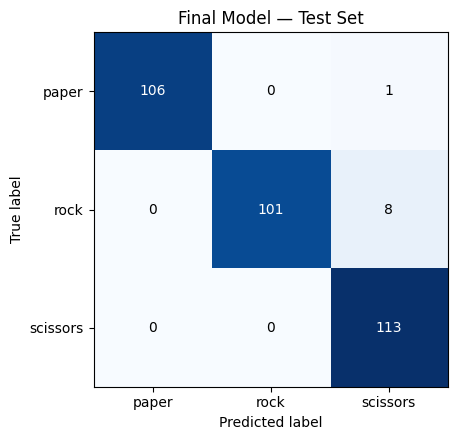

In [179]:
print(classification_report(y_test, y_test_pred))
display(per_class_metrics(y_test, y_test_pred).round(4))

cm = confusion_matrix(y_test, y_test_pred)
fig, axis = plt.subplots(figsize=(5.5, 4.5))
plot_confusion_matrix(cm, CLASS_NAMES, ax=axis, title="Final Model — Test Set")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/final_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Save Final Results

In [180]:
prediction_df = test_df[["relative_path", "label", "label_index"]].rename(columns={"label_index": "true_index"}).copy()
prediction_df["pred_index"] = y_test_pred
prediction_df["confidence"] = test_probabilities.max(axis=1)
for class_index, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_name}"] = test_probabilities[:, class_index]

report_df = pd.DataFrame(classification_report(y_test, y_test_pred, output_dict=True)).T

save_metrics(final_row, f"{RESULTS_DIR}/metrics/final_test_results.csv")
save_metrics(prediction_df, f"{RESULTS_DIR}/metrics/final_test_predictions.csv")
report_df.to_csv(f"{RESULTS_DIR}/metrics/final_classification_report.csv")
print("Saved model: ", f"{RESULTS_DIR}/models/cnn_final.keras")

Saved: ../results/metrics/final_test_results.csv
Saved: ../results/metrics/final_test_predictions.csv
Saved model:  ../results/models/cnn_final.keras


## Conclusions

* The final model was trained with a locked configuration and evaluated once on the untouched test set.
* The test-set metrics above are the unbiased estimate of performance for this pipeline; they are subject to sampling uncertainty (see the bootstrap interval in Lesson 15).
* **Next:** Lesson 20 assembles the final report.

# Part 20 — Final Results and Report

## Learning Objectives

* Summarise the dataset, methodology, results and limitations
* Present tables and figures generated from real saved results
* Discuss findings without claims beyond what the data show

**Prerequisites:** run Lessons 1–19. Every number in this report is read from files produced by executed notebooks; if a file is missing an explicit error is raised.

In [181]:
import gc
import sys

# Release memory: remove variables, models and figures left over by the previous part.
# Every part imports what it needs and reloads its own data, so nothing is lost.
_protected = {"In", "Out", "get_ipython", "exit", "quit", "gc", "sys"}
for _name in list(globals()):
    if not _name.startswith("_") and _name not in _protected:
        del globals()[_name]
if "matplotlib.pyplot" in sys.modules:
    sys.modules["matplotlib.pyplot"].close("all")
if "tensorflow" in sys.modules:
    sys.modules["tensorflow"].keras.backend.clear_session()
gc.collect()

0

## 1. Imports

In [182]:
import os
import sys
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Make the reusable modules in ../src importable
sys.path.append(os.path.abspath(".."))

from src.preprocessing import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    RANDOM_STATE,
    get_partition,
    get_split_dataframe,
    load_images,
    normalize_images,
)
from src.evaluation import (
    build_results_row,
    calculate_metrics,
    classification_report,
    confusion_matrix,
    plot_confusion_matrix,
    save_metrics,
)

import tensorflow as tf
from PIL import Image

from src.evaluation import (
    find_last_conv_layer,
    make_gradcam_heatmap,
    overlay_heatmap,
    per_class_metrics,
)

## 2. Dataset

In [183]:
RESULTS_DIR = "../results"
for subdirectory in ("figures", "metrics", "features", "models"):
    os.makedirs(os.path.join(RESULTS_DIR, subdirectory), exist_ok=True)

# Download the dataset (cached by KaggleHub after the first run)
dataset_path = kagglehub.dataset_download(
    "drgfreeman/rockpaperscissors"
)
print("Dataset path:", dataset_path)

# Load the permanent stratified split (created once in Lesson 1; created here if missing)
dataset_root, split_df = get_split_dataframe(
    dataset_path,
    split_path=f"{RESULTS_DIR}/metrics/dataset_split.csv",
)

train_df = get_partition(split_df, "train")
validation_df = get_partition(split_df, "validation")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("The test partition is not loaded in this notebook.")


def require(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing {path}; run the earlier lessons first.")
    return path

Dataset path: /kaggle/input/datasets/drgfreeman/rockpaperscissors
Multiple candidate dataset roots found; using the first one:
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors
  - /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
Loaded permanent split from ../results/metrics/dataset_split.csv
Training images: 1531
Validation images: 328
The test partition is not loaded in this notebook.


In [184]:
print("Total images in the split:", len(split_df))

class_table = split_df["label"].value_counts().reindex(CLASS_NAMES).to_frame("count")
class_table["percentage"] = (class_table["count"] / len(split_df) * 100).round(2)
display(class_table)

split_table = pd.crosstab(split_df["split"], split_df["label"], margins=True)[CLASS_NAMES + ["All"]]
display(split_table.loc[["train", "validation", "test", "All"]])

Total images in the split: 2188


,count,percentage
label,,
paper,712,32.54
rock,726,33.18
scissors,750,34.28


label,paper,rock,scissors,All
split,,,,
train,498,508,525,1531
validation,107,109,112,328
test,107,109,113,329
All,712,726,750,2188


## 3. Methodology

```text
Dataset
↓
Preprocessing
↓
Feature Extraction
↓
Traditional ML
↓
ANN
↓
CNN
↓
Transfer Learning
↓
Hybrid Model
↓
Tuning
↓
Final Model
↓
Test Evaluation
```

* **Training data** fits model parameters and preprocessing objects.
* **Validation data** compares models and selects configurations.
* **Test data** was reserved for the final, single evaluation (Lesson 19).
* Preprocessing objects were fitted on training data only; augmentation was applied to training data only; all experiments share the permanent stratified split with `RANDOM_STATE = 42`.

## 4. Results — Model Comparison (Validation Set)

In [185]:
comparison_df = pd.read_csv(require(f"{RESULTS_DIR}/metrics/model_comparison.csv"))

columns = ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
           "parameter_count", "training_time_sec", "inference_time_ms_per_image"]
display(comparison_df[columns].round(4))

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,parameter_count,training_time_sec,inference_time_ms_per_image
0,HOG + Logistic Regression,0.9482,0.9504,0.9476,0.9480,0.9481,NaN,1.1996,6.1877
1,HOG + SVM,0.9665,0.9679,0.9659,0.9662,0.9663,NaN,11.3497,15.5045
2,HOG + Random Forest,0.9421,0.9427,0.9417,0.9420,0.9420,NaN,12.4211,6.3264
3,ANN,0.7744,0.8008,0.7743,0.7785,0.7776,3179267.0,14.8333,1.3527
4,Baseline CNN,0.9817,0.9820,0.9814,0.9815,0.9816,3305027.0,32.2817,2.8464
5,Augmented CNN,0.9878,0.9877,0.9877,0.9877,0.9878,3305923.0,187.7973,3.5162
6,MobileNetV2,0.9970,0.9971,0.9969,0.9970,0.9970,2422339.0,105.1428,27.7889
7,CNN + HOG Hybrid,0.9878,0.9879,0.9877,0.9877,0.9878,5444547.0,8.5888,8.1784
8,Tuned CNN,0.9695,0.9706,0.9694,0.9696,0.9695,3305923.0,28.9975,0.9619
9,KerasTuner CNN,0.9878,0.9877,0.9878,0.9878,0.9878,2619043.0,NaN,1.1156


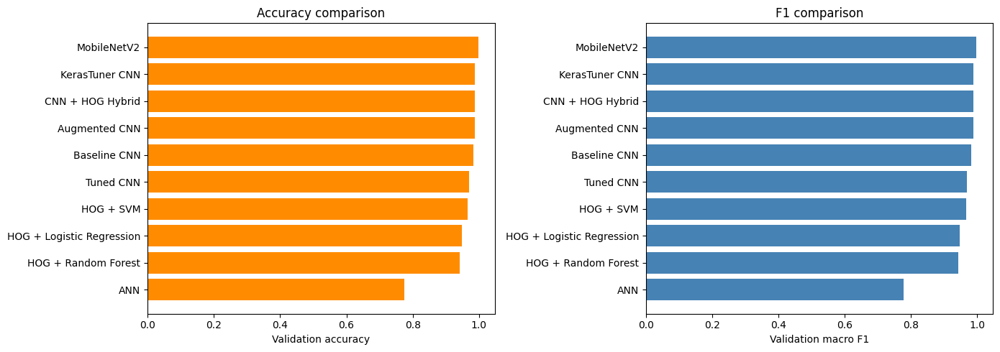

In [186]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = comparison_df.sort_values("f1_macro")
axes[0].barh(plot_df["model"], plot_df["accuracy"], color="darkorange")
axes[0].set_xlabel("Validation accuracy"); axes[0].set_title("Accuracy comparison")
axes[1].barh(plot_df["model"], plot_df["f1_macro"], color="steelblue")
axes[1].set_xlabel("Validation macro F1"); axes[1].set_title("F1 comparison")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/report_accuracy_f1_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Results — Training Curves

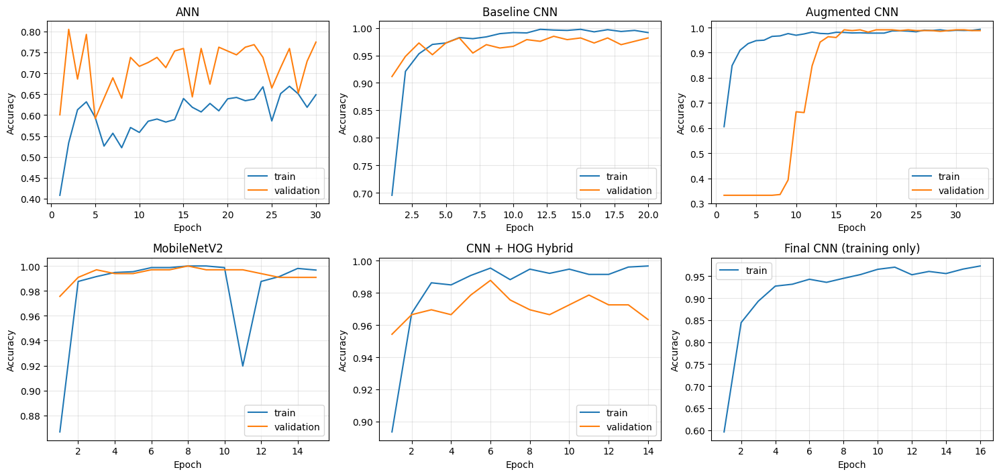

In [187]:
history_files = {
    "ANN": "ann_history.csv",
    "Baseline CNN": "cnn_baseline_history.csv",
    "Augmented CNN": "cnn_augmented_history.csv",
    "MobileNetV2": "mobilenetv2_history.csv",
    "CNN + HOG Hybrid": "hybrid_history.csv",
    "Final CNN (training only)": "cnn_final_history.csv",
}
available_histories = {name: pd.read_csv(f"{RESULTS_DIR}/metrics/{file}", index_col="epoch")
                       for name, file in history_files.items()
                       if os.path.exists(f"{RESULTS_DIR}/metrics/{file}")}

n_panels = len(available_histories)
n_rows = int(np.ceil(n_panels / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 3.6 * n_rows), squeeze=False)
for axis in axes.ravel():
    axis.axis("off")
for axis, (name, history_df) in zip(axes.ravel(), available_histories.items()):
    axis.axis("on")
    axis.plot(history_df.index, history_df["accuracy"], label="train")
    if "val_accuracy" in history_df:
        axis.plot(history_df.index, history_df["val_accuracy"], label="validation")
    axis.set_title(name); axis.set_xlabel("Epoch"); axis.set_ylabel("Accuracy"); axis.legend(); axis.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/report_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Results — Final Model on the Test Set

,model,evaluation_split,accuracy,precision_weighted,recall_weighted,f1_weighted,precision_macro,recall_macro,f1_macro,parameter_count,training_time_sec,inference_time_ms_per_image
0,Final CNN,test,0.9726,0.9747,0.9726,0.9727,0.9754,0.9724,0.973,3305923,115.3791,3.5992


              precision    recall  f1-score   support

       paper       1.00      0.99      1.00       107
        rock       1.00      0.93      0.96       109
    scissors       0.93      1.00      0.96       113

    accuracy                           0.97       329
   macro avg       0.98      0.97      0.97       329
weighted avg       0.97      0.97      0.97       329



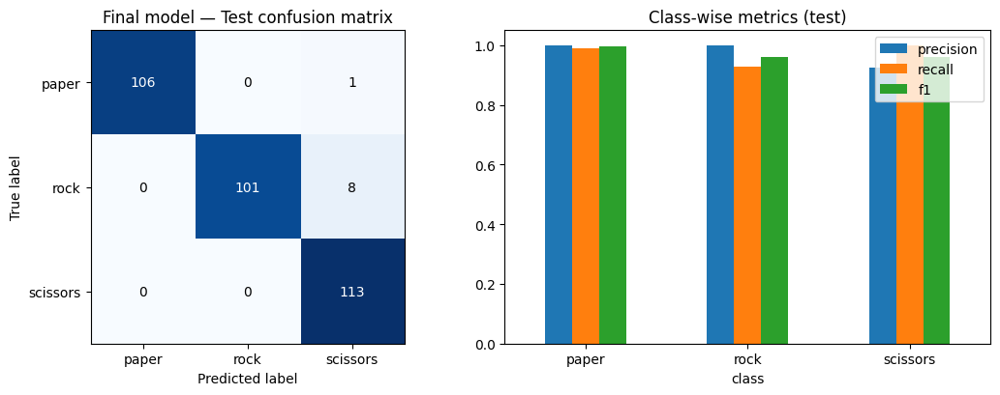

,class,precision,recall,f1,support
0,paper,1.0000,0.9907,0.9953,107
1,rock,1.0000,0.9266,0.9619,109
2,scissors,0.9262,1.0000,0.9617,113


In [188]:
final_results = pd.read_csv(require(f"{RESULTS_DIR}/metrics/final_test_results.csv"))
display(final_results.round(4))

predictions_df = pd.read_csv(require(f"{RESULTS_DIR}/metrics/final_test_predictions.csv"))
y_test = predictions_df["true_index"].to_numpy()
y_test_pred = predictions_df["pred_index"].to_numpy()

print(classification_report(y_test, y_test_pred))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_test, y_test_pred)
plot_confusion_matrix(cm, CLASS_NAMES, ax=axes[0], title="Final model — Test confusion matrix")
class_metrics = per_class_metrics(y_test, y_test_pred)
class_metrics.set_index("class")[["precision", "recall", "f1"]].plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_ylim(0, 1.05); axes[1].set_title("Class-wise metrics (test)")
plt.tight_layout()
plt.show()
display(class_metrics.round(4))

## 7. Results — Error Examples and Grad-CAM (Final Model, Test Images)

Number of test errors: 9


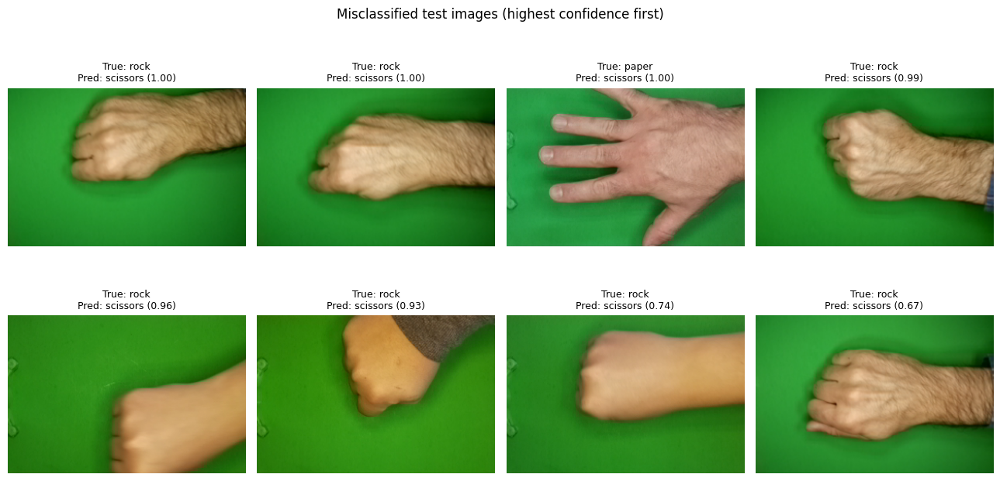

In [189]:
IMAGE_SIZE = (128, 128)
final_model = tf.keras.models.load_model(require(f"{RESULTS_DIR}/models/cnn_final.keras"))

errors_df = predictions_df[predictions_df["true_index"] != predictions_df["pred_index"]].sort_values("confidence", ascending=False)
print("Number of test errors:", len(errors_df))

if len(errors_df) > 0:
    shown = errors_df.head(8)
    fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, (_, row) in zip(axes.ravel(), shown.iterrows()):
        with Image.open(os.path.join(dataset_root, row["relative_path"])) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(f"True: {CLASS_NAMES[int(row['true_index'])]}\nPred: {CLASS_NAMES[int(row['pred_index'])]} ({row['confidence']:.2f})", fontsize=9)
    plt.suptitle("Misclassified test images (highest confidence first)")
    plt.tight_layout()
    plt.show()

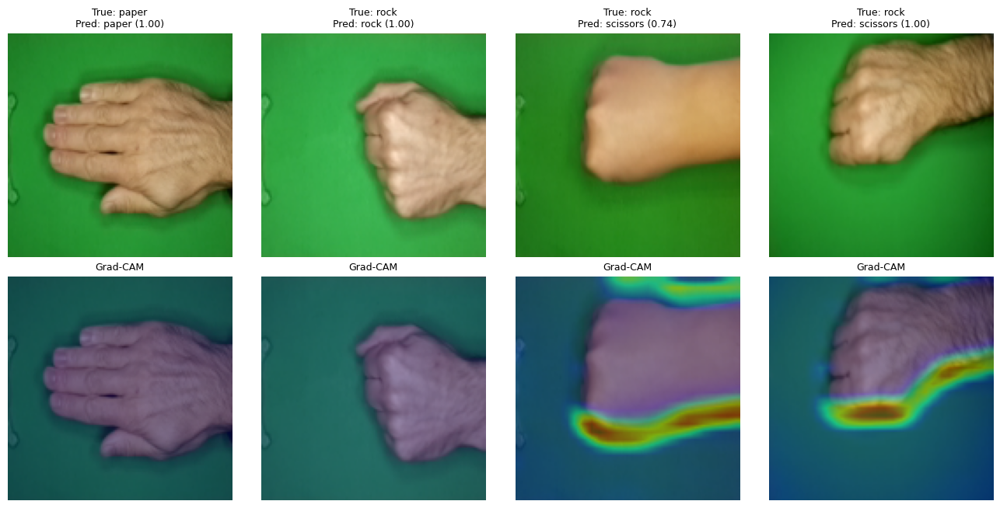

In [190]:
# Grad-CAM examples: up to two correct and two incorrect test images (Grad-CAM is a qualitative diagnostic, not proof of causality)
rng = np.random.default_rng(RANDOM_STATE)
correct_ids = predictions_df.index[predictions_df["true_index"] == predictions_df["pred_index"]].to_numpy()
wrong_ids = predictions_df.index[predictions_df["true_index"] != predictions_df["pred_index"]].to_numpy()
selected_ids = list(rng.permutation(correct_ids)[:2]) + list(rng.permutation(wrong_ids)[:2])

last_conv = find_last_conv_layer(final_model)
fig, axes = plt.subplots(2, len(selected_ids), figsize=(3.3 * len(selected_ids), 6.6), squeeze=False)
for column, row_id in enumerate(selected_ids):
    row = predictions_df.loc[row_id]
    image_uint8 = load_images(dataset_root, [row["relative_path"]], IMAGE_SIZE)[0]
    heatmap = make_gradcam_heatmap(normalize_images(image_uint8[np.newaxis]), final_model, last_conv, class_index=int(row["pred_index"]))
    axes[0, column].imshow(image_uint8)
    axes[0, column].set_title(f"True: {CLASS_NAMES[int(row['true_index'])]}\nPred: {CLASS_NAMES[int(row['pred_index'])]} ({row['confidence']:.2f})", fontsize=9)
    axes[1, column].imshow(overlay_heatmap(image_uint8, heatmap))
    axes[1, column].set_title("Grad-CAM", fontsize=9)
    axes[0, column].axis("off"); axes[1, column].axis("off")
plt.tight_layout()
plt.show()

## 8. Findings Computed from the Saved Results

The statements below are generated by code from the comparison table (validation macro F1 unless stated). They report differences from single training runs and should be read together with the uncertainty analysis in Lesson 15.

In [191]:
def macro_f1(model_name):
    rows = comparison_df[comparison_df["model"] == model_name]
    return float(rows["f1_macro"].iloc[0]) if len(rows) else None


def describe_difference(model_a, model_b):
    score_a, score_b = macro_f1(model_a), macro_f1(model_b)
    if score_a is None or score_b is None:
        print(f"{model_a} vs {model_b}: at least one result is not available.")
    else:
        print(f"{model_a} ({score_a:.4f}) vs {model_b} ({score_b:.4f}): difference = {score_a - score_b:+.4f}")


best_row = comparison_df.sort_values("f1_macro", ascending=False).iloc[0]
print(f"Highest validation macro F1: {best_row['model']} ({best_row['f1_macro']:.4f})")

traditional = comparison_df[comparison_df["model"].str.startswith("HOG")]
deep = comparison_df[~comparison_df["model"].str.startswith("HOG")]
if len(traditional) and len(deep):
    print(f"Best traditional model: {traditional.sort_values('f1_macro').iloc[-1]['model']} ({traditional['f1_macro'].max():.4f})")
    print(f"Best neural model: {deep.sort_values('f1_macro').iloc[-1]['model']} ({deep['f1_macro'].max():.4f})")

describe_difference("Augmented CNN", "Baseline CNN")
describe_difference("MobileNetV2", "Baseline CNN")
describe_difference("CNN + HOG Hybrid", "Baseline CNN")
describe_difference("Baseline CNN", "ANN")

Highest validation macro F1: MobileNetV2 (0.9970)
Best traditional model: HOG + SVM (0.9662)
Best neural model: MobileNetV2 (0.9970)
Augmented CNN (0.9877) vs Baseline CNN (0.9815): difference = +0.0062
MobileNetV2 (0.9970) vs Baseline CNN (0.9815): difference = +0.0154
CNN + HOG Hybrid (0.9877) vs Baseline CNN (0.9815): difference = +0.0062
Baseline CNN (0.9815) vs ANN (0.7785): difference = +0.2031


## 9. Discussion

**Approaches tested.** The project progressed from classical image processing (Lesson 2), through handcrafted HOG features with Logistic Regression, SVM and Random Forest (Lesson 3), to a fully connected network on raw pixels (Lesson 4), a baseline CNN (Lesson 5), augmentation with Batch Normalisation and callbacks (Lesson 6), MobileNetV2 transfer learning (Lesson 7) and a CNN + HOG hybrid (Lesson 8). Explainability (Lesson 9), ablation (Lesson 11), manual and automated tuning (Lessons 12–13), an augmentation experiment (Lesson 14), uncertainty estimation (Lesson 15), cross-validation (Lesson 16) and error analysis (Lesson 17) refined the methodology.

**Traditional ML versus deep learning.** Section 8 reports the measured difference between the best traditional and best neural model. Handcrafted HOG features encode local shape with fixed, hand-designed rules and train quickly; CNNs learn their features from data at a higher computational cost. Which is preferable depends on the measured gap and on the training and inference costs in the comparison table.

**Effect of augmentation.** Lessons 11 and 14 isolate this effect; consult those tables and the augmentation line in Section 8. Because each configuration was trained once, small differences may be within seed variability (Lesson 15).

**Effect of transfer learning.** Compare MobileNetV2 with the CNNs trained from scratch in the table and in Section 8, keeping in mind its much larger parameter count and different input size.

**Effect of HOG + CNN hybrid features.** Compare the hybrid with the CNN that supplies its features (Section 8). Note that the CNN features on training images come from a network trained on those images, which limits how much the training data can reveal about the hybrid's benefit.

**Main error patterns.** Use the confusion matrix, error gallery and Lesson 17 to identify which classes are confused and whether errors are confident. Grad-CAM offers a qualitative view of regions influencing predictions but does not establish causality.

**Limitations.**

* A single stratified split and mostly single training runs; differences between close models are unreliable.
* The validation set (15% of the data) was used for all model and hyperparameter selection, so validation scores are optimistically biased; only the test estimate in Lesson 19 is unbiased, and it carries its own sampling uncertainty because the test set is small.
* The dataset comes from one source with a limited range of conditions, so results may not generalise to other cameras, backgrounds, lighting or hands.
* Only exact duplicates were removed; near-duplicate images could remain across partitions.
* Timing values depend on the hardware used.

**Possible future improvements.**

* Repeated or nested cross-validation and multiple seeds for all models, with statistical comparison of models.
* Evaluation on an independent external dataset or on newly collected images.
* Stronger regularisation and augmentation such as colour jitter, and other pre-trained backbones.
* Calibration of predicted probabilities and quantitative Grad-CAM evaluation.